# MSc in AI Capstone #7: Industry-Integrated AI Systems Synthesis
## Integrated Industry Synthesis: A Governed Question Lifecycle for HKDSE ICT Paper 1A

**Version v0.95: full notebook, frozen.** This is the complete, detailed notebook (Tasks 1-5 drafted). It is kept unchanged as the reference version; the trimmed submission version is built from it as v1.0.

*Working title:* Statistically grounded classification, generation, verification and adaptive delivery of exam-practice items under teacher governance.

| Task | Content | Status |
|---|---|---|
| 1 | Industry and problem space | Drafted below |
| 2 | Integration plan | Drafted below |
| 3 | System architecture and design | Drafted below |
| 4 | Construct the applied artifact | Built and run: `src/data.py`, `src/store.py` and the blind-label and label-review sheets in `src/review.py` are built and tested, the teacher's 30 blind labels are collected and imported, the module classifier is built and evaluated, and the store set-up and the classifier's proposals have their own steps (Sections 2.8 and 4.0 to 4.2), and the teacher has approved labels for all 48 remaining questions through the review sheet (Section 4.3), gap detection in `src/stats.py` is built and tested (Section 4.4), the gate's deterministic checks in `src/gate.py` are built and tested (Section 4.5), the generator and the storage of candidates are built and tested (Sections 4.6 and 4.7), the Kaggle bake-off produced 54 candidates that were stored and gated (Section 4.8), the teacher's candidate review sheet and its import are built and tested (Section 4.9), the teacher's review of the 46 candidates is imported and reported (Section 4.10), and the student-side tutor, its rule router and 14 scripted scenarios are built and run (Section 4.11); the chat page is built and tested (Section 4.12); the language-model Orchestrator with its Explainer worker, the tutor's second router, is built, tested offline with a stub client and run live on twelve fixed messages (Section 4.13) |
| 5 | Evaluation | Drafted below (Section 5: the answer to the central question, the four gaps and each clause measured, check 7, strengths, failure cases, trade-offs and limitations) |

**How the artifact is organised.** This notebook is the primary artifact. Reusable logic will live in importable modules under `src/` so that this notebook and an optional Streamlit front end call the same code. The front end (Streamlit, approved by my mentor) adds no AI method and contains no logic of its own.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python      :", sys.version.split()[0])
print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("Matplotlib  :", matplotlib.__version__)

# Needed from Task 4 on (the Excel sheet and the classifier)
import importlib.util
import importlib.metadata as md

for module, pip_name in {"openpyxl": "openpyxl", "sklearn": "scikit-learn"}.items():
    if importlib.util.find_spec(module) is None:
        print(f"{pip_name:12s}: MISSING -> run  %pip install {pip_name}  then re-run this cell")
    else:
        print(f"{pip_name:12s}:", md.version(pip_name))

Python      : 3.12.0
NumPy       : 2.5.4
Pandas      : 3.0.6
Matplotlib  : 3.11.2
openpyxl    : 3.1.5
scikit-learn: 1.9.1


---
# Task 1 - Industry and Problem Space

## 1.1 Industry and context

**Industry:** Education, specifically secondary-school examination preparation.
**Use case:** Practice for the Hong Kong Diploma of Secondary Education (HKDSE) Information and Communication Technology (ICT) Paper 1A, a 40-question multiple-choice paper.
**Data:** The 560-question bank of Paper 1A past papers (2012-2025) published by the Hong Kong Examinations and Assessment Authority (HKEAA) and used in Capstones 5 and 6, with the schema documented in `fields_explanation.md` (v1.7). Each row (primary key `qn_id`) holds the question text, four options, the official key (`*` for a withdrawn question), a semicolon-delimited curriculum classification (`qn_type_id`, in which the first letter of each tag gives the module A-E, or the reserved token `unclassified`), a difficulty proxy (`cohort_pct`, the share of the cohort answering correctly), question-body and answer-option image references (`qn_image_filename`, `ans_image_filename`), and a cluster flag with the verbatim shared preamble (`cluster`, `cluster_desc`) for questions that share a passage, diagram or algorithm. Images of code were converted to text blocks by OCR, so those questions are treated as text; images of figures and tables were not converted. Each question has one *primary module*, the module of its first tag.

Reusing one domain and one bank across Capstones 5, 6 and 7 is deliberate. The brief asks for integration of *methods*, and a single coherent story is stronger evidence of intentional system design than three unrelated pieces.

## 1.2 The problem

My Capstone 6 tutor serves a finite bank of past-paper questions, and my Capstone 5 generator could extend it. The two earlier reports expose four gaps:

1. **The usable bank is small and uneven.** Capstone 6 used 519 questions (2012-2024). It excluded the whole 2025 paper (40 questions, none yet classified) and one withdrawn item, and it kept 38 other unclassified questions under a "general knowledge" tag. Of the 519, 26 questions form 13 pairs that share a diagram or description and are always served together as one unit, so pools should be counted in *units*. Some sub-topics are very thin: `d_cp_02` has 3 questions and a fourth request returned nothing, because the tutor has no fallback policy for an exhausted pool (a gap Capstone 6 itself listed as a future improvement). The curriculum is also imbalanced: in the full file, counting each question once under its primary module, Module A has 154 questions and Module E only 50.
2. **Generation exists but is not trustworthy, and it is weakest where demand is highest.** The Capstone 5 LoRA-tuned TinyLlama produced a valid format in 18 of 20 samples (the base model in 0 of 20), but only 1 of the 10 samples I read by hand was usable without editing, and four had no single defensible answer. Failures fell into three groups: runaway generation, incoherent stems, and weak assessment design (overlapping distractors, no correct option, a given-away answer). The model was conditioned on module and question type only, so it had no difficulty control and produced no answer key. Its evaluation used only the two most frequent types per module, so it says little about the thin sub-topics where new items are most needed.
3. **Difficulty is only a proxy.** `cohort_pct` describes how past cohorts performed. It is not calibrated across years and also reflects who sat each paper, and a newly generated item has no value for it at all.
4. **Safeguards stop at the tool level.** In Capstone 6, tools returned correct figures but the final reply mis-ranked sub-topics (Scenario 7). Any label that matters, such as "provisional", must therefore be added by code, not left to the wording of a model.

## 1.3 Central question

> Can classified and generated practice items be added to an adaptive tutor's question bank safely, when every known weakness (missing labels, no answer key, weak distractors) is addressed by a measurable check and a human decision, with difficulty left honestly unknown?

The aim is not a model that writes perfect questions. It is a *governed lifecycle* in which AI proposes, statistics and classifiers check, a teacher decides, and the tutor serves only what has been admitted and labels it honestly.

## 1.4 Why this problem suits an AI-based solution

- **Fixed supply, continuous demand.** Past papers are finite and cannot be re-issued, while students need targeted practice for specific topics.
- **Structured data.** Curriculum modules and sub-topics, cohort difficulty and cluster fields give each AI method something concrete to work on.
- **Each method addresses a different part of the problem.** Statistics measures and tests, classification labels, generation supplies, and an agentic tutor delivers and adapts. No single technique covers the whole problem, and Capstone 5 showed that generation alone is unsafe.

## 1.5 Constraints, risks and ethical considerations

| Area | Concern in this system | Planned response (detailed in Task 3) |
|---|---|---|
| Assessment integrity | A wrong key or a distractor that is also correct teaches a student something false, and the learner cannot tell | The teacher answers every candidate blind to the generator's key, deterministic distractor checks, mandatory teacher approval |
| Provenance | A generated item could be mistaken for an HKEAA past-paper question and misrepresent the authority's material | Every generated item carries an "AI-drafted, teacher-approved, not an HKEAA question" label added by the render tool |
| Difficulty | `cohort_pct` is not calibrated across years, and a generated item has no difficulty value at all; showing a guess as a measurement would mislead students and teachers | Generated items carry no difficulty value; they are labelled provisional with their provenance; year-aware comparisons for real items |
| Over-trust in fluent output | Correct figures delivered in an incorrect sentence (Capstone 6, Scenario 7) are more likely to be believed | Labels and keys come from tools, not model wording; teacher oversight; guarantees described at the tool level only |
| Intellectual property | HKEAA questions are copyright material, used here for non-commercial study only; a generator may memorise or imitate them | Near-copy detection against the bank; the bank is shared (on Kaggle) only after Tasks 4 and 5 are complete, with its HKEAA source and copyright stated; wording to be checked against Hong Kong's fair-dealing provisions before the paper |
| Bias and equity | Module A has 154 questions and Module E 50; thin sub-topics and the roughly one question in ten that depends on a figure and the 32 table-only questions (neither converted to text) are under-served; classifier and generator quality may differ by module | Per-module and per-year error analysis; macro-averaged metrics; abstention instead of forced labels |
| Context-less items | Serving one member of a shared-context cluster, or a generated item that refers to a missing passage, leaves a student without the information needed | Clusters always served whole; generated items must be standalone; check for dangling references |
| Multi-label credit | Crediting every tag on a multi-label question blurs attribution (both tags of the 2023 Q28/Q29 pair move together) | Kept as a documented simplification; predicted module-only labels never update tag-level mastery |
| Minors' data | A deployed tutor would hold attempt records of secondary students, and its Model mode sends what a student types to an external AI service | No real student data in this project and no attempt records are stored; Model mode is off unless a key is set (Rules mode is the default) and would need consent first (Sections 4.12.4 and 4.13.7); consent and data minimisation noted as deployment conditions (Hong Kong's Personal Data (Privacy) Ordinance, to be cited in the paper) |
| Accountability | A model cannot own the correctness of an exam item | A named teacher approves every item and every predicted label before it affects the tutor |
| Scope honesty | There are no real student outcomes, so learning gains cannot be claimed | Evaluation limited to item quality, gate behaviour, classifier accuracy and tool-level behaviour |

## 1.6 Scope

**In scope:** text-only, standalone multiple-choice items (code-only images count as text); single-label module classification, one primary module per question (sub-topic only where confidence is high and the sub-topic has at least 15 training questions); candidate generation and verification; teacher review; adaptive delivery of admitted items; statistical comparison of generated versus real items.

**Out of scope:** figure-aware generation or image interpretation (figure and table images were not converted to text); generating shared-context clusters; answer keys treated as authoritative; students requesting new questions from the tutor (generation is a staff-side activity); any deployment or learning-outcome claim; real student data.

## 1.7 Evidence from the question bank

The next cell quantifies the problem from the actual data, so the claims in Section 1.2 are checked rather than asserted. It needs `data/final_dataset.csv` (the schema described in Section 1.1) and, for the second cell, `data/taxonomy.csv`. It counts clusters as single units and each question once, and treats `;` as the list delimiter in `qn_type_id` and in the image fields.

> **Assumptions to confirm:** the year is read from `qn_id` (pattern `ICT_2021_paper1a_q01`) unless a year column exists, and each question's primary module is the module of its first tag (`d_cp_02` gives module D). Tags are stored in ascending order, so for the questions that span several modules this is an alphabetical convention. The first cell prints what it finds and fails softly if the file or the cluster columns are missing. A second cell lists the taxonomy sub-topics that have no question or very few.

,count
Questions in file,560
2025 questions (all unclassified),40
Withdrawn questions (key = *),1
"Capstone 6 usable bank (no 2025, no withdrawn)",519
served units (a cluster counts once),506
clusters served as one unit,13 clusters covering 26 questions
"unclassified, kept as general knowledge",38
Upper bound if 2025 is classified and approved,559



Questions with a question-body image : 25.9%
Questions with an answer-option image: 0.9%
Questions with any image             : 25.9%
Questions with several body images (semicolon list): 6

Body images by type: code only 53 (OCR-converted, treated as text), involving a figure 58, table only 32, other mixes 2
Still image-dependent after code conversion: 92 (16.4% of the file)

Questions per primary module (full file): {'A': 154, 'B': 84, 'C': 119, 'D': 74, 'E': 50} | unclassified: 79
Questions touching each module, for reference: {'A': 154, 'B': 93, 'C': 141, 'D': 75, 'E': 53} | questions spanning more than one module: 33

Smallest sub-topic pools in the Capstone 6 bank:


,units,questions
tags,,
d_cp_02,3,3
b_cs_05,8,8
d_cp_05,9,9
a_ip_01,11,11
d_cp_01,12,12
e_si_02,12,12
c_ia_06,14,14
d_cp_04,14,15


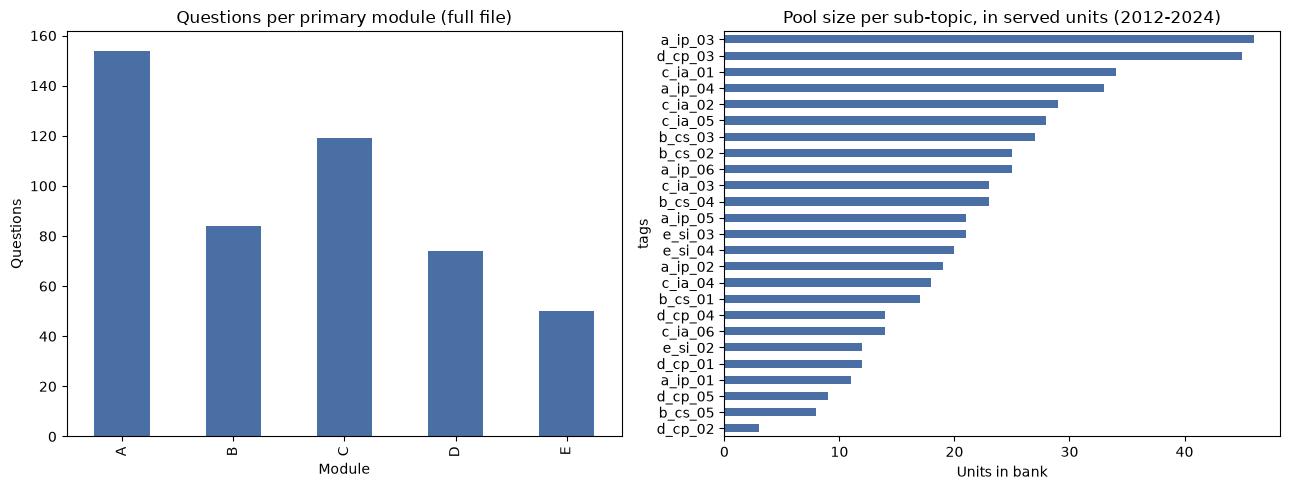

In [2]:
DATA_PATH = Path("data/final_dataset.csv")


def find_year(df):
    for c in ("paper_year", "year"):
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce")
    return pd.to_numeric(df["qn_id"].astype(str).str.extract(r"(20\d{2})")[0], errors="coerce")


def split_list(v):
    if pd.isna(v) or str(v).strip() == "":
        return []
    return [t.strip() for t in str(v).split(";") if t.strip()]


def nonblank(df, col):
    if col not in df.columns:
        return pd.Series(False, index=df.index)
    return df[col].notna() & (df[col].astype(str).str.strip() != "")


def show(obj):
    try:
        display(obj)
    except NameError:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


if not DATA_PATH.exists():
    print(f"[skipped] {DATA_PATH} not found. Place the Kaggle file there and re-run this cell.")
    bank = None
else:
    bank = pd.read_csv(DATA_PATH)
    bank["year"] = find_year(bank)
    bank["tags"] = bank["qn_type_id"].apply(split_list)
    real_tags = bank["tags"].apply(lambda L: [t for t in L if t.lower() != "unclassified"])
    bank["unlabelled"] = real_tags.apply(len) == 0
    bank["modules"] = real_tags.apply(lambda L: sorted({t.split("_")[0].upper() for t in L}))
    bank["primary_module"] = real_tags.apply(lambda L: L[0].split("_")[0].upper() if L else None)  # first tag

    withdrawn = bank["correct_answer"].astype(str).str.strip() == "*"
    is_2025 = bank["year"] == 2025
    c6 = bank[~is_2025 & ~withdrawn].copy()

    has_cluster = {"cluster", "cluster_desc"}.issubset(bank.columns)
    if not has_cluster:
        print("[note] cluster / cluster_desc columns not found: treating every question as a standalone unit.")

    def unit_key(r):
        if has_cluster and r["cluster"] == 1 and isinstance(r["cluster_desc"], str) and r["cluster_desc"].strip():
            return "cluster::" + r["cluster_desc"].strip()
        return r["qn_id"]

    c6["unit"] = c6.apply(unit_key, axis=1)
    cl_sizes = c6[c6["unit"].str.startswith("cluster::")].groupby("unit").size()

    summary = pd.DataFrame({"count": [
        len(bank),
        int(is_2025.sum()),
        int(withdrawn.sum()),
        len(c6),
        c6["unit"].nunique(),
        f"{len(cl_sizes)} clusters covering {int(cl_sizes.sum())} questions",
        int(c6["unlabelled"].sum()),
        int((~withdrawn).sum()),
    ]}, index=[
        "Questions in file",
        "2025 questions (all unclassified)",
        "Withdrawn questions (key = *)",
        "Capstone 6 usable bank (no 2025, no withdrawn)",
        "  served units (a cluster counts once)",
        "  clusters served as one unit",
        "  unclassified, kept as general knowledge",
        "Upper bound if 2025 is classified and approved",
    ])
    show(summary)

    img_q, img_a = nonblank(bank, "qn_image_filename"), nonblank(bank, "ans_image_filename")
    print(f"\nQuestions with a question-body image : {img_q.mean():.1%}")
    print(f"Questions with an answer-option image: {img_a.mean():.1%}")
    print(f"Questions with any image             : {(img_q | img_a).mean():.1%}")
    if "qn_image_filename" in bank.columns:
        multi = bank["qn_image_filename"].astype(str).str.count(";").gt(0) & img_q
        print(f"Questions with several body images (semicolon list): {int(multi.sum())}")
    if "qn_image_type" in bank.columns:
        itypes = bank["qn_image_type"].apply(lambda v: set(split_list(v)))
        code_only = img_q & itypes.apply(lambda s: s == {"code"})
        has_figure = img_q & itypes.apply(lambda s: "figure" in s)
        table_only = img_q & itypes.apply(lambda s: s == {"table"})
        other_mix = img_q & ~code_only & ~has_figure & ~table_only
        print(f"\nBody images by type: code only {int(code_only.sum())} (OCR-converted, treated as text), "
              f"involving a figure {int(has_figure.sum())}, table only {int(table_only.sum())}, other mixes {int(other_mix.sum())}")
        print(f"Still image-dependent after code conversion: {int((img_q & ~code_only).sum())} "
              f"({(img_q & ~code_only).mean():.1%} of the file)")

    # one primary module per question; the count of every module a question touches is printed for reference
    mod_counts = bank["primary_module"].dropna().value_counts().sort_index()
    touch_counts = bank.explode("modules")["modules"].dropna().value_counts().sort_index()
    print("\nQuestions per primary module (full file):", mod_counts.to_dict(), "| unclassified:", int(bank["unlabelled"].sum()))
    print("Questions touching each module, for reference:", touch_counts.to_dict(),
          "| questions spanning more than one module:", int((bank["modules"].apply(len) > 1).sum()))

    # sub-topic pools in served units (a unit carries the union of its members' tags)
    unit_tags = c6.groupby("unit")["tags"].apply(lambda s: sorted({t for L in s for t in L if t.lower() != "unclassified"}))
    pools_units = unit_tags.explode().dropna().value_counts()
    pools_q = c6["tags"].explode().dropna().loc[lambda s: s.str.lower() != "unclassified"].value_counts()
    pools = pd.DataFrame({"units": pools_units, "questions": pools_q}).fillna(0).astype(int).sort_values("units")
    print("\nSmallest sub-topic pools in the Capstone 6 bank:")
    show(pools.head(8))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    mod_counts.plot.bar(ax=axes[0], color="#4a6fa5")
    axes[0].set_title("Questions per primary module (full file)")
    axes[0].set_xlabel("Module")
    axes[0].set_ylabel("Questions")
    pools["units"].plot.barh(ax=axes[1], color="#4a6fa5")
    axes[1].set_title("Pool size per sub-topic, in served units (2012-2024)")
    axes[1].set_xlabel("Units in bank")
    plt.tight_layout()
    plt.show()

In [3]:
TAX_PATH = Path("data/taxonomy.csv")

if bank is None or not TAX_PATH.exists():
    print("[skipped] the bank or data/taxonomy.csv was not found.")
else:
    tax = pd.read_csv(TAX_PATH, dtype=str)
    seen = bank["tags"].explode().dropna().loc[lambda s: s.str.lower() != "unclassified"].value_counts()
    per_tag = tax.set_index("qn_type_id")[["subtopic_name"]].join(seen.rename("questions")).fillna({"questions": 0})
    per_tag["questions"] = per_tag["questions"].astype(int)
    unknown = sorted(set(seen.index) - set(tax["qn_type_id"]))
    print(f"Sub-topics in the taxonomy: {len(tax)} | with at least one question: {int((per_tag['questions'] > 0).sum())}")
    print("Tags in the bank that are not in the taxonomy:", unknown or "none")
    print("\nSub-topics with no question in the file:", per_tag.index[per_tag["questions"] == 0].tolist())
    print("Sub-topics with fewer than 10 questions (including those with none):")
    show(per_tag[per_tag["questions"] < 10].sort_values("questions"))

Sub-topics in the taxonomy: 26 | with at least one question: 25
Tags in the bank that are not in the taxonomy: none

Sub-topics with no question in the file: ['e_si_01']
Sub-topics with fewer than 10 questions (including those with none):


,subtopic_name,questions
qn_type_id,,
e_si_01,Technological Innovations,0
d_cp_02,Data Type,3
b_cs_05,Modes of Operation,8
d_cp_05,Program Testing and Debugging,9


## 1.8 Calibrating the design thresholds from the real bank (C2)

The gate (Section 3.5), gap detection (Section 3.2) and sub-topic prediction (Sections 3.2 and 3.4) all use thresholds. Instead of choosing them by feel, the next cell measures the real bank with descriptive statistics, the Capstone 2 method, and asks one question of every candidate rule: **what is its false-positive rate on real exam questions (assumed acceptable)?** A rule that flags many real questions is too strict for generated ones. How well a rule catches genuinely bad items (its true-positive rate) cannot be measured on real questions; Section 5.1 reports what the teacher's review of the bake-off shows about it.

The reference set is the real, standalone, text-only items with one key and four plain-text options (code-only images count as text; table-formatted options are left out). This is a description of the real bank, not a test against teacher judgement, so every value stays a starting value, and the paper states that as a limitation. The decisions drawn from the numbers are in Sections 2.7, 3.2, 3.5 and 3.6, and in decision 19 of Section 2.5.

In [4]:
import difflib, itertools, re

# One shared parser for the whole project. It removes the paper-end banner ("**END OF PAPER**" /
# "**END OF SECTION A**") that the bank leaves inside option D of Q40, so the banner cannot enter the
# reference set (Appendix A).
sys.path.insert(0, str(Path.cwd()))
from src.data import parse_options

if bank is None or not TAX_PATH.exists():
    print("[skipped] the bank or data/taxonomy.csv was not found.")
else:
    # --- reference set: real standalone, text-only, answerable items with four plain-text options (2012-2024)
    iq, ia = nonblank(bank, "qn_image_filename"), nonblank(bank, "ans_image_filename")
    itype = bank["qn_image_type"].apply(lambda v: set(split_list(v))) if "qn_image_type" in bank.columns else None
    code_txt = iq & itype.apply(lambda s: s == {"code"}) if itype is not None else iq & False
    keep = ((~iq | code_txt) & ~ia & ~bank["answer_options"].astype(str).str.contains("[IMAGE]", regex=False)
            & (bank["correct_answer"].astype(str).str.strip() != "*") & (bank["cluster"] != 1) & (bank["year"] <= 2024))

    ref = bank[keep].copy()
    ref["opts"] = ref["answer_options"].apply(parse_options)
    n_banner = int(ref["answer_options"].astype(str).str.contains("END OF", regex=False).sum())
    assert not ref["opts"].apply(lambda o: any("END OF" in v for v in o.values())).any()
    print(f"Paper-end banner removed from {n_banner} reference items before measuring.")
    ref = ref[ref["opts"].apply(len) == 4].copy()          # table-formatted options are not generation targets
    ref["stem"] = ref["question_text"].apply(lambda t: re.sub(r"\s+", " ", re.sub(r"[*`#]", "", str(t))).strip())
    n_ref = len(ref)
    print(f"Reference set: {n_ref} real items (standalone, text-only, one key, four plain-text options, 2012-2024)\n")

    # 1. length (stem plus options, characters): percentile band for check 1
    total_len = ref.apply(lambda r: len(r["stem"]) + sum(len(v) for v in r["opts"].values()), axis=1)
    p1, p5, p50, p95, p99 = np.percentile(total_len, [1, 5, 50, 95, 99])
    print(f"1. Length (stem + options, characters): 1st pct {p1:.0f} | 5th {p5:.0f} | median {p50:.0f} | 95th {p95:.0f} | 99th {p99:.0f}")
    print("   -> accepted band for check 1 = 1st to 99th percentile (rounded in the gate)\n")

    # 2. option similarity: how many REAL items would each threshold reject?
    sims = ref["opts"].apply(lambda o: max(difflib.SequenceMatcher(None, a.lower(), b.lower()).ratio()
                                            for a, b in itertools.combinations(o.values(), 2)))
    contained = ref["opts"].apply(lambda o: any(a.lower().strip() in b.lower() for a, b in itertools.permutations(o.values(), 2) if a.strip()))
    exact = ref["opts"].apply(lambda o: len({v.lower().strip() for v in o.values()}) < 4)
    print("2. Option similarity: share of REAL items a rule would flag (a good rule flags few real items)")
    for t in (0.8, 0.9, 0.95):
        print(f"   character similarity above {t}: {(sims > t).mean():6.1%}")
    print(f"   one option contained in another : {contained.mean():6.1%}")
    print(f"   exact duplicate options         : {exact.mean():6.1%}\n")

    # 3. key length ratio (keyed option / mean of the other three)
    def key_ratio(r):
        k = str(r["correct_answer"]).strip()
        others = [len(v) for a, v in r["opts"].items() if a != k]
        return len(r["opts"][k]) / np.mean(others) if k in r["opts"] and np.mean(others) > 0 else np.nan
    kr = ref.apply(key_ratio, axis=1)
    print("3. Key length ratio: share of REAL items above each ratio")
    for t in (1.3, 1.5, 2.0):
        print(f"   ratio above {t}: {(kr > t).mean():6.1%}")
    print()

    # 4. copy ratio: share of an item's 6-word sequences that appear in any OTHER real item
    def grams(t, n=6):
        w = re.findall(r"\w+", t.lower())
        return {tuple(w[i:i + n]) for i in range(len(w) - n + 1)}
    G = [grams(r["stem"] + " " + " ".join(r["opts"].values())) for _, r in ref.iterrows()]
    from collections import Counter
    gram_count = Counter(g for s in G for g in s)
    copy_ratio = np.array([(sum(1 for g in s if gram_count[g] > 1) / len(s)) if s else 0.0 for s in G])
    q50, q90, q95, q99 = np.percentile(copy_ratio, [50, 90, 95, 99])
    print(f"4. Copy ratio between real items: median {q50:.2f} | 90th {q90:.2f} | 95th {q95:.2f} | 99th {q99:.2f} | max {copy_ratio.max():.2f}")
    print(f"   real items at or above 0.4: {(copy_ratio >= 0.4).mean():.1%} | at or above 0.5: {(copy_ratio >= 0.5).mean():.1%}\n")

    # 5. pool size per sub-topic (served units, C6 bank): where do the tiers fall?
    u = pools["units"].reindex(tax["qn_type_id"]).fillna(0).astype(int)
    print(f"5. Pool size in served units: median {u.median():.0f} | sub-topics below 15: {int((u < 15).sum())} of {len(u)} "
          f"| below 5: {int((u < 5).sum())} ({', '.join(u[u < 5].index)})\n")

    # 6. training questions per sub-topic (2012-2022, any tag), and what n buys in precision
    train = bank[bank["year"] <= 2022]
    n_train = (train["tags"].explode().dropna().loc[lambda s: s.str.lower() != "unclassified"]
               .value_counts().reindex(tax["qn_type_id"]).fillna(0).astype(int))
    print(f"6. Training questions per sub-topic (2012-2022): sub-topics with at least 15: {int((n_train >= 15).sum())} of {len(n_train)}; "
          f"with fewer than 5: {int((n_train < 5).sum())}")
    print("   Precision of a per-sub-topic accuracy estimate (Wilson 95% interval half-width at observed accuracy 0.70):")
    z, p = 1.96, 0.70
    for n in (5, 10, 15, 30, 60):
        half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
        print(f"   n = {n:2d}: +/- {half:.2f}")


Paper-end banner removed from 9 reference items before measuring.
Reference set: 400 real items (standalone, text-only, one key, four plain-text options, 2012-2024)

1. Length (stem + options, characters): 1st pct 99 | 5th 155 | median 264 | 95th 426 | 99th 503
   -> accepted band for check 1 = 1st to 99th percentile (rounded in the gate)

2. Option similarity: share of REAL items a rule would flag (a good rule flags few real items)
   character similarity above 0.8:  58.0%
   character similarity above 0.9:  50.7%
   character similarity above 0.95:   1.2%
   one option contained in another :   6.8%
   exact duplicate options         :   0.0%

3. Key length ratio: share of REAL items above each ratio
   ratio above 1.3:  15.5%
   ratio above 1.5:   3.0%
   ratio above 2.0:   0.2%

4. Copy ratio between real items: median 0.13 | 90th 0.30 | 95th 0.33 | 99th 0.38 | max 0.50
   real items at or above 0.4: 1.0% | at or above 0.5: 0.2%

5. Pool size in served units: median 20 | sub-topics 

---
# Task 2 - Integration Plan

## 2.1 Prior capstones integrated

| Capstone | Method family | What it contributes here | Why it is needed |
|---|---|---|---|
| **C6 Agentic AI** (orchestrator, 4 workers, 16 tools, least-privilege safeguards) | Agentic | The delivery layer: adaptive selection, grading, explanation, progress tracking, whole-cluster serving, ported into one `Tutor` class with a rule router and a language-model Orchestrator with one Explainer worker as a second router (Sections 4.11.1 and 4.13). Also the *demand signal*: thin pools. Its fixes for failures seen in live runs carry over (Section 2.3) | It consumes the bank and shows what is missing |
| **C5 Generative AI** (LoRA fine-tuned TinyLlama, conditioned on module and question type) | Generative | The supply engine: candidate questions for a target module and type. Its documented failures define the requirements for the verification gate. The original adapter was not saved, so the C5 recipe is re-run to produce an adapter that becomes one backend in a bake-off | Past papers are finite, and C5 showed generation helps but is unsafe on its own. C5 had no key and no difficulty control, so the new backends add a key and a difficulty hint |
| **C3 Machine Learning** (supervised classification on census tables: model comparison, grid-search tuning, feature importance, a written limitations and bias section) | Machine learning | (a) Classifies the unlabelled questions; (b) per-module and per-year error tables. **From C3:** the model families and the workflow: logistic regression, SVC and decision tree compared on one metric, the winner tuned with grid search, and a linear model preferred for a sparse, high-dimensional feature space. **New here:** C3 used tabular data, so the TF-IDF text features, folds grouped by cluster, the temporal split, class weights with macro-F1, abstention, the sub-topic rule and the error tables in (b) are new work; C3's feature-importance step is not reused | C5's TF-IDF nearest-centroid proxy was 82% accurate on a random split, and C6 had to exclude 2025 and lump 38 questions into "general knowledge" |
| **C2 Statistical Analysis** (cleaning, descriptive statistics, Welch's *t*-test, effect size) | Data and statistics | Gap detection; tests whether generated items differ from real ones (length and option structure); year-aware comparisons because `cohort_pct` is not calibrated across years | Gives the system measurable, defensible checks rather than eyeballing |
| **C4 Deep Learning** (CNN image classifier) | Deep learning | **Not used.** About one question in ten depends on a figure (and 32 more on a table, neither converted to text), but figure-aware generation is out of scope, and a landmark CNN has no natural role | Stated explicitly so the exclusion is a design decision, not an omission |

C2 supplies *method* (hypothesis testing with effect sizes), not data: that project used the Prosper loan dataset, and the method is re-applied here to cohort difficulty and item properties.

## 2.2 How the components interact

The system has two sides. The **staff side** (offline, teacher-governed) classifies, generates, verifies and approves. The **student side** is the C6 tutor, which has read-only access to the admitted bank and no tool that can generate or admit an item.

1. **Classify (C3 model families and workflow; text features new).** Predict module labels for unlabelled questions (the 40 from 2025 and the 38 earlier unclassified ones), using each question's text plus its `cluster_desc` where it has one. Evaluate on a *temporal* hold-out (train 2012-2022, test 2023-2024) against the C5 proxy re-run on the same split. Report macro-F1 and per-module error. Allow abstention below a confidence threshold, set from out-of-fold predictions on the training years only (the lowest confidence at which the answered questions reach 90% accuracy). Predict one primary module per question (single label); predict a sub-topic only above a high confidence and only where the sub-topic has enough training questions (at least 15 training questions from 2012-2022; 17 of the 26 sub-topics qualify, Section 1.8). Store predictions in separate columns (`predicted_module`, `predicted_subtopic`, `label_source`, `confidence`); never overwrite official labels or the existing "general knowledge" tag with a guess.
2. **Teacher approves labels.** A teacher first labels a random sample of the unlabelled questions *blind*, before seeing any prediction; that sample is the ground truth for measuring classifier accuracy, including on 2025. The teacher then reviews the remaining predictions with the predictions visible. Predicted labels reach the tutor only after approval, so the bank can grow from 519 up to a maximum of 559 questions. A module-only label credits module-level mastery only and never a tag.
3. **Detect gaps (C6 Analyst + C2).** Find (module, sub-topic) cells where the pool, counted in units with each question once, is below 15 units (marked thin below 5).
4. **Generate candidates (C5 and newer backends).** Request standalone, text-only candidates for those cells. The generator is backend-agnostic and driven by a config entry per model, so a bake-off costs little extra code (decision 6 in Section 2.5). Difficulty band is a prompt hint for the new backends only; the C5 backends cannot take it.
5. **Verify (gate).** Deterministic checks, and C2 tests comparing candidate properties with real items (Section 2.3 maps each check to an observed failure). The gate calls no model; the teacher confirms every key and the module at review.
6. **Teacher reviews.** A teacher supplies or confirms the key and approves, edits or rejects. Rejection reasons are logged.
7. **Admit as provisional.** Approved items enter the bank flagged `provisional=True`, with a provenance label and **no difficulty value**. A generated item has no cohort data, and an estimate from a model fitted on real items could not be checked without real students, so the system does not invent one.
8. **Deliver (C6).** Admitted items sit in the effective bank. The tutor serves the real questions of a topic first; only when no unseen real unit is left does it serve an unseen admitted item, with a notice and always with the provisional label added in code. When nothing is left it says so and lists other sub-topics of the same module that still have unseen questions (Section 4.11).


## 2.3 What the earlier reports mean for the design

**Capstone 5 failures mapped to gate checks**

| Observed in Capstone 5 | Gate response |
|---|---|
| Runaway or truncated generation (a repeated loop; an SQL question cut off mid-option) | Format check: complete stem, exactly four non-empty options, repetition and length limits |
| Incoherent stems (listed symbols unrelated to the options) | Teacher review; check for dangling references ("the following", "the above") with no content |
| Overlapping distractors (three near-identical password options) | Deterministic option-similarity and containment checks |
| No fully correct option | Teacher review: the teacher must select the key explicitly and never sees it pre-filled (Section 3.6); no automatic check |
| Answer given away (the stem states 100 and an option says 100) | Stem-option overlap check; key-length check |
| `[Figure: ...]` placeholders learned from figure-dependent training items | Reject any figure placeholder; exclude figure and table items from few-shot examples (code-only images count as text) |
| Near-copying and style imitation | C5's copy-ratio check (6-word sequences against real questions; 0.5 was the C5 threshold and stays the reject level; a flag from 0.4 is added after checking real items, Section 1.8) |
| Weak module conditioning (75% against 60%, on a proxy that is itself 82% accurate) | Teacher review (rejection code C, curriculum fit); the classifier is evaluated properly (Section 4.1), but the gate does not check a candidate's module |

I suspect, but have not shown, that the dangling-reference failures come from C5's training text, where shared-passage text had been stripped from cluster questions before schema v1.6 preserved it. The bake-off tests whether the check catches them.

**Capstone 6 failures and fixes carried forward**

| Observed in Capstone 6 | What carries into the integrated system |
|---|---|
| Relayed data retyped between agents; cluster members dropped | Every new tool takes only an identifier and re-derives the unit from the bank |
| Orchestrator lost track of the pending question | The session state, including the open unit, is kept in code (`SessionState`), and the orchestrating model is given a one-line state, so no model has to remember it |
| Selector invented a tag from a tool example | Tag-vocabulary tool; predicted tags enter the vocabulary only after teacher approval |
| No fallback for an exhausted pool | Real units first, a labelled admitted item as fallback, then an explicit "exhausted" answer with alternatives, in code (Section 2.2, step 8) |
| Reply wording unfaithful to tool output (Scenario 7) | Provisional and provenance labels attached by the render tool; a deterministic check of the reply against tool output is an optional extension |
| Year-level counts of 43 and 42 (multi-label questions counted per tag); multi-image paths split on `;` | Count each question once; split image lists on `;` |

## 2.4 What makes this integration rather than a collection

- **Each earlier limitation becomes a requirement here.** Thin pools drive generation, the observed C5 failures drive the gate, and the weak module proxy drives the classifier. Because the difficulty proxy cannot be calibrated without real students, generated items simply carry no difficulty.
- **One shared bank and one schema.** Every component reads and writes the same bank, including the `cluster` fields, and the loop closes through the statistics.
- **It is new work.** The classification pipeline for unlabelled items, the gate, the teacher review, the provisional flag, the real-first fallback with an explicit "exhausted" answer and the generator bake-off do not exist in any earlier capstone. Earlier code is reused as modules, not resubmitted.

## 2.5 Design decisions made so far

| # | Decision | Reason |
|---|---|---|
| 1 | Same domain and bank as C5 and C6 | One coherent story; the brief asks for integration of methods, not datasets |
| 2 | Integrate C2, C3, C5, C6; do not use C4 | Each of the four has a real role; C4 has none, and this is stated openly |
| 3 | Define the integrated bank once, from the current schema file: the 519 core questions plus the 2025 and unclassified questions once a teacher approves their labels (up to 559); the withdrawn question is excluded; image-only-option, figure and table items are never used as generation examples (code-only images were converted to text and are used) | C5 used 557 questions and C6 used 519; the defence needs one explicit definition |
| 4 | The classifier, built on the C3 model families and tuning workflow, classifies the 2025 and other unlabelled questions and also checks generated items. New here, because C3 used tabular data and a random split: TF-IDF text features, temporal split, cluster-grouped tuning, `cluster_desc` as a feature, module level first with one primary module per question (the module of the first tag, a convention), a sub-topic predicted only where at least 15 training questions exist, abstention, predictions stored separately and teacher-approved, macro-F1 | 2025 has no ground truth, so honest evaluation needs a held-out year range; siblings in a cluster must not straddle folds; the modules are imbalanced |
| 5 | A module-only predicted label credits module-level mastery only, never a tag | C6 mastery is per tag and curriculum grounding is per module; avoids corrupting tag-level mastery |
| 6 | The generator is backend-agnostic, one config entry per model. Compare, on identical targets, three backends: a TinyLlama LoRA adapter re-created by re-running the Capstone 5 notebook (same code, data, split and seed; the original adapter was not saved; module and type conditioning only); Gemma 4 E4B (prompted, one open model of a newer generation); and Claude Haiku (prompted, the managed baseline) | Tests whether the C5 limitation was a model-size problem or a method problem, with the C5 recipe, a small open model and a managed model side by side. Gemma 4 E4B (about 16 GB in fp16) ran on Kaggle's two free T4s, sharded across both; a T4 supports fp16 but not bf16. The TinyLlama base model (0 of 20 valid in C5) and LoRA on Gemma are not run, to keep the comparison small. Repository ids were verified on 2026-10-23, and the three backends ran in the bake-off of Section 4.8 |
| 7 | Prefer grounded prompting (curriculum text, same-sub-topic real examples, structured JSON output with a per-option rationale) over further fine-tuning or GRPO | Thin sub-topics have too few examples to fine-tune on, and fine-tuning was not the bottleneck. GRPO with the gate as reward is a future extension |
| 8 | The gate uses deterministic checks only and calls no model; C2 distribution tests run on batches | A wrong key or module is caught by the teacher, who confirms every key and sees the target module (decision 9); a second model's agreement is weak evidence, and a blind solver is an optional extension (Appendix A) |
| 9 | A teacher approves every item and label; a generated key is never authoritative; generated items are always provisional | Accountability stays with a human; the system claims to *reduce review effort*, not to produce correct questions |
| 10 | Staff side and student side are separated: the tutor has read-only access to the admitted bank, no tool generates or admits items, and a student asking for a new question is still refused | Least privilege, as in C6: a safeguard rests on what an agent can do, not on a prompt |
| 11 | Provisional and provenance labels are added by the render tool in code | C6 showed tool-level guarantees do not extend to model wording |
| 12 | Generated items are standalone (`cluster = 0`); cluster members are excluded from few-shot examples; the tutor still serves real clusters whole | A cluster member's stem depends on a preamble the generator would not see |
| 13 | Exhausted pools are handled in code in three steps: real units first, then an unseen admitted item with a notice and the provisional label, then an explicit "exhausted" answer with alternatives in the same module. No difficulty band is used | C6's own proposed fix for the exhausted `d_cp_02` pool; `cohort_pct` is not calibrated across years and generated items have none, so there is no band to broaden; kept short so it can be tested completely |
| 14 | Notebook is the primary artifact, with logic in `src/` modules. A Streamlit chat page (mentor approval confirmed) stays as a thin layer over the same modules; it is built last, after the tutor is tested with scripted scenarios in the notebook. The teacher reviews labels and candidates in Excel sheets, not in the app. Cached outputs provide an offline mode | Reproducibility and rubric fit come first; the chat page makes the tutor visible in the defence |
| 15 | Text-only items; no figure-aware generation; code-only images count as text | About one real question in ten depends on a figure and 32 on a table (not converted to text), so they are out of scope; code images were converted, which restores most of the Module D example pool |
| 16 | No real student data and no learning-outcome claims | Minors' data protection and scope honesty |
| 17 | Approval protocol: a teacher approves the labels of all 2025 and unclassified questions (78: the 79 unclassified questions minus the withdrawn 2018 Q40). A random sample is labelled blind first and used to measure classifier accuracy; the rest are approved with predictions visible. No LLM approves anything; an LLM second opinion for triage is an optional extension | Avoids anchoring in the accuracy estimate; keeps accountability with a human |
| 18 | Module names always follow the curriculum guide (`ict_curriculum.md`), including in the legacy C5 prompt. Capstone 5's `CORE_NAMES` already used these titles (with "Internet and Its Applications" for Module C), so the legacy prompt is identical to what the re-created adapter was trained on and no re-training is needed | One official vocabulary, the same one the adapter saw in training |
| 19 | Design thresholds (gate rules, minimum pool size, minimum training questions for a sub-topic) are set by measuring the real bank with descriptive statistics (C2), asking how many real items each rule would wrongly flag; they remain starting values, stated as a limitation | A rule that rejects many real exam questions is too strict for generated ones; the evidence is in Section 1.8 and the values in Sections 3.2, 3.4 and 3.5 |
| 20 | The tutor is hybrid: one `Tutor` class (the Capstone 6 tools ported over the effective bank) behind one `handle(message)` interface with two routers, a rule router (default) and a language-model Orchestrator that reuses the C6 pattern: a bounded agent (think, call a tool, observe, at most 4 steps) that chooses among least-privilege tools, with one Explainer worker for model-written explanations (not the five-agent stack) and the Analyst left out. `handle(message)` is the tutor's single entry point: it takes the student's text, decides what is being asked (answer the open question, serve the next question, explain, show progress, or refuse a request the system does not serve), calls the matching `Tutor` tool and returns a reply with its text, the kind of request and the tools called. Any router that implements it can sit in front of the same tool layer, and the Streamlit page calls only this function | The safeguards live in the tool layer, so they hold under either router; the rule router is repeatable and needs no key, so scenarios can be tests; the model router keeps the agentic part of C6 and handles plain-words requests the rules do not parse (Sections 4.11.1 and 4.13) |

## 2.6 Boundaries of capability and responsibility

The system **proposes, checks, flags and delivers**. It never decides alone that an item is correct, never serves an unreviewed item, never overwrites an official label, never lets a student trigger generation, and never claims that students learn better. The teacher owns correctness; the tutor owns only delivery of admitted items.

## 2.7 Preview of the evaluation (Task 5)

All of it is possible without real students:

- **Classifier:** accuracy, macro-F1 and abstention rate on the 2023-2024 hold-out, scored strictly (against the first-tag module) and leniently (a prediction counts if it matches any module of the question), so that the alphabetical primary module of the 33 cross-module questions does not hide or inflate the result; against the C5 TF-IDF proxy re-run on the same temporal split (its 82% came from a random split and is not a fair baseline); per-module and per-year error table; separate reporting of 2025 confidence.
- **Generator bake-off:** the same targets through each of the three backends. Score blind on a short rubric (format, single correct answer, distractor quality, curriculum fit, level, originality), and score the re-created C5 adapter on the same targets instead of quoting the old 1-in-10 figure, which came from an adapter that no longer exists. Report usable-without-edits rates with confidence intervals. **Targets (decision):** the six sub-topics with the smallest pools that still have real examples, which also cover all five modules: `d_cp_02` (3 units), `b_cs_05` (8), `d_cp_05` (10), `e_si_02` (12), `a_ip_01` (13) and `c_ia_06` (14). Three candidates per cell and backend, so 18 per backend and 54 in all. The targets are the gap list itself, so the bake-off tests the thin-pool case that C5 never faced. `e_si_01` is excluded because it has no real example. Pool sizes are those of Section 4.4 and are recomputed if labels change.
- **Gate:** how often the teacher rejects candidates the gate flagged or passed, plus its flag and reject rates on the 400 real items (Section 4.5). How often the gate wrongly rejects an acceptable candidate cannot be measured, because its rejects are not sent to the teacher (Section 5.1).
- **Statistics:** Welch's *t*-test and effect size for generated versus real items on measurable properties (stem length, option length), with the difference between two groups of real questions as a yardstick (Section 5.3).
- **Tutor behaviour:** deterministic scenarios (a thin pool served real units first and then labelled admitted items, an exhausted topic reported openly, a cluster served whole, provisional labelling present, a rejected item never served; Section 4.11.4), plus the live run of the language-model Orchestrator on twelve fixed messages (Section 4.13.11), reported as an illustration of how the two routers differ, with its counts of steps, rejected explanations and failed calls; one run is not a measurement (Section 4.13.12).

## 2.8 Repository plan and reuse of prior work

| Path | Role | Comes from | Status |
|---|---|---|---|
| `data/final_dataset.csv` | The official bank (560 rows, 13 columns, schema v1.7); read-only, never modified (Section 3.3) | HKEAA past papers | In place |
| `data/taxonomy.csv` | Static reference: 26 sub-topics and 5 modules with their official names | Classification workbook, curriculum guide | In place |
| `data/ict_curriculum.md` | The Curriculum and Assessment Guide as text: the module text for the generator's prompts and for the tutor's feedback | HKEAA and Education Bureau guide | In place |
| `data/state.sqlite` | Governed state (Section 3.3). The staff side writes to it; the tutor opens it read-only | New | Created on first use by `src/store.py` (Section 4.0 shows how); now holds the 30 blind labels, the classifier's 36 proposals, the 48 teacher-approved labels and the review log, the 54 candidates with their gate results, the 46 review decisions and the 42 admitted items |
| `src/data.py` | Load the bank and check its signature and the taxonomy; apply the documented exclusions; treat code-only images as text; derive each question's primary module and its served unit from `cluster`/`cluster_desc`; return the 519-question core bank and the 78 questions awaiting label approval. Defines `prepare_bank` and `primary_module` once, for the loader, classifier and generator (the generator imports them) | C6 data loading; C5 `prepare_bank` (from `generator.py`) | Built, tested |
| `src/store.py` | The SQLite schema of Section 3.3 and the taxonomy check; the only module that holds the write connection (`connect_rw`), plus the read-only connection for the tutor (`connect_ro`); label writes (`add_label`, `add_labels`, atomic) and the label review log (`label_review`); the effective bank that joins the CSV with approved labels and admitted items; the insertion of generated candidates (`add_candidates`, all or none) and the recording of the teacher's candidate decisions with the admitted items (`record_candidate_reviews`, all or none) | New (Section 3.3) | Built, tested |
| `src/stats.py` | Gap detection (pool size in served units, the 15-unit and 5-unit rules); Welch's *t*-test, Hedges' *g* and the Wilson interval for Task 5 | C2 methods | Built and tested (gap detection in Section 4.4; the tests in Sections 5.2.3 and 5.3) |
| `src/classifier.py` | Module classifier: TF-IDF features with logistic regression, linear SVC or a decision tree, tuned over folds grouped by served unit; abstention; the sub-topic rule; strict and lenient scoring; per-module and per-year error tables; the C5 TF-IDF nearest-centroid proxy as baseline; evaluation against the teacher's blind labels; `propose_labels`, which writes classifier rows only (Section 4.2) | C3 model families and workflow; C5 proxy | Built, tested; results in Section 4.1 |
| `src/generator.py` | Backend-agnostic candidate generation | C5 model and prompt design | Built, tested (Section 4.6): takes the bank rules from `src/data.py`, builds few-shot examples through `parse_options`, run-unique candidate ids, a record of the sampling each backend actually used. Run on Kaggle: 54 candidates (Section 4.8) |
| `src/gate.py` | Verification checks 1 to 6 (format and length including the paper-end banner, figure references, duplicate and similar options, copy ratio adapted from C5's evaluation, key length, stem-option overlap), the verdict logic and storing results, one at a time (`write_gate_result`) or for every stored candidate that has none (`gate_pending`). The gate calls no model | New, with C5 metrics | Built, tested (Section 4.5) |
| `src/review.py` | The teacher workflow for labels, built on `src/store.py`: export of the blind-label sheet and import of the returned sheet (label approval, Section 3.6) and the label-review sheet (Section 4.3), both Excel | New | Built, tested |
| `src/candidate_review.py` | The teacher workflow for generated candidates (Section 4.9): the queue of candidates that pass or are flagged, the fixed-seed shuffle of the answer options, the Excel review sheet and its manifest, and the all-or-nothing import that writes `review_decision` and `admitted_item` rows | New | Built, tested; the teacher's review is imported (Sections 4.9.5 and 4.10) |
| `src/tutor/` | The `Tutor` class (tools ported from C6: serving by unit, single scoring, the answer-reveal gate, feedback from the curriculum text, mastery by module and sub-topic), the session state, the rule router (`router.py`) and the language-model Orchestrator with its Explainer worker (`orchestrator.py`), a second router behind the same `handle(message)` | C6, with its fixes carried forward | Built, tested (Sections 4.11 and 4.13); run live in Section 4.13.11 |
| `config/generators.json` | One entry per generator backend (Section 3.4) | C5 recipe; new backends | In place. Haiku is called through the Anthropic SDK; its key is read from the variable `ANTHROPIC_API_KEY` (a `.env` file locally, a Kaggle secret on Kaggle) and never appears in the notebook. The SDK version used refused a temperature argument, so Haiku runs at the API default temperature (Section 4.8.2) |
| `models/c5_adapter/` | The re-created C5 LoRA adapter and its tokenizer (small; kept private) | C5 notebook, re-run | Re-created |
| `scripts/finetune_lora.py` | Fine-tunes a configured small model with the C5 recipe and saves the adapter | C5 training cells | Optional extension; not part of the bake-off and not run (decision 6) |
| `app/streamlit_app.py` | Chat page over the `handle` of the router chosen in the sidebar (`RuleRouter`, or the Orchestrator when a key is set): builds the tutor from the store through the read-only connection, shows only the reply text, with a sidebar (tutor mode, progress, topic selector, next question, start again); reloads the bank when the store changes | New (mentor approval confirmed) | Built, tested (Sections 4.12 and 4.13) |
| `tests/` | `test_data_store.py` (14 tests), `test_review.py` (9), `test_classifier.py` (12), `test_label_review.py` (16), `test_review_flow.py` (2), `test_stats.py` (4), `test_gate.py` (21), `test_generator.py` (24), `test_candidates.py` (7), `test_bakeoff_runner.py` (9) `test_candidate_review.py` (25), `test_tutor.py` (14), `test_tutor_store.py` (2), `test_orchestrator.py` (68) and `test_app.py` (15): the numbers in Section 1.7, the paper-end banner, equivalence with the definitions the C5 `generator.py` held, the governance rules of Section 3.3, a full round trip of the blind-label and label-review sheets with the checks that refuse a bad sheet, gap detection against the Section 1.8 figures (9 gaps, 2 thin), every gate check and the verdict logic (including the banner, that ordinary "end of" wording is not taken for it, and that real questions are rarely rejected), a run of the whole label flow on a scratch store, and for the generator the prompts, the parser, example selection that never shows the banner or a question number, the offline cache and run-unique candidate ids, and for stored candidates the all-or-nothing insert, the once-only gate run and that candidates never reach the effective bank, for the Kaggle runner its curriculum slicing and target list, and for the candidate review the answer shuffle (deterministic, the key follows its text, order-dependent options left alone), a sheet that hides the writer, every refusal of a bad sheet, and admitted items that are provisional and reach the effective bank only through `admitted_item`, and for the classifier the temporal split, folds that never split a cluster, the sub-topic rule, abstention writing nothing, and classifier rows never counting as approvals, and for the tutor the real-first order with the labelled fallback, the explicit "exhausted" answer, the refusal of candidate-side columns, single scoring, the router's scenarios, and, against the real store, that only approved items arrive and its connection cannot write, and for the Orchestrator, run with a stub client and no network, what the model is sent and shown (a status line and a state line, never question text, the key or a verdict), the step limits of the loop and of the Explainer worker, every refusal, that a misrouted message cannot reach a key, that the worker's one tool is read only and refused before an attempt, who may get a model-written explanation, the rejection of an explanation that names another letter (also when the letter is in bold, italics, quotes or code), and the fixed fallback messages, and for the page, run headlessly, the welcome message, the order of real and admitted items, that the key and the stored provenance are never shown, and the placement of pictures and the removal of the printed paper number (in the bold form the bank uses) and the rewording of the question numbers in a shared passage, and the switch between the two routers | New | 242 tests; two need local files (the returned blind sheet and `data/state.sqlite`) and are skipped without them |
| `outputs/blind_label_sheet.xlsx` | The blind-label sheet the teacher fills in: 30 randomly drawn unlabelled questions (seed 42), no predictions shown. Sample size 30 and seed 42 are confirmed; the sheet is regenerated by `src/review.py export` only if either changes | New | Generated, filled and returned |
| `outputs/blind_sample_manifest.csv` | The question IDs of that sample. `src/review.py import` checks the returned sheet against it and stores the labels as `teacher_blind` in `state.sqlite`. The returned copy carries the teacher's name and date | New | Generated |
| `kaggle_bakeoff.ipynb` and `scripts/bakeoff_runner.py` | The Kaggle notebook that ran the six targets through the three backends (inference only; nothing is trained), and the helpers it calls: finding the project files, building the targets and their grounding, a one-target smoke test per backend, and bundling the results | New (Section 4.6) | Run on Kaggle (two T4 GPUs); the files it wrote are in `outputs/bakeoff/kaggle2/`. Not run in this notebook, which needs the GPUs and an API key |
| `outputs/bakeoff/kaggle2/` | The five files that came back from the Kaggle bake-off: one JSONL file per backend, `summary.json` (with the sampling each backend used) and `environment.json`. Small; no personal data | Kaggle run (Section 4.8) | Saved |
| `outputs/candidate_review_sheet.xlsx` and `outputs/candidate_review_manifest.csv` | The workbook the teacher fills in for the 46 candidates that reach review, and the manifest (row order, option permutation, a hash of each candidate) the importer checks it against. The returned copy carries the teacher's name and date, so it is not a Project document | New (Section 4.9) | Generated by Section 4.9.3 |
| `outputs/candidate_review_sheet_filled.xlsx` | The sheet as returned by Teacher B (dated 2026-11-02): 46 decisions, the record of the candidate review. It carries the teacher's name, so it is not a Project document | New | Saved; its decisions are imported (Section 4.9.5) |
| `outputs/blind_label_sheet_filled.xlsx` | The sheet as returned by Teacher A (signed, dated 2026-10-26), kept as the record of the blind labels and of the teacher's notes. It is not a Project document because it carries the teacher's name | New | Saved; its 30 labels are imported |

**Dependencies.** `src/data.py` reads the CSV and the taxonomy and does not touch the database. `src/store.py` works on the bank that `src/data.py` returns, and other modules write governed state only through its functions. `src/review.py`, `src/classifier.py` and `src/gate.py` therefore depend on `data` and `store`, and the tutor depends on `connect_ro` alone, so it has no path to the write functions (Section 3.7).

---
# Task 3 - System Architecture and Design

This section is a design. Nothing here has been run except the storage schema in 3.3, which is executed below against an in-memory database to show that the governance rules are enforced by the store. Thresholds are starting values set from the real bank (Section 1.8).

## 3.1 Architecture overview

The system is one shared bank, two sides, and a human decision between them.

- **Staff side** (offline, teacher-governed): classify unlabelled questions, approve labels, detect thin pools, generate candidates, run the gate, review, admit.
- **Student side**: the Capstone 6 tutor, with read-only access to the admitted bank and no tool that can generate, edit or admit an item. One `handle(message)` entry point has two routers over the same tools: a rule router, and a language-model Orchestrator that reads one message, chooses among five least-privilege tools in a loop of at most four steps, and hands explanations to one Explainer worker. The tools write the reply, and the Explainer is the only place a model writes text for the student (Sections 4.11.1 and 4.13; the agent diagram is in Section 4.13.3).
- **The only way an AI-produced item or label reaches a student** is through a teacher's recorded decision.

<div align="center">
  <a href="architecture_diagram.png">
    <img src="architecture_diagram.png" alt="Architecture Diagram" width="800px">
  </a>
</div>

## 3.2 Components, data flow and source capstone

| # | Step | Component (module) | Reads | Writes | Source |
|---|---|---|---|---|---|
| 1 | Classify unlabelled questions | `src/classifier.py` | CSV bank (`question_text`, `cluster_desc`) | `label_proposal` (classifier rows) | C3 model families and workflow; text features and evaluation design new |
| 2 | Teacher label approval (blind sample as a protected Excel sheet, then the rest) | `src/review.py`, writing through `src/store.py` | `label_proposal` | `label_proposal` (`teacher_blind`, `teacher_approved` rows) | new |
| 3 | Gap detection | `src/stats.py` | effective bank, taxonomy | list of target cells (module, sub-topic, shortfall, thin) | C6 Analyst logic, C2 |
| 4 | Generate candidates | `src/generator.py` | targets, grounding (curriculum text, real examples) | `candidate` | C5 recipe; new backends |
| 5 | Gate | `src/gate.py` | `candidate`, CSV bank (the copy corpus) | `gate_result` | new, with the C5 failure checks |
| 6 | Teacher review | `src/candidate_review.py`, writing through `src/store.py` | `candidate`, `gate_result` | `review_decision` | new |
| 7 | Admit as provisional | `src/store.py` | approved `review_decision` | `admitted_item` | new |
| 8 | Deliver | `src/tutor/`: the `Tutor` tools behind a rule router or the Orchestrator with its Explainer worker (Section 4.13.2) | effective bank (read-only) | session state only | C6 |

**Gap detection output (decision):** a plain list of target cells, which is the generation target list. There is no priority score or ranking formula, to keep the system simple. A cell qualifies if its pool, counted in served units with each question once, is below **15 served units**. The value comes from the pool distribution (Section 1.8): the median sub-topic has 20 units and 9 of 26 fall below 15, so the rule picks out the thinner third of the taxonomy without targeting almost everything. Pools below **5 units** (`d_cp_02` and `e_si_01`) are marked *thin*: the generator is given all the usable real examples there are (questions with four plain-text options), the copy check matters most, and the review screen shows the label. Gap detection loops over the 26 sub-topics of the taxonomy, not over the tags found in the data, because `e_si_01` (Technological Innovations) has no question in the file (listed under Section 1.7) and would otherwise never be seen; it has no real example to ground a generator on, so it is outside the bake-off and, if ever generated, would use curriculum text only and always be flagged. A sub-topic is predicted by the classifier only when it has **at least 15 training questions** (2012-2022): 17 of 26 sub-topics qualify, and the rest are labelled at module level only.

## 3.3 Storage design

**Decision:** the official bank stays a read-only CSV; all state that changes lives in SQLite (standard-library `sqlite3`, one file, no new technology).

| Store | Format | Contents | Who writes |
|---|---|---|---|
| Official bank | `final_dataset.csv` (schema per `fields_explanation.md`, 560 rows, **13 columns**) | The past-paper questions as published | nobody (immutable; a new release is a new versioned file ingested in a batch) |
| Taxonomy | `data/taxonomy.csv` (static, 26 rows) | Module and sub-topic ids and names; also loaded into SQLite as a reference table, so a label or target cannot name a sub-topic that does not exist or belongs to another module | nobody (a change is a new versioned file) |
| Governed state | SQLite file | `label_proposal`, `candidate`, `gate_result`, `review_decision`, `label_review`, `admitted_item` | staff side only |

**Signature check:** the bank signature is `df.shape == (560, 13)`. The 13 columns are `qn_type_id, qn_id, paper_year, question_text, qn_image_filename, qn_image_type, qn_image_context, ans_image_filename, answer_options, correct_answer, cohort_pct, cluster, cluster_desc`. There is no `core_type`, `cat_*` or `subcat_*` column in this file (fields document sections 2.1-2.5 describe the parts of `qn_type_id`): a question's **primary module** is the module of its first tag (for example `d_cp_02` gives D), and names come from `taxonomy.csv`.

**Effective bank:** one function in `src/store.py` joins the CSV with approved labels and admitted items and returns what the tutor sees. It is built once per session and rebuilt only when the staff side commits a change (not on every tool call).

**Read-only student access:** the tutor opens the SQLite file with `mode=ro`; only the staff side holds a write connection.

**Why SQLite for state:** the governance rules in this design (an approved label needs an approver, an admitted item needs a confirmed key, a generated item is always provisional) can be enforced by constraints instead of convention, writes are atomic, and the audit trail comes with the store. At this scale processing time is not a differentiator: both stores load in milliseconds, and the real costs are generation and tutor turns. Limits to state in the paper: single writer, in-memory effective bank, and a copy-ratio check that compares each candidate with every real question (fine at 560 questions, needing an n-gram index at much larger scale).

### Taxonomy and names

| Module | Code | Official title (curriculum guide) | Hours | Sub-topics | Questions (primary module) |
|---|---|---|---|---|---|
| A | `ip` | Information Processing | 37 | 6 | 154 |
| B | `cs` | Computer System Fundamentals | 20 | 5 | 84 |
| C | `ia` | Internet and Its Applications | 31 | 6 | 119 |
| D | `cp` | Computational Thinking and Programming | 48 | 5 | 74 |
| E | `si` | Social Implications | 8 | 4 | 50 |

Another 79 questions are unclassified (560 in all). The **official titles** from the Curriculum and Assessment Guide are the only module names: in this notebook, the paper, the interface and every prompt, including the legacy C5 prompt. The Capstone 5 notebook's `CORE_NAMES` already used these titles, so the legacy prompt matches what the adapter was trained on. `taxonomy.csv` holds the names, and `generator.py` checks on load that they agree with its own table. The classification workbook (category names and the typos "Infromation" and "Ouput") and `fields_explanation.md` (now v1.7) were aligned to the same titles.

### One primary module per question

**Decision:** each question has one primary module, the module of its first tag. It keeps the classifier single-label and gives each few-shot example one module.

**Caveat:** tags are stored in ascending order, so for the 33 questions that span modules (31 two modules, 2 three) the first tag is an alphabetical convention, not a judgement of which topic dominates. It never demotes Module A and always demotes Module E when they co-occur: counting every module a question touches gives B 93, C 141, D 75, E 53, against 84, 119, 74, 50 by primary module. Sub-topic matching for few-shot examples still uses all tags, and tag-level mastery in the tutor is unchanged. No teacher check is made of those 33: only 5 of them fall in the 2023-2024 test years, so the effect on the evaluation is small, and the classifier is scored strictly (against the first-tag module) and leniently (a prediction counts if it matches any module of the question), as set out in Section 2.7.

### Images: code as text

Images of code were OCR-converted to text blocks. Questions whose `qn_image_type` is exactly `code` (53) are therefore treated as text-only. `prepare_bank()` in `generator.py` blanks the image path and removes the markdown image link from `question_text`; the CSV itself is not changed. The fenced code block is already in `question_text`, or in `cluster_desc` for the 4 cluster members, which stay excluded as examples. Figure images (58 questions involve one), table-only images (32) and the mixed types `code;figure` and `code;table` were not converted and stay excluded.

Effect on the pool of possible few-shot examples (classified, standalone, text-only, not withdrawn): 341 to 383 questions; Module D 16 to 54; `d_cp_03` 4 to 34. The OCR text of all 53 was checked manually and confirmed by the author.

The cell below creates the schema in an in-memory database, loads the taxonomy from `data/taxonomy.csv`, and tries valid and invalid inserts. It exists to show that the rules, including "a sub-topic must belong to its module", are enforced by the database.

In [5]:
import sqlite3
from pathlib import Path

import pandas as pd

TAX_PATH = Path("data/taxonomy.csv")

SCHEMA = """
PRAGMA foreign_keys = ON;

CREATE TABLE taxonomy (
    qn_type_id TEXT PRIMARY KEY,            -- sub-topic id, e.g. d_cp_02
    module TEXT NOT NULL CHECK (module IN ('A','B','C','D','E')),
    module_name TEXT NOT NULL,              -- official curriculum title
    subtopic_name TEXT NOT NULL,
    UNIQUE (qn_type_id, module)             -- lets other tables check that a sub-topic belongs to its module
);

CREATE TABLE label_proposal (
    id INTEGER PRIMARY KEY,
    qn_id TEXT NOT NULL,
    predicted_module TEXT NOT NULL CHECK (predicted_module IN ('A','B','C','D','E')),  -- one primary module
    predicted_subtopic TEXT,                -- NULL unless confident and well supported
    confidence REAL,
    label_source TEXT NOT NULL CHECK (label_source IN ('classifier','teacher_blind','teacher_approved')),
    approved_by TEXT,
    approved_at TEXT,
    CHECK (label_source = 'classifier' OR (approved_by IS NOT NULL AND approved_at IS NOT NULL)),
    FOREIGN KEY (predicted_subtopic, predicted_module) REFERENCES taxonomy(qn_type_id, module)
);

CREATE TABLE candidate (
    cand_id TEXT PRIMARY KEY,
    backend TEXT NOT NULL,
    target_module TEXT NOT NULL CHECK (target_module IN ('A','B','C','D','E')),
    target_subtopic TEXT,
    target_band TEXT,
    stem TEXT NOT NULL,
    opt_a TEXT, opt_b TEXT, opt_c TEXT, opt_d TEXT,
    gen_key TEXT CHECK (gen_key IN ('A','B','C','D')),
    valid_format INTEGER NOT NULL,
    parse_error TEXT,
    raw TEXT,
    FOREIGN KEY (target_subtopic, target_module) REFERENCES taxonomy(qn_type_id, module)
);

CREATE TABLE gate_result (
    cand_id TEXT PRIMARY KEY REFERENCES candidate(cand_id),
    checks_json TEXT NOT NULL,
    solver_answer TEXT,                 -- unused: reserved for an optional extension (Appendix A)
    solver_agrees_with_key INTEGER,     -- unused: same
    verdict TEXT NOT NULL CHECK (verdict IN ('reject','flag','pass')),
    reasons_json TEXT
);

CREATE TABLE review_decision (
    id INTEGER PRIMARY KEY,
    cand_id TEXT NOT NULL REFERENCES candidate(cand_id),
    decision TEXT NOT NULL CHECK (decision IN ('approve','edit_approve','reject')),
    reject_codes TEXT,
    confirmed_key TEXT CHECK (confirmed_key IN ('A','B','C','D')),
    reviewer TEXT NOT NULL,
    decided_at TEXT NOT NULL,
    seconds_spent INTEGER,
    CHECK (decision = 'reject' OR confirmed_key IS NOT NULL),
    CHECK (decision != 'reject' OR reject_codes IS NOT NULL)
);

CREATE TABLE admitted_item (
    item_id TEXT PRIMARY KEY,
    cand_id TEXT NOT NULL UNIQUE REFERENCES candidate(cand_id),
    review_id INTEGER NOT NULL REFERENCES review_decision(id),
    stem TEXT NOT NULL,
    options_json TEXT NOT NULL,
    key TEXT NOT NULL CHECK (key IN ('A','B','C','D')),
    module TEXT NOT NULL CHECK (module IN ('A','B','C','D','E')),
    subtopic TEXT,
    cluster INTEGER NOT NULL CHECK (cluster = 0),
    provisional INTEGER NOT NULL CHECK (provisional = 1),
    provenance TEXT NOT NULL,
    FOREIGN KEY (subtopic, module) REFERENCES taxonomy(qn_type_id, module)
);
"""


def run_demo(tax):
    con = sqlite3.connect(":memory:")
    con.executescript(SCHEMA)
    cols = ["qn_type_id", "module", "module_name", "subtopic_name"]
    con.executemany("INSERT INTO taxonomy VALUES (?,?,?,?)", tax[cols].itertuples(index=False, name=None))
    print(f"taxonomy loaded: {con.execute('SELECT COUNT(*) FROM taxonomy').fetchone()[0]} sub-topics\n")

    def attempt(label, sql, params=()):
        try:
            con.execute(sql, params)
            print(f"accepted : {label}")
        except sqlite3.IntegrityError as e:
            print(f"rejected : {label}\n           -> {e}")

    LP = "INSERT INTO label_proposal(qn_id,predicted_module,predicted_subtopic,confidence,label_source) VALUES (?,?,?,?,?)"
    attempt("classifier proposal: module D only", LP, ("ICT_2025_paper1a_q01", "D", None, 0.81, "classifier"))
    attempt("classifier proposal: module D with sub-topic d_cp_03", LP, ("ICT_2025_paper1a_q02", "D", "d_cp_03", 0.93, "classifier"))
    attempt("proposal whose sub-topic belongs to another module (module A, d_cp_03)", LP, ("ICT_2025_paper1a_q03", "A", "d_cp_03", 0.90, "classifier"))
    attempt("proposal naming a sub-topic that is not in the taxonomy (d_cp_09)", LP, ("ICT_2025_paper1a_q04", "D", "d_cp_09", 0.90, "classifier"))
    attempt("proposal with a module outside A-E", LP, ("ICT_2025_paper1a_q05", "F", None, 0.50, "classifier"))
    attempt("teacher_approved label WITHOUT an approver",
            "INSERT INTO label_proposal(qn_id,predicted_module,label_source) VALUES (?,?,?)",
            ("ICT_2025_paper1a_q01", "D", "teacher_approved"))

    CAND = "INSERT INTO candidate(cand_id,backend,target_module,target_subtopic,stem,valid_format) VALUES (?,?,?,?,?,?)"
    attempt("candidate for module D", CAND, ("GEN_demo_0001", "demo", "D", None, "Which statement is true?", 1))
    attempt("candidate whose sub-topic is in another module (D, e_si_02)", CAND, ("GEN_demo_0002", "demo", "D", "e_si_02", "Which statement is true?", 1))
    attempt("approval WITHOUT a confirmed key",
            "INSERT INTO review_decision(cand_id,decision,reviewer,decided_at) VALUES (?,?,?,?)",
            ("GEN_demo_0001", "approve", "teacher_01", "2026-10-23T10:00"))
    attempt("rejection WITHOUT a coded reason",
            "INSERT INTO review_decision(cand_id,decision,reviewer,decided_at) VALUES (?,?,?,?)",
            ("GEN_demo_0001", "reject", "teacher_01", "2026-10-23T10:00"))
    attempt("approval with a confirmed key",
            "INSERT INTO review_decision(cand_id,decision,confirmed_key,reviewer,decided_at) VALUES (?,?,?,?,?)",
            ("GEN_demo_0001", "approve", "B", "teacher_01", "2026-10-23T10:01"))

    ITEM = ("INSERT INTO admitted_item(item_id,cand_id,review_id,stem,options_json,key,module,cluster,provisional,provenance) "
            "VALUES (?,?,?,?,?,?,?,?,?,?)")
    PROV = "AI-drafted, teacher-approved, not an HKEAA question"
    attempt("admitted item flagged as a cluster member", ITEM,
            ("GEN_ITEM_1", "GEN_demo_0001", 1, "s", "{}", "B", "D", 1, 1, PROV))
    attempt("admitted item NOT provisional", ITEM,
            ("GEN_ITEM_1", "GEN_demo_0001", 1, "s", "{}", "B", "D", 0, 0, PROV))
    attempt("admitted item (standalone, provisional, provenance set)", ITEM,
            ("GEN_ITEM_1", "GEN_demo_0001", 1, "s", "{}", "B", "D", 0, 1, PROV))


if TAX_PATH.exists():
    run_demo(pd.read_csv(TAX_PATH, dtype=str))
else:
    print(f"[skipped] {TAX_PATH} not found. Place the taxonomy file there and re-run this cell.")

taxonomy loaded: 26 sub-topics

accepted : classifier proposal: module D only
accepted : classifier proposal: module D with sub-topic d_cp_03
rejected : proposal whose sub-topic belongs to another module (module A, d_cp_03)
           -> FOREIGN KEY constraint failed
rejected : proposal naming a sub-topic that is not in the taxonomy (d_cp_09)
           -> FOREIGN KEY constraint failed
rejected : proposal with a module outside A-E
           -> CHECK constraint failed: predicted_module IN ('A','B','C','D','E')
rejected : teacher_approved label WITHOUT an approver
           -> CHECK constraint failed: label_source = 'classifier' OR (approved_by IS NOT NULL AND approved_at IS NOT NULL)
accepted : candidate for module D
rejected : candidate whose sub-topic is in another module (D, e_si_02)
           -> FOREIGN KEY constraint failed
rejected : approval WITHOUT a confirmed key
           -> CHECK constraint failed: decision = 'reject' OR confirmed_key IS NOT NULL
rejected : rejection WITH

## 3.4 Data contracts

These are the shapes passed between components. `Candidate` and `GeneratorConfig` already exist in `src/generator.py`; the others are tables in 3.3.

**Candidate** (produced by `generator.py`, stored in `candidate`, consumed by the gate)

| Field | Type | Notes |
|---|---|---|
| `cand_id` | str | `GEN_<backend>_<run>_<seq>`; the run part is unique to each generator object, so it cannot collide with a `qn_id` or with another run |
| `backend`, `target` | str, dict | `target` = module, sub-topic, band |
| `stem`, `options{A-D}` | str, dict | standalone text; `cluster = 0` |
| `key` | str or null | the generator's guess; **never authoritative** |
| `rationales` | dict | optional per-option rationales |
| `valid_format`, `parse_error`, `raw` | bool, str, str | one shared parser for every backend |
| `provisional` | bool | always true at this stage |

**Gate result** (one per candidate; `gate_result`): `cand_id`; `checks` (check name to `{passed, value, threshold, level}`); `verdict` (`reject` | `flag` | `pass`); `reasons`. The gate never produces an "approved" verdict. The table also keeps two empty, nullable columns, `solver_answer` and `solver_agrees_with_key`, reserved for the optional extension in Appendix A.

**Label proposal** (`label_proposal`; never written into the official CSV): `qn_id`; `predicted_module` (A-E, one primary module); `predicted_subtopic` (empty unless the classifier is confident and the sub-topic has at least 15 training questions from 2012-2022; it must belong to the predicted module, enforced by a composite foreign key to `taxonomy`); `confidence` (the module probability; when it is below the abstention threshold the classifier writes no row, and that threshold is set from out-of-fold predictions on the training years); `label_source` (`classifier` | `teacher_blind` | `teacher_approved`); `approved_by`; `approved_at`.

**Taxonomy** (`data/taxonomy.csv`, table `taxonomy`): `qn_type_id` (the sub-topic id), `module` (A-E), `cat_id`, `module_name` (official), `subcat_id`, `subtopic_name`. Static, 26 rows; the SQLite table keeps the four columns that constraints and prompts use.

**Admitted item** (`admitted_item`, joined to the bank at read time): the stem, the four options, and the key confirmed by the teacher; `cluster = 0`; `provisional = 1`; `provenance` (the staff-side record of where the item came from: the backend, the candidate id and the option shuffle; the label a student sees, "AI-drafted, teacher-approved, not an HKEAA question", is added by the tutor when it renders the item, so a student never sees the backend); no difficulty value; and links to the candidate and the review decision. Image fields are empty: items are text-only.

**Review decision** (`review_decision`): decision (`approve` | `edit_approve` | `reject`); the teacher's confirmed key (required unless rejecting); coded rejection reasons (required when rejecting); reviewer; time stamp; seconds spent.

**Generator config** (`config/generators.json`, one entry per backend): `name`, `kind` (`hf` | `anthropic` | `litellm` | `cache`), `model_id`, `adapter_path`, `prompt_style` (`structured` | `legacy_c5`), sampling parameters, `seed`, `dtype`, `chat_template_kwargs`, and for API models the **names** of the environment variables holding credentials. Credentials themselves live in `.env`, never in the file. Haiku (`claude-haiku-4-5-20251001`) is called through the Anthropic SDK: the key is read from `ANTHROPIC_API_KEY` and the base URL from `ANTHROPIC_BASE_URL`, which defaults to the Capstone 6 proxy. The model id for Gemma 4 E4B (`google/gemma-4-E4B-it`) was checked against the Hugging Face model page, and all three models ran in the Kaggle bake-off (Section 4.8). The config has three model entries (the re-created C5 adapter, Gemma 4 E4B prompted and Haiku) and one offline replay entry for the demo.

**Generator target** (input to a bake-off or a live request): module, sub-topic (required for the legacy C5 prompt, which conditions on the question type id), difficulty band (a prompt hint for the structured prompts only), and number of candidates. Structured prompts name the module by its official title and the sub-topic by its taxonomy name; the legacy C5 prompt uses the official module title and the sub-topic id, as C5 did with its own module name.

## 3.5 Gate design

The gate turns each observed Capstone 5 failure (Section 2.3) into a check. The thresholds were set by measuring 400 real items (Section 1.8, a C2 descriptive analysis) and asking how many real exam questions each rule would wrongly flag. They are still **starting values**: they describe the real bank, not teacher judgement, and they can be moved by editing one named constant each.

| # | Check | Type | Starting rule | Targets (C5 failure) | Verdict if failed |
|---|---|---|---|---|---|
| 1 | Format and length | deterministic | complete stem; exactly four non-empty options; stem plus options between the 1st and 99th percentile of real items (99 to 503 characters); no repeated n-gram loop; no paper-end banner text (`END OF PAPER`, `END OF SECTION A`) in the stem or any option | runaway or truncated output | reject |
| 2 | Figure and dangling references | deterministic | reject `[Figure: ...]` and any markdown image link; reject "the above", "the diagram", "as shown" and "the following diagram / figure / table / code / algorithm" when the stem carries no supporting content (plain "which of the following" is ordinary exam wording and passes) | placeholders, incoherent stems | reject |
| 3 | Duplicate and overlapping options | deterministic | identical options after trimming and lower-casing (hard); one option contained in another, or character similarity above 0.95 (soft) | overlapping distractors | reject for exact duplicates; flag for containment or similarity |
| 4 | Copy ratio | deterministic | share of the item's 6-word sequences found in any real question: 0.5 or more rejects (the C5 threshold), 0.4 up to 0.5 flags | near-copying | reject at 0.5 or more; flag from 0.4 |
| 5 | Key length | deterministic | keyed option much longer than the others (above 1.5 times their mean) | answer given away | flag |
| 6 | Stem-option overlap | deterministic | only the keyed option shares a 4-word sequence with the stem (flagged when no other option does) | answer given away | flag |
| 7 | Distribution tests | C2 (batch level) | Welch's t-test and Hedges' g (Cohen's d with the small-sample correction) on stem length and option length against the real examples, with the difference between two groups of real questions as a yardstick (Section 5.3) | stylistic drift | reported per backend, not per item |

**Why these values (Section 1.8).** Real items are the reference: a rule that rejects many of them would reject most good generated items too.
- **Option similarity:** a character-similarity threshold of 0.8 would flag 58% of real items, and 0.9 would flag 51%, because options that are numbers, binary codes or short code fragments look alike character by character. At 0.95 it flags 1.2%. Exact duplicates occur in none of the real items, so they are a safe hard reject. One option contained in another occurs in 6.8% of real items, so it can only be a flag.
- **Copy ratio:** between real questions the 99th percentile is 0.38 and the maximum 0.50, so 1.0% of real items reach 0.4 and 0.2% reach 0.5. Flagging from 0.4 and rejecting from 0.5 catches near-copies while rarely touching a real-looking item.
- **Key length:** 3.0% of real items exceed a ratio of 1.5 (15.5% exceed 1.3), so 1.5 is a light flag.
- **Length:** the band is the 1st to 99th percentile of stem plus options (median 264 characters).
- **Reference set:** 400 standalone text-only items with one key and four plain-text options; table-formatted options are not generation targets and are left out.

**Verdict logic:** any hard check (1, 2, 4, and the exact-duplicate part of 3) failing gives `reject`; failing only soft checks (5 and 6, and the soft part of 3) gives `flag`; otherwise `pass`. Both `flag` and `pass` items go to the teacher, so a pass is never an approval. `reject` items are kept in the store and viewable, so false rejects can be measured against the teacher.

**No model in the gate (decision):** the gate uses deterministic checks only. A wrong key or a wrong module is caught by the teacher at review, who must select the key explicitly and sees the target module, so no automatic check stands in for that. This keeps the gate reproducible and cheap, and it is a stated limitation: the system reduces review effort on format, copying and answer-giving faults, not on the correctness of the key.

## 3.6 Review queue design

- **One queue** serves candidate review and label approval. In label approval the teacher picks one primary module per question (and a sub-topic only when sure); the 33 existing cross-module questions are **not** sent for a teacher check: the primary module is the first tag, a convention, and only 5 of the 33 fall in the 2023-2024 test years, so the effect on the evaluation is small. The classifier is instead scored strictly and leniently (Section 2.7). Label approval has a *blind mode* in which predictions are hidden, used for the random sample that measures classifier accuracy.
- **Entry shows:** the question and its four options, the topic it was written for, and the plain reason when the gate flagged it. It does **not** show the backend that wrote it, the generator's own key or the gate verdict, so the review is blind to the writer. The nearest real question found by the copy check is not shown; a near-copy appears only as a flag reason.
- **Actions:** approve, edit then approve, or reject with coded reasons.
- **Rejection codes** reuse the rubric codes of the bake-off, so review data and bake-off scores line up. **F** = format (four options, no leftover text, no figure reference). **K** = key (exactly one defensible correct answer, and it matches the key). **D** = distractors (plausible, distinct, none correct or absurd, key not given away). **C** = curriculum fit (belongs to the requested module). **O** = originality (not a near-copy of a real question). A free-text "other" is also allowed.
- **Key rule:** the teacher must select the key explicitly. It is never pre-filled from the generator, because pre-filling invites anchoring, the same reason the label sample is blind.
- **Ordering (decision):** rows are in a fixed-seed shuffle, so the three backends are mixed through the sheet and no backend is read as a block; there is no priority score. `flag` and `pass` items are both on the sheet; `reject` items never reach it (they stay in the store with their reasons). The options of each item are also shuffled with a fixed seed so the position of the correct answer does not follow the generator, except for items whose options refer to each other by position or order (Section 4.9.1).
- **Logged:** reviewer, time stamp and seconds spent, for the record. The times are rough and are not used as evidence of time saved.

## 3.7 Staff and student boundary

| Capability | Staff side | Student tutor |
|---|---|---|
| Read the effective bank | yes | yes, read-only connection |
| Generate candidates | yes | no such tool exists |
| Admit or edit items | teacher only | no such tool exists |
| Write labels | classifier proposes, teacher approves | no |
| Add provenance and provisional labels | n/a | render tool, in code |
| Exhausted pool | n/a | in code: real units first, then a labelled admitted item, then an explicit "exhausted" answer with alternatives |
| Request new questions | n/a | refused; no generation path exists |

The safeguard rests on which tools and connections exist, not on prompt wording, as in Capstone 6.

## 3.8 Assumptions, trade-offs and limits

| Decision | Benefit | Cost or limit |
|---|---|---|
| Human gate on every item and label | accountability stays with a named teacher | costs teacher minutes; the claim is *reduced review effort*, not removed review |
| Grounded prompting over further fine-tuning | works for thin sub-topics (`d_cp_02` has 3 questions) | depends on larger models and an API; for `d_cp_02` only 1 of its 3 questions can be a few-shot example (the other two give their options as a table, which the generator does not produce), so near-copying is most likely there and the originality check matters most |
| Deterministic gate, no model check | simple, reproducible, no extra model cost | a wrong key or module is caught only by the teacher |
| Module-level labels first, one primary module per question | simple single-label classifier and gate check; more reliable than 26 sub-topics | coarser; for the 33 cross-module questions the primary module is alphabetical, not judged, so the classifier is scored strictly and leniently; a sub-topic is predicted only with at least 15 training questions (17 of 26); predictions never credit tag-level mastery |
| Code images treated as text | Module D example pool grows from 16 to 54 questions (52 once only questions with four plain-text options are kept) | relies on the OCR text, which the author checked manually; figure and table questions stay excluded |
| Official titles everywhere, including the legacy C5 prompt | one consistent vocabulary, taken from the curriculum | none beyond keeping one name table; the spelling of Module C ("Its") must match C5's `CORE_NAMES` exactly, because the adapter was trained on that string |
| Temporal split (train 2012-2022, test 2023-2024) | fairer than the C5 random split | few test items, so wide intervals |
| CSV for the bank, SQLite for state | immutable source plus enforced governance | a second format, a data-access layer and a join at read time |
| Free Kaggle resources (2x T4, about 30 GPU hours a week; the full run took about 12 minutes) | no cost | Gemma 4 E4B ran across the two T4s, and whether it fits on one is untested; the C5 adapter needs only a small TinyLlama model |

## 3.9 Mapping to earlier capstones

| Component | Source | Reused | New in this project |
|---|---|---|---|
| Tutor tool layer, rule router, render tool | C6 | tools, session state, whole-cluster serving, single scoring, the answer-reveal gate, curriculum feedback | one `Tutor` class over the effective bank, real-first fallback with an "exhausted" answer, the provisional label in code, the read-only boundary, a rule router and a language-model Orchestrator with one Explainer worker (the C6 pattern on a smaller scale) |
| Generator and parser | C5 | recipe, prompt, validity metric | backend-agnostic harness, three-backend bake-off, structured prompts |
| Classifier | C3 | model families, comparison on one metric, grid-search tuning | TF-IDF text features, folds grouped by served unit, temporal split, balanced class weights with macro-F1, abstention, the sub-topic rule, separate prediction columns |
| Gap detection, Welch's t, Hedges' g | C2 | methods only (no C2 data) | applied to pool sizes and item properties |
| Gate, teacher review sheets, storage, provisional flag | none | none | new |
| Deep learning | C4 | not used | stated as a design decision |

---
# Task 4 - Construct the Applied Artifact

Task 3 designed the system; this task builds it. Every component lives in an importable module under `src/` (the file map and the build status are in Section 2.8), and the cells below *call* those modules instead of copying their code. A reader can therefore run a cell, see the real result, and open the module to see how it was produced. Nothing in this task writes to the official bank. Two steps write to the governed store of record (`data/state.sqlite`): Section 4.0, which creates it and records the teacher's returned blind labels, and Section 4.9.5, which stores the bake-off candidates and imports the teacher's decisions on them. The classifier's proposals and the teacher's label approvals of Sections 4.2 and 4.3 were written to it before this version of the notebook, so those sections replay them on a scratch store and check the result against the real one; Sections 4.7 and 4.8 also work on scratch stores. Every other cell opens the store **read-only**.

**How to run this task.** Start Jupyter from the project root, the folder that contains `src/`, `data/` and `outputs/`, because every path is relative to it. The packages needed are `pandas`, `numpy`, `scikit-learn` and `openpyxl`. The output printed under each cell was produced by running that cell; if your numbers differ in the last digit, check the version of scikit-learn printed in the first cell.

The sections follow the build: the store (4.0), the classifier and its proposals (4.1 and 4.2), the teacher's label review (4.3), gap detection (4.4), the gate (4.5), the generator and the storing of candidates (4.6 and 4.7), the bake-off (4.8), the teacher's candidate review and its results (4.9 and 4.10) the student-side tutor (4.11) and its chat page (4.12).

**About the printed outputs.** The outputs were produced by running the whole notebook once, from top to bottom, against the store as it stands after the teacher's reviews and the import in Section 4.9.5. A count printed early, such as the table counts in Section 4.0.2, is the count at that run, not the count at the moment the step was first built.

## 4.0 Setting up the governed store

### 4.0.1 Why there is a store, and what it holds

The official bank (`data/final_dataset.csv`) is never edited. Everything that changes while the system runs is kept in one SQLite file, `data/state.sqlite`: label proposals, generated candidates, gate results, teacher review decisions, admitted items and the teacher's label reviews (Section 3.3). Keeping the changing state in a database, instead of in extra columns of the CSV, means the governance rules can be enforced by the database itself: a teacher label cannot be stored without an approver and a date, a sub-topic cannot belong to a different module than the one stored beside it, and the student tutor opens the file read-only so it has no way to write.

This section does four things: it creates the store, checks (or recreates) the list of sampled questions, records the labels the teacher returned on the blind-label sheet, and shows what the tutor can serve once those labels exist. It is the only part of the notebook, besides Section 4.2, that writes to the store. If you start from a new folder, run this section first.

**Files needed in the project folder:** `data/final_dataset.csv`, `data/taxonomy.csv`, the teacher's returned sheet `outputs/blind_label_sheet_filled.xlsx`, and the sample list `outputs/blind_sample_manifest.csv`. The sample list is checked in Step 2 and written again from the data if it is missing, so it does not have to be supplied separately; the returned sheet cannot be recreated and must be supplied.

### 4.0.2 Step 1: create the store

**Purpose.** To create `data/state.sqlite` with the tables and constraints of Section 3.3, or to check that an existing file still matches the taxonomy, so that every later step has a store to write to.

`D.load_bank` and `D.load_taxonomy` read the official files and stop if either is not the expected version (560 rows and 13 columns for the bank; 26 sub-topics for the taxonomy). `S.init_db` then opens `data/state.sqlite`, building it if it does not exist: the tables of Section 3.3, with their constraints, and a copy of the taxonomy that the constraints refer to. It is **safe to run again**: on an existing file it only checks that the taxonomy has not changed and leaves everything else alone. If the taxonomy has changed it refuses, rather than leave labels that point at sub-topics that no longer exist.

In [6]:
import sys
import warnings
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd()))      # run the notebook from the project root, next to src/ and data/
from src import data as D                # loading and checking the official bank
from src import store as S               # the governed store (SQLite)
from src import review as R              # reads the teacher's returned sheet
warnings.filterwarnings("ignore")


def show(obj):
    try:
        display(obj)
    except NameError:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


DB_PATH = Path("data/state.sqlite")                    # the governed store; created below if it does not exist
SHEET = Path("outputs/blind_label_sheet_filled.xlsx")  # the sheet returned by the teacher
MANIFEST = Path("outputs/blind_sample_manifest.csv")   # the 30 question IDs the sheet must contain

tax = D.load_taxonomy("data/taxonomy.csv")
qdf = D.derive(D.prepare_bank(D.load_bank("data/final_dataset.csv", tax)))

existed = DB_PATH.exists()
con = S.init_db(DB_PATH, tax)            # builds the Section 3.3 tables and loads the taxonomy; safe to repeat
try:
    counts = {r[0]: con.execute(f"SELECT COUNT(*) FROM {r[0]}").fetchone()[0]
              for r in con.execute("SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name").fetchall()}
finally:
    con.close()
print("Store", DB_PATH.as_posix(), "->", "already existed (taxonomy checked, nothing changed)" if existed else "created now")
show(pd.Series(counts, name="rows"))

Store data/state.sqlite -> already existed (taxonomy checked, nothing changed)


admitted_item       42
candidate           54
gate_result         54
label_proposal     114
label_review        48
review_decision     46
taxonomy            26
Name: rows, dtype: int64

**What the output shows.** On a new folder the file is created with the six tables of Section 3.3 (a seventh, `label_review`, is added the first time the review step needs it, Section 4.3). Only `taxonomy` has rows (26 sub-topics, one per row of `data/taxonomy.csv`); the others are empty because nothing has been stored yet. When the file already exists, the cell says so and changes nothing.

### 4.0.3 Step 2: check or recreate the list of sampled questions

**Purpose.** To redraw the blind sample from its fixed seed, check it against the manifest (or write the manifest if it is missing), and check that it describes the same 30 questions as the teacher's returned sheet.

The blind-label sheet was built from 30 questions drawn at random from the 78 that await a label (15 from 2025, 15 from earlier years). The **manifest**, `outputs/blind_sample_manifest.csv`, records that draw: for each question its order on the sheet, its ID, its year, whether the teacher has to open a figure or table in the past paper, the seed, the sample size, the size of the population and the date. It holds no labels. The importer in Step 3 compares the questions on the returned sheet with it and refuses the sheet if they differ.

The draw is **reproducible**. `R.draw_blind_sample` is a simple random sample with a fixed seed (42, the seed used throughout Capstone 5), so the same bank, size and seed always give the same questions in the same order.

Two limits: the redraw reproduces the original only for the same bank (version 1.7, 560 rows), the same sample size and the same seed. And it recreates the manifest only: the teacher's sheet is not rewritten here, because the signed sheet is the record of the labels and cannot be regenerated.

In [7]:
sample = R.draw_blind_sample(qdf)                  # simple random sample: 30 of the 78 questions, seed 42
drawn = sample["qn_id"].tolist()
need_fig = [R._image_info(r)[1] for _, r in sample.iterrows()]    # does the teacher have to open a figure or table?

if MANIFEST.exists():
    on_file = pd.read_csv(MANIFEST)["qn_id"].tolist()
    print(f"Manifest on file ({MANIFEST.name}) matches the redrawn sample, same questions in the same order: {on_file == drawn}")
else:
    pd.DataFrame({"order": range(1, len(sample) + 1), "qn_id": drawn, "year": sample["year"].astype(int).values,
                  "needs_figure": need_fig, "seed": R.BLIND_SEED_DEFAULT, "sample_size": len(sample),
                  "population": len(D.unlabelled_for_approval(qdf)), "drawn_on": pd.Timestamp.today().date().isoformat()}
                 ).to_csv(MANIFEST, index=False)
    print(f"{MANIFEST.name} was missing: written from the redrawn sample.")

if SHEET.exists():
    print("The teacher's returned sheet holds these same 30 questions, in the same order:",
          [r["qn_id"] for r in R.read_blind_sheet(SHEET)[2]] == drawn)
print(f"\nSample: {len(drawn)} questions drawn from {len(D.unlabelled_for_approval(qdf))}; "
      f"{int((sample.year == D.NEW_PAPER_YEAR).sum())} from {D.NEW_PAPER_YEAR}, {int((sample.year != D.NEW_PAPER_YEAR).sum())} from earlier years; "
      f"{sum(need_fig)} need a figure or table looked up in the past paper.")

Manifest on file (blind_sample_manifest.csv) matches the redrawn sample, same questions in the same order: True
The teacher's returned sheet holds these same 30 questions, in the same order: True

Sample: 30 questions drawn from 78; 15 from 2025, 15 from earlier years; 5 need a figure or table looked up in the past paper.


**What the output shows.** The redrawn sample is identical to the manifest on file, question for question and in the same order, and it is also identical to the questions on the teacher's returned sheet. The sample has **15 questions from 2025 and 15 from earlier years**, and **5 of them need a figure or table looked up** in the past paper. If the file had been missing, the cell would have written it; the cell was tested on a missing file, and the file it writes is identical to the original except for the date in the `drawn_on` column.

### 4.0.4 Step 3: record the teacher's blind labels

**Purpose.** To check the teacher's returned blind-label sheet and store its 30 labels as `teacher_blind`, all or nothing.

The 30 randomly drawn unlabelled questions were given to the teacher without any prediction (Section 3.6, decision 17). The teacher's returned sheet is the ground truth for measuring the classifier. `R.import_blind_sheet` checks the sheet and then stores the labels as `label_source = 'teacher_blind'`, with the teacher's name as the approver and the sheet's date as the approval date. It is **all or nothing**: if any row is wrong, none is stored. It refuses the sheet when

- the teacher name or date is missing;
- the questions are not exactly the 30 in the manifest;
- a module is missing or is not one of A to E;
- a sub-topic is unknown or belongs to another module;
- blind labels for these questions are already stored.

The last rule makes the cell safe to run twice: the second time it reports that there is nothing to do. The sheet's name field holds the pseudonym "Teacher A", not a real name. Official labels are never overwritten: the store only accepts labels for questions that have none.

In [8]:
if not (SHEET.exists() and MANIFEST.exists()):
    print(f"[skipped] {SHEET} or {MANIFEST} not found, so the teacher's blind labels cannot be imported here.")
else:
    con = S.connect_rw(DB_PATH)
    try:
        have = con.execute("SELECT COUNT(*) FROM label_proposal WHERE label_source = 'teacher_blind'").fetchone()[0]
        if have:
            print(f"Nothing to do: {have} teacher_blind labels are already stored.")
        else:
            teacher, date, _ = R.read_blind_sheet(SHEET)
            n = R.import_blind_sheet(SHEET, MANIFEST, con, qdf, tax)     # all 30 or none; refuses a bad sheet
            print(f"Imported {n} blind labels from the sheet signed by {teacher} on {date}.")
        stored = S.approved_labels(con)
        stored = stored[stored.label_source == "teacher_blind"]     # this step is about the 30 blind labels only
    finally:
        con.close()
    print("\nTeacher labels now in the store, by source and module:")
    show(stored.groupby(["label_source", "module"]).size().unstack(fill_value=0))
    print("Sub-topic given on", int(stored.subtopic.notna().sum()), "of", len(stored), "labels; approver:",
          sorted(stored.approved_by.unique()), "| date:", sorted(stored.approved_at.unique()))

Nothing to do: 30 teacher_blind labels are already stored.

Teacher labels now in the store, by source and module:


module,A,B,C,D,E
label_source,,,,,
teacher_blind,18,6,2,3,1


Sub-topic given on 30 of 30 labels; approver: ['Teacher A'] | date: ['2026-10-26']


**What the output shows.** Thirty labels are stored, all by Teacher A and dated 2026-10-26: **A 18, B 6, C 2, D 3, E 1**. Every one has a sub-topic. As the teacher noted, several questions are about word processing or presentation software, which is no longer in the syllabus; they were labelled with the nearest module and sub-topic (see Appendix A). Nothing is marked as old syllabus in the store; the returned sheet is the record of those notes.

### 4.0.5 Step 4: what the tutor can serve

**Purpose.** To show what the tutor can serve once the approved labels are joined to the official bank.

`S.build_effective_bank` joins the official bank with the approved labels, which is exactly what the student tutor reads (it opens the store read-only). The rules are those of Section 2.5: a withdrawn question is never included; every question with an official label is included; a question without one (the 2025 paper and 38 earlier questions) is included only once a teacher has approved its label; and a label that has a sub-topic gives the question that sub-topic, while a module-only label would credit module-level mastery only. A classifier proposal is **not** an approval and changes none of this.

In [9]:
con = S.connect_ro(DB_PATH)               # read-only: the tutor opens the store this way
try:
    eb = S.build_effective_bank(qdf, con)
finally:
    con.close()
past = eb[eb.source == "hkeaa"]
gen = eb[eb.source == "generated"]
print(f"Effective bank (what the tutor can serve): {len(eb)} questions = {len(past)} past-paper + {len(gen)} admitted (provisional)")
print("\nLabel level of the past-paper questions:")
print(past.label_level.value_counts().to_string())
print(f"\nOf the 560 questions in the official bank: 1 withdrawn (never served); the other {len(past)} are served, "
      f"each with an official or a teacher-approved label. The {len(gen)} admitted items come from Section 4.9.")


Effective bank (what the tutor can serve): 601 questions = 559 past-paper + 42 admitted (provisional)

Label level of the past-paper questions:
label_level
official    481
subtopic     53
module       25

Of the 560 questions in the official bank: 1 withdrawn (never served); the other 559 are served, each with an official or a teacher-approved label. The 42 admitted items come from Section 4.9.


**What the output shows.** The tutor can serve **601 questions**: 559 past-paper questions (every question of the official bank except the one withdrawn item) and the 42 admitted items of Section 4.9. Of the 559, 481 carry an official label, 53 carry a teacher label with a sub-topic, and 25 carry a teacher label at module level only. The 78 questions without an official label (the 40 of the 2025 paper and 38 earlier ones) are served only because a teacher approved them. Section 4.2 shows that writing classifier proposals leaves the effective bank unchanged.

## 4.1 The module classifier (`src/classifier.py`)

### 4.1.1 What it is for

The bank has **78 questions without an official module label**: the 40 questions of the 2025 paper and 38 earlier ones that were never classified (79 questions carry the reserved tag `unclassified`; the 2018 Q40 is withdrawn and left out). The design (Section 3.6) requires a teacher to approve a label for every one of them before the tutor may use it. The classifier does not replace that decision. It does two narrower jobs:

1. It **proposes** a module (and, only when safe, a sub-topic) with a confidence, so the teacher reviews a prediction instead of starting from a blank cell.
2. It **abstains** when it is not sure, so the teacher is not shown a weak guess that could anchor their judgement.

It never approves anything. Its rows carry `label_source = 'classifier'` and no approver, and the store treats only teacher rows as approvals.

**Where the method comes from.** Capstone 3 predicted high income from census tables. What carries over to this project is its *workflow*: compare logistic regression, a support vector classifier (SVC) and a decision tree on one metric, tune the best with grid search, and prefer a cheap linear model when the features are sparse and high-dimensional (which is also the situation with word scores). Capstone 3 had no text and no abstention, so the following are new in this project: the TF-IDF features, cross-validation grouped by served unit, the temporal split, balanced class weights with macro-F1, the abstention threshold, the sub-topic rule, the comparison with the Capstone 5 proxy, the check against the teacher's blind labels, and the per-module and per-year error tables. Capstone 3's written limitations and bias section is the reason for those tables, but the calculations are new here.

### 4.1.2 Inputs, outputs and where the code is

| | |
|---|---|
| **Learns from** | the labelled, non-withdrawn questions of the bank (481 questions). The unclassified ones are never training data, because they have no label to learn from |
| **Reads for each question** | `question_text`, plus `cluster_desc` (the shared preamble) when the question belongs to a cluster. The four options are not used |
| **Predicts** | one *primary module* A-E per question (the module of the first tag, Section 1.1), a confidence, and a sub-topic only where the rules in 4.1.7 allow |
| **Writes** | `label_proposal` rows with `label_source = 'classifier'`, through `src/store.py` (Section 4.2) |
| **Code** | `src/classifier.py`; tests in `tests/test_classifier.py` |

### 4.1.3 Terms used in this section

- **TF-IDF** (term frequency - inverse document frequency) turns a text into numbers. Each word gets a score that is high when the word is frequent in this question but rare across all questions. "Which" and "following" appear in almost every question and score near zero; "SQL" or "router" appear in few and score high.
- **Logistic regression, linear SVC, decision tree** are three standard classifiers (the same three families compared in Capstone 3). The first two learn a weighted sum of word scores for each module; the tree learns a sequence of yes/no questions about words.
- **Macro-F1** is the average, over modules, of a score that balances precision and recall. It is used because the modules are uneven (A has 136 training questions, E has 44): plain accuracy would reward a model that ignores the small modules.
- **Cross-validation, grouped by served unit.** The training questions are split into 5 folds; each fold in turn is held out while the model learns from the other four. *Grouped* means that questions sharing a passage or diagram (a cluster, which the tutor serves as one unit) always fall in the same fold. Otherwise a model could be tested on a sibling of a question it has already seen and look better than it is.
- **Out-of-fold prediction** is the prediction made for a question while that question was in the held-out fold, so the model has not seen it. It is an honest estimate of how the model behaves on new questions.
- **Abstention** means the classifier returns no label when its confidence is below a threshold.
- **Temporal split.** The model is trained on 2012-2022 and tested on 2023-2024. This imitates the real situation, where a new paper arrives after the model has been built, and it is fairer than the random split Capstone 5 used.
- **Strict and lenient scoring.** *Strict* counts a prediction as right only if it equals the question's primary module (the first tag). *Lenient* also accepts any other module the question touches. The 33 cross-module questions have an alphabetical first tag, not a judged one (Section 1.1), so reporting both shows whether that convention hides or inflates the result.

### 4.1.4 Named constants (starting values, Section 1.8; the paper states they are not tuned further)

| Constant | Value | Meaning |
|---|---|---|
| `SEED` | 42 | the seed used throughout Capstone 5 |
| `N_FOLDS` | 5 | folds for the grouped grid search |
| `TRAIN_LAST_YEAR`, `TEST_YEARS` | 2022; 2023-2024 | the temporal split |
| `SUBTOPIC_MIN_TRAIN` | 15 | a sub-topic is predicted only if it has at least this many training questions (17 of 26 do) |
| `TARGET_ACC` | 0.90 | the abstention threshold is the lowest confidence at which answered questions reach this accuracy in cross-validation |
| `MODULE_CONF` | 0.50 | fallback threshold, used only if no confidence level reaches `TARGET_ACC` |
| `SUBTOPIC_CONF` | 0.70 | confidence a sub-topic needs, measured within the predicted module |

### 4.1.5 Step 1: load the bank through the shared code

**Purpose.** To load the bank through the shared code, so that a wrong file stops here, and to set the `FAST` switch used by the later searches.

`D.load_bank` refuses any file that is not the 560-row, 13-column version 1.7 and checks the taxonomy, so a wrong file stops here instead of producing quietly wrong numbers. `D.prepare_bank` treats code-only images as text (the code is already in `question_text`), and `D.derive` adds the columns every component shares: year, tags, primary module, served unit and the flags for unlabelled and withdrawn questions. The official CSV is read, never changed.

`FAST` is a switch. With `FAST = True` the search grid is much smaller, which finishes in seconds and is enough for a quick look; the numbers reported below use `FAST = False`. The warning filter hides scikit-learn convergence notices, which are messages, not results.

In [10]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

sys.path.insert(0, str(Path.cwd()))      # the notebook runs from the project root, next to src/ and data/
from src import data as D                # loading, checking and deriving the bank
from src import store as S               # the SQLite store (read-only use in this section)
from src import classifier as C          # the classifier built in this section

FAST = False                             # True searches a much smaller grid (seconds instead of about a minute)
warnings.filterwarnings("ignore")        # scikit-learn convergence notices; they are not results


def show(obj):
    try:
        display(obj)
    except NameError:
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


tax = D.load_taxonomy("data/taxonomy.csv")
qdf = D.derive(D.prepare_bank(D.load_bank("data/final_dataset.csv", tax)))   # the shared loader; the CSV is not changed
print("scikit-learn:", sklearn.__version__)
print(f"Questions in the bank: {len(qdf)}")
print(f"  labelled and not withdrawn : {int((~qdf.unlabelled & ~qdf.withdrawn).sum())}   (the only data the classifier learns from)")
print(f"  unclassified, not withdrawn: {len(D.unlabelled_for_approval(qdf))}   (the 40 from 2025 plus 38 earlier; these need a teacher-approved label)")
print(f"  withdrawn                  : {int(qdf.withdrawn.sum())}")

scikit-learn: 1.9.1
Questions in the bank: 560
  labelled and not withdrawn : 481   (the only data the classifier learns from)
  unclassified, not withdrawn: 78   (the 40 from 2025 plus 38 earlier; these need a teacher-approved label)
  withdrawn                  : 1


**What the output shows.** The file holds 560 questions. Of these, **481 are labelled and not withdrawn**: this is everything the classifier can learn from. **78 are unclassified**: these are the questions it is meant to help with. **1 is withdrawn** (2018 Q40) and is excluded everywhere. 481 + 78 + 1 = 560.

### 4.1.6 Step 2: what text the classifier reads

**Purpose.** To show what the classifier reads, for one standalone question and one cluster member, before and after cleaning.

The classifier reads the question stem, and for a cluster member it puts the shared preamble (`cluster_desc`) in front of it. This matters because a question such as "Which image file types are suitable?" is meaningless without the passage that says the photos are for a school website. Markdown marks and image links are removed, and spaces are tidied. The answer options are left out on purpose: they are often generic ("(1) and (2) only") and add noise for module prediction.

In [11]:
ex_plain = qdf[(qdf.cluster == 0) & ~qdf.unlabelled].iloc[0]
ex_cluster = qdf[(qdf.cluster == 1) & ~qdf.unlabelled].iloc[0]
for ex in (ex_plain, ex_cluster):
    print(f"{ex.qn_id} | primary module {ex.primary_module} | tags {ex.tags}")
    print("  raw question_text :", repr(str(ex.question_text)[:150]))
    print("  cluster_desc      :", repr(str(ex.cluster_desc)[:150]) if ex.cluster == 1 else "(none)")
    print("  classifier sees   :", C.classifier_text(ex.question_text, ex.cluster_desc)[:300])
    print()

ICT_2012_paper1a_q01 | primary module A | tags ['a_ip_01']
  raw question_text : '**1.** A bus company provides an online service for passengers to find bus routes. What information should passengers input?\n\n(1) Starting point  \n(2)'
  cluster_desc      : (none)
  classifier sees   : 1. A bus company provides an online service for passengers to find bus routes. What information should passengers input? (1) Starting point (2) Destination (3) Number of bus stops (4) Bus fare

ICT_2012_paper1a_q20 | primary module A | tags ['a_ip_04', 'c_ia_03']
  raw question_text : '**20.** Which of the following image file types are suitable for her to use?\n\n(1) PNG  \n(2) GIF  \n(3) JPG  \n(4) TIFF'
  cluster_desc      : 'Answer Questions 20 and 21 with reference to the following passage.\n\nCarol uses a digital camera to take photos of her school hall. The photos will be'
  classifier sees   : Answer Questions 20 and 21 with reference to the following passage. Carol uses a digital camera to take

**What the output shows.** The first question is standalone, so the classifier sees only its stem with the bold number and line breaks removed. The second is a cluster member: the passage about photographing the school hall is put in front of the stem, so both questions of the pair are classified from the same context. Its tags are `a_ip_04` and `c_ia_03`, which span two modules; its primary module is A because tags are stored in ascending order and the first one is used (the alphabetical convention described in Section 1.1).

### 4.1.7 Step 3: the training and test sets

**Purpose.** To build the training set (2012-2022) and the test set (2023-2024), and to check that no served unit appears on both sides of a split inside the training set.

`training_frame` returns the labelled, non-withdrawn questions up to 2022, and `test_frame` those of 2023-2024. The unclassified questions, including the whole 2025 paper, appear in neither: they have no label to learn from or to be scored against.

In [12]:
train = C.training_frame(qdf)        # labelled, 2012-2022
test = C.test_frame(qdf)             # labelled, 2023-2024
split = pd.DataFrame({"questions": [len(train), len(test)],
                      "served units": [train.unit.nunique(), test.unit.nunique()],
                      "years": ["2012-2022", "2023-2024"]}, index=["train", "test"])
show(split)
print("Training questions per primary module:", train.primary_module.value_counts().sort_index().to_dict())
print("Test questions per primary module    :", test.primary_module.value_counts().sort_index().to_dict())

folds = C.cv_splits(train)
units = train.unit.to_numpy()
shared = sum(len(set(units[a]) & set(units[b])) for a, b in folds)
print(f"\nCross-validation folds: {len(folds)}; served units that appear on both sides of any split: {shared}")

,questions,served units,years
train,406,396,2012-2022
test,75,72,2023-2024


Training questions per primary module: {'A': 136, 'B': 71, 'C': 97, 'D': 58, 'E': 44}
Test questions per primary module    : {'A': 18, 'B': 13, 'C': 22, 'D': 16, 'E': 6}

Cross-validation folds: 5; served units that appear on both sides of any split: 0


**What the output shows.** The training set has **406 questions in 396 served units**, and the test set **75 questions in 72 units**. The modules are uneven (training: A 136, B 71, C 97, D 58, E 44), which is why the models use balanced class weights and why macro-F1 is the selection score. The count of units shared across a split is **0**, so the grouped folds work as intended. With 5 folds the grid search below sees only questions it has not trained on at each step.

### 4.1.8 Step 4: choose the model family and its settings

**Purpose.** To compare three model families on grouped folds, keep the best settings of each, and choose the family with the best macro-F1.

Three families are compared, each on TF-IDF features: logistic regression, a linear support vector classifier (SVC) and a decision tree. For each family a small grid of settings is searched: the regularisation strength `C` (how strongly the model is kept simple), the tree depth and leaf size, and whether single words or also two-word phrases are used. Every combination is scored by **macro-F1 on the grouped folds**, and the best combination of each family is kept; then the family with the best score is the model. The SVC is set to return probabilities so that all three can report a confidence. The tree is expected to be the weakest, because word counts are sparse and a tree overfits sparse data.

The score is computed on the same folds that were used to choose the settings, so it is slightly optimistic. That is why the model is later tested on years it never saw (Step 7).

In [13]:
clf = C.fit_classifier(qdf, C.TRAIN_LAST_YEAR, fast=FAST)
cv = clf.module.cv_table.copy()
cv["best_params"] = cv["best_params"].astype(str)
show(cv)
print(f"\nKept: {clf.module.name} (best cross-validated macro-F1). Trained on {clf.n_train} questions.")

,family,cv_macro_f1,best_params
0,logistic_regression,0.8104,"{'clf__C': 8, 'tfidf__ngram_range': (1, 1)}"
1,svc_linear,0.8049,"{'clf__C': 0.5, 'tfidf__ngram_range': (1, 1)}"
2,decision_tree,0.5965,"{'clf__max_depth': None, 'clf__min_samples_lea..."



Kept: logistic_regression (best cross-validated macro-F1). Trained on 406 questions.


**What the output shows.** Logistic regression scores **0.8104**, the linear SVC **0.8049** and the decision tree **0.5965**. The difference between the first two (about 0.006) is too small to mean anything with 406 questions; logistic regression is kept because it is slightly ahead and its probabilities are simple to read. The tree is clearly worse. Both leading models chose single words (no two-word phrases) and the logistic regression chose the stronger-fitting setting, `C = 8`.

### 4.1.9 Step 5: when to abstain

**Purpose.** To choose the abstention threshold from out-of-fold predictions on the training years, without looking at the test years.

The classifier's *confidence* is the probability it gives to its chosen module. If that is low, a wrong guess is likely, and it is better to leave the question to the teacher with no prediction than to show a doubtful one.

The abstention threshold has to be chosen without looking at the test years, otherwise the test results would be flattered. So the model is run **out of fold** on the training years: each training question gets a prediction from a model that did not see it. For each possible threshold the table reports `coverage` (the share of questions that would be answered) and `accuracy_answered` (how many of those answers are correct). The rule is: take the **lowest threshold at which the answered questions reach `TARGET_ACC` = 90%**. Lower thresholds answer more questions but less accurately, so the lowest qualifying threshold keeps as much coverage as the target allows. (A fixed threshold of 0.50 was tried first with the small grid and made the classifier abstain on 63% of the test questions; setting it from the data is the fix.)

In [14]:
show(clf.module.oof_table)
print(f"\nTARGET_ACC = {C.TARGET_ACC}: chosen abstention threshold = {clf.module.threshold:.2f}")
row = clf.module.oof_table[clf.module.oof_table.threshold == clf.module.threshold].iloc[0]
print(f"At that threshold, out of fold on the training years: {row.coverage:.1%} of questions answered, {row.accuracy_answered:.1%} of those correct.")

,threshold,coverage,accuracy_answered
0,0.20,1.000,0.805
1,0.25,0.998,0.807
2,0.30,0.980,0.817
3,0.35,0.929,0.836
4,0.40,0.862,0.866
5,0.45,0.786,0.897
6,0.50,0.687,0.932
7,0.55,0.608,0.943
8,0.60,0.534,0.959
9,0.65,0.466,0.974



TARGET_ACC = 0.9: chosen abstention threshold = 0.50
At that threshold, out of fold on the training years: 68.7% of questions answered, 93.2% of those correct.


**What the output shows.** This is a trade-off curve. At a threshold of 0.20 every question is answered but only 80.5% are right; at 0.50, **68.7% are answered and 93.2% of those are right**; at 0.70 only 36.7% are answered, with 98.0% right. The threshold just below the chosen one, 0.45, answers 78.6% of questions at 89.7%, which narrowly misses the 90% target, so **0.50 is the lowest threshold that meets it**.

**What the threshold is for, and what it is not for.** The threshold decides how many questions are shown to the teacher *with* a proposal and how many are left blank. It is there for tidiness: it keeps the weakest guesses out of the teacher's way. It is **not a safety measure**. Some of the proposals that pass it are still wrong: 2 of 59 on the 2023-2024 test years (3.4%), and about 7% in the five-fold out-of-fold estimate. The classifier cannot tell the teacher which ones, and a high confidence does not guarantee a correct label either: one of the two test errors was proposed with a confidence close to 0.8. Making the classifier safe would mean abstaining on almost every question: at a threshold of 0.85 the answered questions are all right in cross-validation, but only 18% of questions are answered, and a perfect score on a few dozen questions is not a guarantee.

Safety comes from somewhere else: every proposal is reviewed by a teacher, and no label reaches the tutor until a teacher approves it (decision 17). The classifier is a suggestion that may save time, not a label. Whether it does save time, and whether the teacher accepts a wrong suggestion by mistake, are open questions; Section 5.7 says why the evidence here cannot answer them. The table above shows how coverage and accuracy change with the threshold on the training years.

### 4.1.10 Step 6: when to predict a sub-topic

**Purpose.** To list all 26 sub-topics with their training counts and whether each is eligible for a sub-topic prediction.

A module is five-way and the classifier has hundreds of examples for it. A sub-topic is 26-way and some have almost no examples, so a sub-topic prediction is allowed only when all of these hold:

- the module was predicted (no abstention);
- the sub-topic has **at least 15 training questions in 2012-2022** (counting any tag, Section 1.8);
- the predicted module has **at least two** eligible sub-topics, because a choice between one option is not a prediction;
- the sub-topic's probability, **renormalised over the eligible sub-topics of the predicted module**, is at least 0.70. Renormalising guarantees that the sub-topic belongs to the predicted module, which the database also enforces with a composite foreign key.

Anything else is left empty for the teacher to fill in.

In [15]:
cnt = pd.Series([t for tags in train.tags for t in tags if t != "unclassified"]).value_counts()
elig = C.eligible_subtopics(qdf)
tbl = tax[["qn_type_id", "module", "subtopic_name"]].copy()
tbl["train_questions"] = tbl.qn_type_id.map(cnt).fillna(0).astype(int)
tbl["eligible"] = tbl.qn_type_id.isin(elig)
show(tbl)
per_mod = tbl.groupby("module").eligible.sum()
print(f"\nEligible sub-topics (at least {C.SUBTOPIC_MIN_TRAIN} training questions): {len(elig)} of {len(tbl)}")
print("Eligible per module:", per_mod.to_dict(), "-> a module with fewer than 2 eligible sub-topics never gets a sub-topic prediction")

,qn_type_id,module,subtopic_name,train_questions,eligible
0,a_ip_01,A,Introduction to Information Processing,11,False
1,a_ip_02,A,Data Organisation and Data Control,18,True
2,a_ip_03,A,"Number System, Text Encoding, Barcode Encoding",39,True
3,a_ip_04,A,"Analog and Digital, Multimedia",30,True
4,a_ip_05,A,Spreadsheet,18,True
5,a_ip_06,A,Database,23,True
6,b_cs_01,B,Input and Output Devices,15,True
7,b_cs_02,B,System Units and Processing Unit,23,True
8,b_cs_03,B,Storage Devices,24,True
9,b_cs_04,B,Types of Software,19,True



Eligible sub-topics (at least 15 training questions): 17 of 26
Eligible per module: {'A': 5, 'B': 4, 'C': 5, 'D': 1, 'E': 2} -> a module with fewer than 2 eligible sub-topics never gets a sub-topic prediction


**What the output shows.** **17 of 26 sub-topics are eligible**, the same figure Section 1.8 reported. Eligibility by module is A 5, B 4, C 5, D 1 and E 2. Two consequences are worth stating plainly. **Module D can never receive a sub-topic prediction**: only `d_cp_03` (Control Structures, 38 questions) qualifies, and one option is not a choice. And `e_si_01` (Technological Innovations) has no training question at all, so the classifier cannot learn it; a teacher must label those questions by hand.

The count always uses the 2012-2022 questions, also for the final model that is trained on every labelled question, so the eligible list is the same wherever it is used.

### 4.1.11 Step 7: test on later years and compare with the Capstone 5 proxy

**Purpose.** To test the model once on 2023-2024 and compare it with the Capstone 5 proxy on the same split, scored strictly and leniently, with per-module and per-year errors.

The model trained on 2012-2022 is now used once on 2023-2024. It is compared with the **Capstone 5 proxy** (TF-IDF with a nearest-centroid rule: each question is assigned to the module whose average text is closest), re-run on the same split. Capstone 5 reported 82% for the proxy, but that came from a random split, which is not a fair baseline.

Both are scored strictly and leniently. Because the classifier can abstain and the proxy cannot, three accuracy figures are shown: accuracy among the questions the model **answered** (`strict_acc_answered`), accuracy counting every abstention as wrong (`strict_acc_all`) and macro-F1 on the answered questions. Comparing the first figure alone would favour a model that answers only the easy questions, so read them together.

In [16]:
pred = C.predict_frame(clf, test)
proxy = C.fit_centroid_baseline(train).predict(C.frame_texts(test))
scores = pd.DataFrame({
    "classifier": C.score_modules(test.primary_module, test.modules, pred.module, pred.abstain),
    "C5 proxy (nearest centroid)": C.score_modules(test.primary_module, test.modules, proxy, np.zeros(len(test), bool)),
}).T
show(scores)
print("\nBy module:")
show(C.error_table(test, pred, "module"))
print("By year:")
show(C.error_table(test, pred, "year"))

made = pred[pred.subtopic.apply(lambda s: isinstance(s, str))]
hit = [s in t for s, t in zip(made.subtopic, test.set_index("qn_id").loc[made.index, "tags"])]
print(f"\nSub-topic: predicted for {len(made)} of {len(test)} test questions ({len(made)/len(test):.0%}); "
      f"{np.mean(hit):.1%} of those predictions are one of the question's own tags.")

,n,answered,abstention_rate,strict_acc_answered,lenient_acc_answered,strict_acc_all,macro_f1_answered
classifier,75.0,59.0,0.213,0.966,0.966,0.760,0.970
C5 proxy (nearest centroid),75.0,75.0,0.000,0.853,0.867,0.853,0.863



By module:


,n,abstained,accuracy_answered
module,,,
A,18,3,1.000
B,13,2,0.909
C,22,9,1.000
D,16,1,0.933
E,6,1,1.000


By year:


,n,abstained,accuracy_answered
year,,,
2023,37,8,1.000
2024,38,8,0.933



Sub-topic: predicted for 27 of 75 test questions (36%); 96.3% of those predictions are one of the question's own tags.


**What the output shows.** The classifier answers **59 of 75** questions (21.3% abstention) and is right on **96.6%** of those (57 of 59; a 95% interval is roughly 88% to 99%), with macro-F1 0.97. Counting each abstention as wrong, its accuracy is **76.0%**. The proxy answers all 75 and is right on **85.3%** (macro-F1 0.86).

**How to read the two accuracy numbers**
The classifier answered 59 questions and got 57 right (96.6%). The proxy answered all 75 and got 64 right (85.3%). That makes the classifier look much better. But it chose not to answer 16 questions, probably the hard ones. If you count those 16 blanks as mistakes, the classifier gets 57 of 75 right (76.0%), which is below the proxy's 85.3%.

So the fair summary is: **where the classifier speaks it is more reliable, but it speaks less often.** Neither number is "the" answer. For this project reliability matters more, because a teacher reads what it says, and the 16 blanks simply go to the teacher with no prediction.

**Strict against lenient**
Some questions touch two modules, and the first tag (the "primary module") is an alphabetical convention. Strict counts only that module as right; lenient accepts either. For the classifier both are 0.966, so that convention isn't hiding or inflating the result. The proxy gains a little under lenient scoring (0.853 to 0.867).

By module, module C has the most abstentions (9 of 22); the errors are one in B and one in D. By year, 2023 has no error and 2024 has two among 30 answers. For sub-topics, the classifier predicted one for **27 of 75** questions (36%), and **96.3%** of those are one of the question's own tags.

### 4.1.12 Step 8: score against the teacher's blind labels

**Purpose.** To score the classifier against the teacher's blind labels, and to dry-run what it would propose for the 48 questions still awaiting approval; nothing is stored.

The temporal test used questions that already have official labels. The questions the classifier is actually for have none, so the teacher's **blind labels** (Section 3.6) are the ground truth: 30 randomly drawn unlabelled questions (15 from 2025, 15 from earlier years), labelled by Teacher A before seeing any prediction. For this check the model is trained on **all 481 labelled questions** (the 30 are not among them, because they have no official label).

Two things need a careful reading.

- **Old-syllabus questions.** The teacher marked 5 questions "Old syllabus. Involving word processor or presentation software." Four more are of the same kind but carry no note. No current sub-topic covers them, so the teacher gave them the nearest module (A) and the nearest sub-topic (mostly `a_ip_02`). Module labels are reasonable; the sub-topic labels are stand-ins. The table therefore shows the results with and without the five noted questions.
- **Accuracy among answered questions** again leaves out the abstentions; `strict_acc_all` counts them as wrong.

The database (built in Section 4.0) is opened read-only.

In [17]:
db, sheet = Path("data/state.sqlite"), Path("outputs/blind_label_sheet_filled.xlsx")
if not db.exists():
    print("[skipped] data/state.sqlite not found: the teacher's blind labels have not been imported.")
else:
    final = C.fit_classifier(qdf, int(qdf.loc[~qdf.unlabelled, "year"].max()), fast=FAST)   # all labelled questions
    old = C.old_syllabus_ids(sheet) if sheet.exists() else set()
    con = S.connect_ro(db)                                                                  # read-only: nothing is written
    try:
        bl = C.evaluate_blind(qdf, con, old, clf=final)
        pool = D.unlabelled_for_approval(qdf)
        pending = pool[~pool.qn_id.isin(S.approved_labels(con).qn_id)]
    finally:
        con.close()
    print(f"Blind labels: {bl['n']} questions; {bl['n_excluded']} marked 'Old syllabus' by the teacher\n")
    table = pd.DataFrame({k: bl[k]["module"] for k in ("all", "without_excluded", "from_2025", "earlier_years")}).T
    show(table[["n", "answered", "abstention_rate", "strict_acc_answered", "strict_acc_all", "macro_f1_answered"]])
    st = pd.DataFrame({k: bl[k]["subtopic"] for k in ("all", "without_excluded", "from_2025", "earlier_years")}).T
    print("\nSub-topic (only where the classifier chose to predict one):")
    show(st)
    print("\nQuestion by question:")
    show(bl["rows"].sort_values("qn_id").reset_index(drop=True))

    if len(pending) == 0:
        print("\nNo question is awaiting approval: every unlabelled question already has a teacher-approved label.")
    else:
        p = C.predict_frame(final, pending)                                                  # a dry run: nothing is stored
        print(f"\nDry run on the {len(pending)} questions still awaiting approval (nothing is written):")
        print(f"  would propose a module for {int((~p.abstain).sum())}, abstain on {int(p.abstain.sum())}, "
              f"and add a sub-topic for {int(p.subtopic.apply(lambda s: isinstance(s, str)).sum())}")
        print("  proposed modules:", p.loc[~p.abstain, "module"].value_counts().sort_index().to_dict())

Blind labels: 30 questions; 5 marked 'Old syllabus' by the teacher



,n,answered,abstention_rate,strict_acc_answered,strict_acc_all,macro_f1_answered
all,30.0,23.0,0.233,0.913,0.700,0.878
without_excluded,25.0,19.0,0.240,0.895,0.680,0.871
from_2025,15.0,12.0,0.200,0.917,0.733,0.931
earlier_years,15.0,11.0,0.267,0.909,0.667,0.649



Sub-topic (only where the classifier chose to predict one):


,n,predicted,coverage,accuracy_predicted
all,30.0,8.0,0.267,0.875
without_excluded,25.0,8.0,0.320,0.875
from_2025,15.0,5.0,0.333,1.000
earlier_years,15.0,3.0,0.200,0.667



Question by question:


,qn_id,year,teacher_module,teacher_subtopic,pred_module,abstained,pred_subtopic
0,ICT_2012_paper1a_q06,2012,A,a_ip_02,C,True,NaN
1,ICT_2013_paper1a_q05,2013,A,a_ip_04,A,False,NaN
2,ICT_2013_paper1a_q12,2013,A,a_ip_02,A,False,NaN
3,ICT_2013_paper1a_q14,2013,A,a_ip_02,A,False,NaN
4,ICT_2015_paper1a_q09,2015,A,a_ip_03,A,False,a_ip_03
5,ICT_2015_paper1a_q11,2015,A,a_ip_02,A,False,NaN
6,ICT_2016_paper1a_q12,2016,A,a_ip_02,A,False,NaN
7,ICT_2018_paper1a_q10,2018,A,a_ip_02,A,False,NaN
8,ICT_2019_paper1a_q08,2019,A,a_ip_02,A,True,NaN
9,ICT_2020_paper1a_q18,2020,B,b_cs_02,B,False,b_cs_02



No question is awaiting approval: every unlabelled question already has a teacher-approved label.


**What the output shows.**

- **All 30 blind labels:** 23 answered (76.7%), **91.3% of them right** (21 of 23; a 95% interval is roughly 73% to 98%, which is wide because the sample is small); 70.0% if abstentions count as wrong; macro-F1 0.88.
- **Without the 5 noted old-syllabus questions:** 25 questions, 19 answered, **89.5% right** (17 of 19). The difference of about two points is within noise: the classifier agrees with the teacher's module A on the old-syllabus questions it answers.
- **2025 only:** 12 of 15 answered, 91.7% right. **Earlier years only:** 11 of 15 answered, 90.9% right (its macro-F1 of 0.65 is computed from the few modules present in that small subset and should not be compared with the others).
- **The two wrong answers** are ICT 2022 Q09 (teacher: A, classifier: C), a question about verbal annotation in presentation software, and ICT 2025 Q29 (teacher: D, classifier: A), a question about a flowchart. In the second, the flowchart is an image and only the surrounding words are visible to a text-only classifier.
- **Abstentions helped:** it abstained on 7 questions, and for 4 of them (2012 Q06, 2023 Q07, 2025 Q02, 2025 Q07) the module it would have chosen disagrees with the teacher's.
- **Sub-topics:** predicted for 8 of the 30, and 7 of the 8 match the teacher (87.5%). The one miss is the same ICT 2022 Q09. None of the five noted questions got a sub-topic prediction, so excluding them changes nothing here.
- **Questions still awaiting approval:** the cell predicts for them without writing anything. Once the teacher has approved all 48 (Section 4.3), none are pending and it says so.

### 4.1.13 What this section establishes, and what it does not

**Established.** The classifier uses the model families, the tuning approach and the model-comparison workflow of Capstone 3 (Section 4.1.1), with the text features, the evaluation design and the governance around it new to this project. It is evaluated on later years and on the teacher's blind labels, and it abstains instead of forcing a label. On the questions it answers it is right about nine times in ten on both tests, and better than the Capstone 5 proxy where it answers. Its rules for sub-topics and abstention are written as named constants, tested, and tied to the data (Sections 1.8 and 4.1.9 to 4.1.10).

**Not established, and stated as limitations.**

- **The samples are small.** 75 test questions and 30 blind labels give wide intervals; "about 90%" is an indication, not a precise figure.
- **Accuracy is among answered questions.** Counting abstentions as wrong, the figures are 76.0% (temporal) and 70.0% (blind), and the proxy is higher over all 75 test questions. The honest claim is reliability where it speaks, not higher coverage.
- **It reads text only.** Questions that depend on a figure or a table (about one in ten) carry less signal, as the flowchart error shows.
- **The old-syllabus questions need care.** Their sub-topic labels are stand-ins; the paper reports the finding and the module-level result (Appendix A).
- **Everything is one split and starting values.** The 0.90 target, the 0.70 sub-topic confidence and the 15-question rule are starting values. Section 5.2.3 adds 95% intervals to the per-module and per-year error tables, and the paper states this as a limitation.

**Stored in Section 4.2.** `propose_labels` stores the 36 proposals. It writes to the governed database, so it is a separate, clearly marked step (it can also be run from the command line with `python -m src.classifier propose`).

## 4.2 Writing the classifier's proposals to the store

### 4.2.1 What this step does, and why it is separate

**Purpose.** To record the classifier's proposals for the 48 questions awaiting approval, on a scratch store, and to show that they do not change what the tutor can serve.

The dry run in Section 4.1.12 showed what the classifier *would* propose. This step records those proposals, so that the teacher can review them with the predictions visible (Section 3.6). `C.propose_labels` works like this:

1. It takes the 78 questions awaiting approval and leaves out any question that already has a teacher label (the 30 blind-labelled ones) or already has a classifier proposal. That leaves 48.
2. It runs the classifier on those 48. Where the classifier is confident, it records a row with the predicted module, the confidence, and a sub-topic only if the rules of Section 4.1.10 allow one.
3. Where the classifier abstains, **nothing is written**: the store requires a module, and an abstention is exactly the case where the classifier has none to offer. These questions go to the teacher without a prediction.
4. The whole batch is stored in one transaction, so a failure leaves the store as it was.

Each row has `label_source = 'classifier'` and **no approver**. The store only counts `teacher_blind` and `teacher_approved` rows as approvals, so a proposal cannot reach the tutor by itself. It is written to a separate step from the evaluation because it changes the governed state, and because the teacher's approval, not the classifier's confidence, is what makes a label count.

**Why the cell builds its own store.** The store in `data/state.sqlite` has already been through Sections 4.2 to 4.3, so running the steps on it again would find nothing left to propose. To show the steps in their real order without touching it, this section replays them on a **scratch store**: a new file in a temporary folder that holds only the taxonomy and the teacher's 30 blind labels, imported from the same sheet as in Section 4.0. The replay is deterministic (fixed seed), so it must end in the same place as the real store, and Section 4.3 checks that it does. The cell reuses the model `final` from Section 4.1.12 (trained on all 481 labelled questions) and trains it again only if that cell was not run.

In [18]:
import tempfile

if not (SHEET.exists() and MANIFEST.exists()):
    print(f"[skipped] {SHEET} or {MANIFEST} not found: the scratch store cannot be built.")
else:
    SCRATCH = Path(tempfile.mkdtemp()) / "state_replay.sqlite"      # a new file; data/state.sqlite is not touched
    con = S.init_db(SCRATCH, tax)
    try:
        R.import_blind_sheet(SHEET, MANIFEST, con, qdf, tax)        # the state after Section 4.0: 30 blind labels
    finally:
        con.close()

    if "final" not in globals():            # the model of Section 4.1.12, trained on all labelled questions
        final = C.fit_classifier(qdf, int(qdf.loc[~qdf.unlabelled, "year"].max()), fast=FAST)

    con = S.connect_ro(SCRATCH)
    try:
        eb_before, approved_before = S.build_effective_bank(qdf, con), S.approved_labels(con)
    finally:
        con.close()

    con = S.connect_rw(SCRATCH)
    try:
        result = C.propose_labels(con, qdf, final)        # one transaction; classifier rows only
        second = C.propose_labels(con, qdf, final)        # the same call again, to show it is safe to repeat
    finally:
        con.close()
    print(f"Questions awaiting approval and not yet labelled by a teacher: {len(result)}")
    print(f"  proposals written : {int(result.written.sum())}")
    print(f"  abstained (no row): {int(result.abstain.sum())}")
    print(f"Running it a second time writes {int(second.written.sum()) if len(second) else 0} proposals: questions that already have one are skipped, "
          f"and the {len(second)} abstentions are looked at again and still get nothing.\n")
    result = result.merge(qdf[["qn_id", "year"]], on="qn_id")
    result[["confidence", "subtopic_conf"]] = result[["confidence", "subtopic_conf"]].round(2)
    print("By module (proposals written):", result.loc[result.written, "module"].value_counts().sort_index().to_dict())
    print("With a sub-topic:", int(result.subtopic.apply(lambda s: isinstance(s, str)).sum()))
    print("Abstained on:", ", ".join(result.loc[result.abstain, "qn_id"].str.replace("ICT_", "").str.replace("_paper1a", "")))
    print("\nThe ten proposals with the highest confidence:")
    show(result[result.written].sort_values("confidence", ascending=False).head(10)
         [["qn_id", "year", "module", "confidence", "subtopic", "subtopic_conf"]].reset_index(drop=True))


Questions awaiting approval and not yet labelled by a teacher: 48
  proposals written : 36
  abstained (no row): 12
Running it a second time writes 0 proposals: questions that already have one are skipped, and the 12 abstentions are looked at again and still get nothing.

By module (proposals written): {'A': 17, 'B': 3, 'C': 4, 'D': 11, 'E': 1}
With a sub-topic: 9
Abstained on: 2012_q12, 2012_q13, 2013_q13, 2016_q14, 2019_q13, 2020_q12, 2021_q01, 2021_q06, 2021_q07, 2024_q10, 2025_q09, 2025_q18

The ten proposals with the highest confidence:


,qn_id,year,module,confidence,subtopic,subtopic_conf
0,ICT_2025_paper1a_q33,2025,D,1.00,NaN,NaN
1,ICT_2025_paper1a_q31,2025,D,0.99,NaN,NaN
2,ICT_2025_paper1a_q34,2025,D,0.99,NaN,NaN
3,ICT_2025_paper1a_q38,2025,D,0.99,NaN,NaN
4,ICT_2025_paper1a_q37,2025,D,0.98,NaN,NaN
5,ICT_2025_paper1a_q36,2025,D,0.98,NaN,NaN
6,ICT_2025_paper1a_q04,2025,A,0.97,a_ip_03,0.95
7,ICT_2025_paper1a_q39,2025,E,0.97,e_si_04,0.97
8,ICT_2021_paper1a_q30,2021,D,0.96,NaN,NaN
9,ICT_2022_paper1a_q08,2022,A,0.95,NaN,0.35


**What the output shows.** Of the **48** questions awaiting approval, the classifier wrote **36** proposals and abstained on **12**. Proposals by module: A 17, B 3, C 4, D 11 and E 1. A sub-topic is attached to 9 of the 36; Module D never gets one (Section 4.1.10). Seven of the ten most confident proposals are Module D questions (six of them from 2025). Running the step a second time writes nothing: questions that already have a proposal are skipped, and the 12 abstentions are looked at again and still produce no row. The cell builds that store itself from the teacher's blind sheet (see the note above), so these numbers do not depend on what `data/state.sqlite` holds today.

### 4.2.2 Check that nothing was approved by accident

**Purpose.** To reopen the store read-only and check the three properties the design depends on: the proposals are labelled as the classifier's and carry no approver, while every teacher row has one; the set of approved labels is the same before and after, so the proposals did not become approvals; and the effective bank, the list of what the tutor can serve, is identical before and after.

In [19]:
con = S.connect_ro(SCRATCH)
try:
    rows = pd.read_sql_query(
        "SELECT label_source, COUNT(*) AS rows, SUM(approved_by IS NOT NULL) AS with_approver "
        "FROM label_proposal GROUP BY label_source ORDER BY label_source", con)
    eb_after, approved_after = S.build_effective_bank(qdf, con), S.approved_labels(con)
finally:
    con.close()
show(rows)
print("Approved labels unchanged by the proposals :", set(approved_before.qn_id) == set(approved_after.qn_id)
      and len(approved_before) == len(approved_after))
print(f"Effective bank before / after the proposals: {len(eb_before)} / {len(eb_after)} questions; "
      f"identical content: {eb_before.reset_index(drop=True).equals(eb_after.reset_index(drop=True))}")

,label_source,rows,with_approver
0,classifier,36,0
1,teacher_blind,30,30


Approved labels unchanged by the proposals : True
Effective bank before / after the proposals: 534 / 534 questions; identical content: True


**What the output shows.** The scratch store holds **36 classifier rows with no approver** and **30 teacher rows, all with an approver**. The approved labels are unchanged, and the effective bank is the same 534 questions (the 519 core questions plus the 15 blind-labelled questions of the 2025 paper) with identical content. Until a teacher approves a proposal, the tutor sees nothing new; that is the governance rule working as designed.

**The next step.** The teacher reviews the 36 proposals with the predictions visible, and labels the 12 abstentions without one (Section 3.6, the review queue; the review is in Section 4.3). An approved proposal is stored as a new `teacher_approved` row; the classifier's row stays as the record of what it suggested. How often the teacher accepts or changes a proposal is itself a result for Task 5.

## 4.3 The teacher's review sheet for the classifier's proposals

### 4.3.1 What this step does, and why it is built this way

After Sections 4.0 and 4.2 the (scratch) store holds 30 teacher labels (the blind step), 36 classifier proposals and 12 questions for which the classifier abstained. A classifier row is **not** an approval (Section 3.3). This step lets Teacher A turn every one of the remaining 48 questions into a `teacher_approved` label, using an Excel workbook like the blind one. The workbook has two sheets, kept apart on purpose:

- **Label (12 questions).** No prediction exists, so none is shown. The teacher labels from their own judgement, exactly as in the blind step. It is done first so that the proposals on the other sheet cannot influence it.
- **Review (36 questions).** The classifier's module, sub-topic and confidence are shown. The teacher chooses **Accept** or **Change**; on Change they give the final module and, only if sure, a sub-topic.

Both sheets also ask for the **time taken in minutes** for each question, entered by the teacher, because Excel cannot time anyone. The review sheet is the only place that information can be collected; Section 5.7 explains why the minutes are not used as evidence of time saved. Rows are shuffled with a fixed seed so confidence bands are mixed, and the order is recorded in a **manifest** (`outputs/label_review_manifest.csv`) together with the proposal that was shown for each question.

**What the importer checks.** It refuses the whole sheet (nothing is stored) if the name or date is missing or differs between the two sheets; if the questions are not exactly those in the manifest; if a decision is missing, an Accept has final columns filled, or a Change leaves the label equal to the proposal or has no module; if a module is not A to E or a sub-topic is unknown or belongs to another module; if the minutes are missing or outside 0.1 to 120; if the proposal in the store has changed since the export; or if teacher-approved labels for these questions already exist. Otherwise it stores, in one transaction, a `teacher_approved` label and one row in a new **`label_review`** table per question: the proposal shown, the label approved, accept / change / label, reviewer, date, and seconds spent. That table is created when first needed, so a store built earlier needs no manual change.

**Not decided here.** The sheet shows the classifier's confidence as a percentage. Whether showing it makes the teacher more likely to accept is not examined (Section 5.7); this step records the facts needed and does not interpret them.

This section also runs on the scratch store of Section 4.2, and its last cell compares the result with the real store.

### 4.3.2 Step 1: export the sheet

**Purpose.** To build the review workbook and its manifest from the store, with the questions split by whether the classifier wrote a proposal. It writes only to `outputs/`.

It does nothing if the sheet already exists, so a sheet that has been sent to the teacher is never overwritten by accident (delete the file first to rebuild it).

In [20]:
REVIEW_SHEET = Path("outputs/label_review_sheet.xlsx")        # sent to the teacher
REVIEW_MANIFEST = Path("outputs/label_review_manifest.csv")   # the order, and the proposal shown for each question

con = S.connect_rw(SCRATCH)                                     # the scratch store of Section 4.2
try:
    S.ensure_label_review(con)                                  # adds the review log table if the store is older
    with_prop, no_prop = R.draw_review_set(qdf, con)            # same seed, same order every time
finally:
    con.close()
print(f"Awaiting approval: {len(with_prop) + len(no_prop)} questions -> "
      f"{len(with_prop)} with a classifier proposal (Review sheet), {len(no_prop)} without (Label sheet)")
if REVIEW_MANIFEST.exists():
    man = pd.read_csv(REVIEW_MANIFEST)
    same = (set(man[man.part == "with_proposal"].qn_id) == set(with_prop.qn_id)
            and set(man[man.part == "blind_no_proposal"].qn_id) == set(no_prop.qn_id))
    print("Same questions in each part as the manifest sent to the teacher:", same)

if REVIEW_SHEET.exists():
    print(f"[kept] {REVIEW_SHEET} already exists and was not overwritten.")
elif len(with_prop) + len(no_prop) == 0:
    print("Nothing awaits approval.")
else:
    R.export_review_sheet(qdf, tax, with_prop, no_prop, REVIEW_SHEET, REVIEW_MANIFEST)
    print(f"Wrote {REVIEW_SHEET} and {REVIEW_MANIFEST}. Send the workbook to the teacher.")
show(with_prop.proposed_module.value_counts().sort_index().rename("proposals by module").to_frame().T)

Awaiting approval: 48 questions -> 36 with a classifier proposal (Review sheet), 12 without (Label sheet)
Same questions in each part as the manifest sent to the teacher: True
[kept] outputs\label_review_sheet.xlsx already exists and was not overwritten.


proposed_module,A,B,C,D,E
proposals by module,17,3,4,11,1


**What the output shows.** The first line should agree with Section 4.2 (36 proposals and 12 abstentions out of 48). The table counts the proposals by module, which tells the teacher's reviewer what the Review sheet is weighted towards. If the sheet was written, send `outputs/label_review_sheet.xlsx` to the teacher and keep the manifest: the importer needs it.

### 4.3.3 Step 2: import the returned sheet

**Purpose.** To import the teacher's returned review sheet into the scratch store, all or nothing, and to check that the replay ends with the same approved labels as `data/state.sqlite`.

When the teacher returns the workbook, save it as `outputs/label_review_sheet_filled.xlsx` and run the next cell. If the file is not there the cell reports that and stops, so the notebook still runs in full before the teacher has answered. If any check fails the error lists every problem and nothing is stored; correct the sheet (or ask the teacher to) and run again. A second run after a successful import reports that there is nothing to do.

In [21]:
FILLED = Path("outputs/label_review_sheet_filled.xlsx")

if not (FILLED.exists() and REVIEW_MANIFEST.exists()):
    print(f"[skipped] {FILLED} or {REVIEW_MANIFEST} not found: the teacher has not returned the review sheet yet.")
else:
    con = S.connect_rw(SCRATCH)                                  # the scratch store of Section 4.2
    try:
        S.ensure_label_review(con)
        result = R.import_review_sheet(FILLED, REVIEW_MANIFEST, con, qdf, tax)
        print("Imported:", result)
        log = pd.read_sql_query("SELECT part, decision, seconds_spent FROM label_review", con)
        replay = S.approved_labels(con)
    finally:
        con.close()
    print("\nDecisions by part:")
    show(log.groupby(["part", "decision"]).agg(questions=("decision", "size"),
                                               median_minutes=("seconds_spent", lambda s: round(s.median() / 60, 1))))
    if DB_PATH.exists():                                         # the replay must end where the real store is
        con = S.connect_ro(DB_PATH)
        try:
            real = S.approved_labels(con)
        finally:
            con.close()
        key = lambda t: t[["qn_id", "module", "subtopic"]].fillna("").sort_values("qn_id").reset_index(drop=True)
        print("\nApproved labels identical to those in data/state.sqlite:", key(replay).equals(key(real)))


Imported: {'imported': 48, 'accepted': 32, 'changed': 4, 'labelled_blind': 12}

Decisions by part:


questions  median_minutes
part              decision                           
blind_no_proposal label            12             0.2
with_proposal     accept           32             0.2
                  change            4             0.4


Approved labels identical to those in data/state.sqlite: True


**What the output shows.** The last line compares the replay with the real store: the approved labels are identical, so the scratch store ended where `data/state.sqlite` is. All 48 sheet rows were imported: 12 questions labelled with no prediction, and 36 reviewed with the proposal on view, of which **32 were accepted and 4 changed**. The 4 changes were module corrections. The module the classifier proposed was therefore kept for 32 of 36 questions (88.9%). With these labels every question that is not withdrawn now has a teacher-approved label, so the tutor can serve all 559.

**What it does not show.** Three limits matter for Task 5 and for the paper.

1. *The 88.9% is not a measure of accuracy.* The teacher saw the proposal before deciding, and a teacher may accept out of trust. It shows how often the teacher agreed, not how often the classifier was right. The accuracy ground truth remains the 30 blind labels, made without any prediction (Section 4.1.12).
2. *The minutes are rough.* The teacher entered a median of 0.2 minutes (about 12 seconds) for accepted proposals and for the questions with no proposal, and 0.4 minutes for changes. Reading a multiple-choice question and its options normally takes longer than that, so these are likely estimates, not timings, and the table does not show that proposals save time. Even with exact times the comparison would be weak, because the 12 questions without a proposal are the ones the classifier found hardest and are different questions from the 36.
3. *The sub-topic outcome is not recorded separately.* The classifier proposed a sub-topic for only 9 of the 36 questions. The sheet's rule was that Accept keeps the proposal exactly as shown, so a teacher who agreed with the module but wished to add a sub-topic had to mark Change. The teacher revised the sheet so that every Change is a module correction; the review log therefore records module outcomes cleanly but cannot say how good the sub-topic proposals were.

These limits are reported as they are. The Task 5 measurement (Appendix A) can use the log for the module agreement rate and the changes, and should present the time figures as indicative only.

## 4.4 Gap detection (`src/stats.py`)

### 4.4.1 What it is for, and the rule

The generator should be pointed at the places where the tutor runs short of questions, not at random. **Gap detection** produces that list. It answers one question for each of the 26 sub-topics in the taxonomy: *does the tutor have enough questions here?* It is the Capstone 2 style of analysis (descriptive statistics on the real bank) applied to a decision: where to generate.

The rule, set in Section 3.2 and calibrated in Section 1.8 (decision 19), is:

- **Count the pool in served units.** A pair of questions that share a diagram or description is always served together, so it counts once. A unit that carries two sub-topic tags counts once in each.
- **A sub-topic is a gap** if its pool is **below 15 units**.
- **A pool below 5 units is marked thin.** The generator then has few or no real examples to learn from, so the copy check matters most there.
- **The loop runs over the taxonomy,** not over the tags found in the data. Otherwise `e_si_01` (Technological Innovations), which has no question in the file, would never be seen.
- **The output is a plain list, in module and sub-topic order.** There is no priority score or ranking formula, to keep the system simple.

### 4.4.2 Three choices, confirmed

1. **Generated items do not close a gap.** Admitted generated items are counted in their own column, but the gap list is the *target list for generation*, and the real pool is what the generator is grounded on. Counting provisional items would let a gap close on machine-written questions alone. A caller can switch this on with `include_provisional=True`.
2. **No difficulty band in the output.** The list gives the **shortfall** (units still needed to reach 15) in place of a count. The band is only a prompt hint for the newer generator backends (Section 3.4), so it is chosen when a generation request is made, not here.
3. **Only a sub-topic label fills a cell.** A module-level label gives a question no tag, so it can credit module mastery but cannot fill a sub-topic cell. This matters for the questions the teacher labelled with a module only.

### 4.4.3 Step 1: the pool of every sub-topic

**Purpose.** To print the pool of every sub-topic in served units, next to the number of admitted items, from the effective bank the tutor uses.

The cell uses `S.build_effective_bank`, so the teacher-approved labels from Sections 4.0 and 4.3 are included: a labelled question of the 2025 paper counts once the teacher has given it a sub-topic.

In [22]:
from src import stats as ST                  # gap detection

con = S.connect_ro(DB_PATH)                   # read-only: nothing here changes the store
try:
    eb = S.build_effective_bank(qdf, con)     # what the tutor can serve, including approved labels
finally:
    con.close()

pools = ST.pool_sizes(eb, tax)
print(f"Effective bank: {len(eb)} questions in {eb.unit.nunique()} served units")
print(f"Pool in served units: median {pools.units.median():.0f} | below {ST.MIN_POOL_UNITS}: "
      f"{int((pools.units < ST.MIN_POOL_UNITS).sum())} of {len(pools)} | below {ST.THIN_POOL_UNITS}: "
      f"{int((pools.units < ST.THIN_POOL_UNITS).sum())}\n")
show(pools[["module", "subtopic", "subtopic_name", "units", "generated_units"]])

Effective bank: 601 questions in 586 served units
Pool in served units: median 22 | below 15: 9 of 26 | below 5: 2



,module,subtopic,subtopic_name,units,generated_units
0,A,a_ip_01,Introduction to Information Processing,13,6
1,A,a_ip_02,Data Organisation and Data Control,43,0
2,A,a_ip_03,"Number System, Text Encoding, Barcode Encoding",48,0
3,A,a_ip_04,"Analog and Digital, Multimedia",36,0
4,A,a_ip_05,Spreadsheet,22,0
5,A,a_ip_06,Database,26,0
6,B,b_cs_01,Input and Output Devices,18,0
7,B,b_cs_02,System Units and Processing Unit,28,0
8,B,b_cs_03,Storage Devices,27,0
9,B,b_cs_04,Types of Software,26,0


**What to look for.** The table is the full distribution behind the rule. Compare its median and its count below 15 with Section 1.8, which measured the same quantity on the 519-question core bank (median 20, 9 of 26 below 15, and `d_cp_02` and `e_si_01` below 5). The effective bank is larger than the core bank, because it also contains the 2025 and earlier questions the teacher has since labelled, so a sub-topic can have a bigger pool here than in Section 1.8. It also contains the 42 admitted items, which are counted in `generated_units` and not in `units`. Only questions that carry a *sub-topic* label are counted (choice 3).

### 4.4.4 Step 2: the gap list

**Purpose.** To apply the gap rule and print the list of target sub-topics that the generator will use.

`ST.detect_gaps` applies the rule and returns the list that Task 4's generator will use as its targets. Each row gives the sub-topic, its pool, the number of generated items admitted so far, the **shortfall**, whether it is thin, and the reason. The shortfall is a measure of size, not a priority: the list is ordered by module and sub-topic id, and no cell is ranked above another.

In [23]:
gaps = ST.detect_gaps(eb, tax)
print(f"{len(gaps)} gap sub-topics out of {len(pools)}; thin: {int(gaps.thin.sum())}\n")
show(gaps)

9 gap sub-topics out of 26; thin: 2



,module,subtopic,subtopic_name,units,generated_units,shortfall,thin,reason
0,A,a_ip_01,Introduction to Information Processing,13,6,2,False,below 15 units
1,B,b_cs_05,Modes of Operation,8,9,7,False,below 15 units
2,C,c_ia_06,Network Security Measures,14,6,1,False,below 15 units
3,D,d_cp_01,Problem-Formulation and Analysis,12,0,3,False,below 15 units
4,D,d_cp_02,Data Type,3,7,12,True,below 15 units
5,D,d_cp_04,Array,14,0,1,False,below 15 units
6,D,d_cp_05,Program Testing and Debugging,10,6,5,False,below 15 units
7,E,e_si_01,Technological Innovations,0,0,15,True,below 15 units
8,E,e_si_02,Health Issues,12,8,3,False,below 15 units


**What to look for.** Each row is one place to aim the generator. `thin` rows have fewer than 5 units, so the generator is given every usable real example (a question whose options are a table cannot be one), and a row with 0 units (`e_si_01` unless the teacher has labelled a question into it) has none: it can be generated only from the curriculum text and its candidates will always be flagged for the teacher (Section 3.2). The shortfall column says how many more units are needed to leave the list, not how many to generate: the generator makes several candidates per target, and the gate and the teacher admit only some of them.

**Limits.** The 15-unit threshold is a starting value taken from the shape of the pool distribution (Section 1.8), not from an analysis of how many questions a student needs. The paper states this as a limitation. And the rule counts questions, not coverage: a sub-topic with 15 units may still be dominated by one year or one question style.

## 4.5 The gate (`src/gate.py`)

### 4.5.1 What it is for

A generated candidate is a guess by a language model. Before a teacher spends time on it, the **gate** removes the candidates that are plainly unusable and marks the doubtful ones. Each check turns one failure seen in Capstone 5 into a rule (Section 3.5), and every threshold is a named constant at the top of `src/gate.py` with the Section 1.8 measurement beside it. They are **starting values** that describe the real bank, not teacher judgement; the paper states this as a limitation.

The checks are listed in Section 3.5. `src/gate.py` implements checks 1 to 6; none needs a model:

| # | Check | If it fails |
|---|---|---|
| 1 | Complete stem, four non-empty options, 99 to 503 characters, no repeated-phrase loop, **no printed paper-end banner** (`END OF PAPER`, `END OF SECTION A`; ordinary phrases such as "the end of the loop" are fine) | reject |
| 2 | No figure placeholder or image link; no "the diagram", "the above" or "the following algorithm" without content in the stem | reject |
| 3 | Identical options (after trimming and lower-casing) | reject |
| 3 | One option contained in another, or character similarity above 0.95 | flag |
| 4 | Share of the item's 6-word sequences found in a real question: 0.5 or more rejects, 0.4 to 0.5 flags | reject / flag |
| 5 | Keyed option longer than 1.5 times the mean of the others | flag |
| 6 | Only the keyed option repeats a 4-word sequence of the stem | flag |

The gate calls **no model**, so it is deterministic and testable. A result lists any check that could not run under `not_run` (for example the copy check when no corpus is supplied, or checks 5 and 6 when the generator gave no key). A wrong key or a wrong module is therefore caught by the teacher at review, not by the gate; a blind-solver check is an optional extension (Appendix A). The batch-level distribution test (check 7 of Section 3.5: Welch's *t*-test and Hedges' *g*) works on batches, not items, and is run from `src/stats.py` in Section 5.3.

### 4.5.2 Two rules about the verdict

1. **Any failed hard check gives `reject`.** Otherwise any failed soft check gives `flag`; otherwise `pass`. The gate never returns "approved": both `flag` and `pass` go to the teacher, and `reject` items are kept so that false rejects can be measured against the teacher.
2. **The generator's key is never trusted.** Checks 5 and 6 use it only as a hint, and a candidate with no key is flagged.

### 4.5.3 Step 1: the gate on example candidates

**Purpose.** To run the gate on seven hand-written example candidates and on one real question submitted as a candidate, so that the table shows what each check does and what verdict it leads to.

The copy corpus is every 6-word sequence in a real question. The seven candidates were written by hand for this demonstration; they are not model output. Each is built to trigger one rule (the clean one triggers none), and the real question must be rejected by the copy check.

In [24]:
from src import gate as G

raw = D.derive(D.load_bank("data/final_dataset.csv", tax))     # the bank as published
corpus = G.RealCorpus.from_bank(raw)                           # every 6-word sequence of a real question
print(f"Copy corpus: {len(corpus.grams)} six-word sequences from the real bank\n")

STEM = ("A school stores the examination marks of every student in a table with one row for each student. "
        "Which operation would a teacher use to arrange the rows from the highest mark to the lowest mark?")
OPTS = {"A": "Sorting the table by the mark column in descending order", "B": "Merging the table with another table of names",
        "C": "Encrypting every row with a password", "D": "Compressing the table into a single archive file"}

real = D.prepare_bank(raw[raw.text_only & ~raw.withdrawn & (raw.cluster != 1)]).iloc[40]    # a real question
cases = {
    "clean candidate":              dict(stem=STEM, options=OPTS, key="A"),
    "banner in option D":           dict(stem=STEM, options={**OPTS, "D": OPTS["D"] + "  **END OF SECTION A**"}, key="A"),
    "refers to a missing diagram":  dict(stem="According to the diagram, which device connects the computers in the office to the internet through one shared cable?", options=OPTS, key="A"),
    "identical options":            dict(stem=STEM, options={**OPTS, "B": OPTS["C"].upper()}, key="A"),
    "option contained in another":  dict(stem=STEM, options={**OPTS, "B": "Sorting the table by the mark column"}, key="A"),
    "a real question, copied":      dict(stem=real["question_text"], options=D.parse_options(real["answer_options"]), key=str(real["correct_answer"]).strip()),
    "key much longer than others":  dict(stem=STEM, options={**OPTS, "A": OPTS["A"] + " and then storing the sorted result in a new table for later use"}, key="A"),
    "no key from the generator":    dict(stem=STEM, options=OPTS, key=None),
}
rows = []
for name, c in cases.items():
    r = G.evaluate(c["stem"], c["options"], c["key"], corpus=corpus)
    rows.append({"candidate": name, "verdict": r["verdict"],
                 "why": "; ".join(x.split(": ")[0] for x in r["reasons"]) or "-",
                 "not run": ", ".join(n.split("_")[0] for n in r["not_run"]) or "-"})
show(pd.DataFrame(rows))

Copy corpus: 22214 six-word sequences from the real bank



,candidate,verdict,why,not run
0,clean candidate,pass,-,-
1,banner in option D,reject,1_format_length,-
2,refers to a missing diagram,reject,2_figure_reference,-
3,identical options,reject,3_duplicate_options; 3_similar_options,-
4,option contained in another,flag,3_similar_options,-
5,"a real question, copied",reject,4_copy_ratio,-
6,key much longer than others,flag,5_key_length,-
7,no key from the generator,flag,no key from the generator,"5, 6"


**What to look for.** Each example should land where its name says: the clean candidate **passes**; the banner, the missing diagram, the identical options and the copied real question are **rejected**; the contained option, the long key and the missing key are **flagged**. Two things are worth reading closely. A pass means only "nothing deterministic was wrong": the gate does not check that the key is right or that the question fits its module, which is the teacher's job at review. And the real question copied as a candidate is rejected through check 4 alone, which is the check Capstone 5 lacked: a model that reproduces an exam question word for word cannot get through.

These are eight constructed cases, not a measurement of the gate. They show that each rule fires; they say nothing about how well the gate separates good from bad generated items, which cannot be measured on real questions and is left to the bake-off in Task 5.

### 4.5.4 Step 2: the false-positive rate on real questions

**Purpose.** To run the finished gate over the 400 real reference items and count the verdicts, to check that real questions are rarely rejected.

The thresholds came from asking how many real exam questions each rule would wrongly flag (Section 1.8). The copy check is left out here because a real question trivially matches itself in the corpus. A real item should rarely be rejected, and any flag it receives is a soft one.

In [25]:
ref = raw[raw.text_only & ~raw.withdrawn & (raw.cluster != 1) & (raw.year <= 2024)]
prep = D.prepare_bank(ref)
verdicts, fired = [], []
for _, r in prep.iterrows():
    opts = D.parse_options(r["answer_options"])
    if len(opts) != 4:
        continue                                              # table-formatted options are not generation targets
    res = G.evaluate(r["question_text"], opts, str(r["correct_answer"]).strip(), corpus=None)
    verdicts.append(res["verdict"])
    fired += [n for n, c in res["checks"].items() if c["level"]]
v = pd.Series(verdicts).value_counts().reindex(["pass", "flag", "reject"]).fillna(0).astype(int)
print(f"{len(verdicts)} real items through checks 1 to 3, 5 and 6 (no copy check)\n")
show(pd.DataFrame({"items": v, "share": (v / v.sum()).round(3)}))
print("\nChecks that fired (an item can fire more than one):")
show(pd.Series(fired).value_counts().rename("items").to_frame())

400 real items through checks 1 to 3, 5 and 6 (no copy check)



,items,share
pass,351,0.878
flag,41,0.102
reject,8,0.020



Checks that fired (an item can fire more than one):


,items
3_similar_options,33
5_key_length,12
1_format_length,8
6_stem_option_overlap,1


**What to look for.** Of 400 real items, **351 pass, 41 are flagged and 8 are rejected**. All 8 rejections come from check 1, the length band: by construction the band is the 1st to 99th percentile of the real items, so about 2% fall outside it, and the band is a deliberate trade of a few false rejects for catching runaway output. The flags come from the soft checks: 33 items from the similar-options check (an option contained in another, which is common when options are numbers or short code fragments), 12 from key length, and 1 from stem-option overlap. No real item is rejected for a figure reference, for duplicate options or for the banner, since the banner was removed from the reference items at the parser (Appendix A). A flag rate near 10% is acceptable because a flag only asks the teacher to look, but it is not free: it means a share of good generated items will carry a flag too.

**Limits.** The reference items are real HKEAA questions, so this shows what the rules do to the style of the exam, not to a generator's style. The thresholds are not independent of the data: they were read from the same 400 items, so the real-item rates here are partly built in. The gate looks at each candidate alone; a batch that is stylistically off (the batch-level distribution test) is not visible to it.

## 4.6 The generator (`src/generator.py`)

### 4.6.1 What it does

The generator turns a **target** (module, sub-topic, a difficulty hint and the number of candidates wanted) into raw text from a model, and the shared parser turns that text into a **candidate**. Three configured backends and an offline cache implement the same interface (Section 3.4): the re-created Capstone 5 TinyLlama adapter, Gemma 4 E4B and Claude Haiku, and a replay of saved outputs for the demo. Every backend gets the same prompt builder and the same parser, so "valid format" means the same thing for all of them and the bake-off compares models on identical inputs.

Four things differ from the Capstone 5 generator this file grew from. The bank rules (what counts as text-only, which module is primary, how an options block is split) are imported from `src/data.py` and no longer copied. Every few-shot example is built through `parse_options` and `format_options`, so the paper-end banner cannot reach a prompt (the paper-end banner item of Appendix A, now closed). The printed question number is dropped from examples, because Capstone 5 found that a model shown numbers learns to write them. And candidate ids carry a run part, `GEN_<backend>_<run>_<seq>`, so two runs of one backend never collide on the `candidate` primary key.

**This section loads no model and makes no API call.** It shows the parts that need neither: the configuration, the prompts, the guard against the banner, the parser and the offline replay into the gate. Loading Gemma 4 E4B and the C5 adapter and calling Haiku happened in the Kaggle bake-off, whose results are in Section 4.8.

### 4.6.2 Step 1: the configured backends

**Purpose.** To check that the four backends are configured from one file, and that importing the generator needs no GPU or API key.


In [26]:
from src import generator as GEN
from src import gate as G

GEN.load_taxonomy("data/taxonomy.csv")                          # sub-topic names, used in the prompts
CONFIG = Path("config/generators.json")
if not CONFIG.exists():
    print(f"[skipped] {CONFIG} not found.")
else:
    cfgs = GEN.load_configs(CONFIG)                              # one entry per backend; nothing is loaded or called
    show(pd.DataFrame([{"backend": c.name, "kind": c.kind, "model": c.model_id or "-",
                        "prompt": c.prompt_style if c.kind != "cache" else "-",
                        "few-shot": c.n_shots if c.kind != "cache" and c.prompt_style == "structured" else "-",
                        "adapter": c.adapter_path or "-"} for c in cfgs.values()]))
    import sys
    print("\nHeavy libraries loaded by importing the generator:",
          [m for m in ("torch", "transformers", "peft", "litellm") if m in sys.modules] or "none")

,backend,kind,model,prompt,few-shot,adapter
0,tinyllama_lora_c5,hf,TinyLlama/TinyLlama-1.1B-Chat-v1.0,legacy_c5,-,models/c5_adapter
1,gemma4_e4b_prompted,hf,google/gemma-4-E4B-it,structured,3,-
2,haiku_prompted,anthropic,claude-haiku-4-5-20251001,structured,3,-
3,offline_cache,cache,-,-,-,-



Heavy libraries loaded by importing the generator: none


**What the output shows.** Four entries load from `config/generators.json`: the C5 adapter (prompted with the legacy header only, no examples), Gemma 4 E4B and Claude Haiku (structured prompt, three few-shot examples each) and the offline cache. Importing the generator loads none of `torch`, `transformers`, `peft` or `litellm`, so the notebook, the tests and the Streamlit demo run without a GPU or an API key.

### 4.6.3 Step 2: the prompt for one target

**Purpose.** To show exactly what each backend is given for one real target, so the prompts can be checked before any model runs.


In [27]:
raw_bank = D.load_bank("data/final_dataset.csv", tax)         # the bank as published; select_examples applies the shared rules itself
thin = gaps[gaps.thin & (gaps.units > 0)].iloc[0]                # the thinnest sub-topic that has any real question
target = GEN.Target(thin.module, thin.subtopic, "medium", n=3)
examples = GEN.select_examples(raw_bank, target, k=3, seed=0)
print(f"Target: module {target.module}, sub-topic {target.subtopic} ({thin.subtopic_name}), pool of {int(thin.units)} served units in the bank")
print("Few-shot examples:", ", ".join(f"{e['qn_id'].replace('ICT_', '').replace('_paper1a', '')}"
                                      f"{' (this sub-topic)' if target.subtopic in e['tags'] else ' (same module)'}" for e in examples))

print("\n--- C5-recipe backend: the header the adapter was trained on ---")
print(GEN.build_prompt(target, GEN.Grounding(), cfgs["tinyllama_lora_c5"]))

grounding = GEN.Grounding("[curriculum text for the module goes here]", examples)
msgs = GEN.build_prompt(target, grounding, cfgs["gemma4_e4b_prompted"])
print("\n--- Prompted backends (Gemma 4 E4B, Haiku): the user message ---")
print(msgs[1]["content"])

Target: module D, sub-topic d_cp_02 (Data Type), pool of 3 served units in the bank
Few-shot examples: 2024_q13 (this sub-topic), 2019_q31 (same module), 2022_q33 (same module)

--- C5-recipe backend: the header the adapter was trained on ---
Module: Computational Thinking and Programming
Type: d_cp_02

Question:

--- Prompted backends (Gemma 4 E4B, Haiku): the user message ---
Curriculum module: D (Computational Thinking and Programming), sub-topic: d_cp_02 (Data Type)
Target difficulty: medium

Curriculum reference:
[curriculum text for the module goes here]

Real past-paper examples (style only):
Example 1:
Which of the following member information in a sport club can be defined as a Boolean data type?

(1) VIP member  
(2) Bank account number  
(3) Education level
A. (1) only  
B. (2) only  
C. (1) and (3) only  
D. (2) and (3) only
Answer: A

Example 2:
N is an array and N[1], N[2], N[3] and N[4] store 1, 3, 5 and 7 respectively.  What is the output of the following algorithm?


`

**What the output shows.** The target is `d_cp_02` (Data Type), the thinnest sub-topic that has any question: 3 served units. Only one of them can be a few-shot example: the other two give their options as a table (data types by column), a layout the generator is not asked to write, so they are left out of the examples and the selection takes the one it has first and fills the other two from Module D, as the labels in the output say. The C5-recipe backend sees only a header: the official module title and the sub-topic id, exactly the text it was trained on. The prompted backends see the module, the sub-topic with its name, the difficulty hint, the curriculum text (a placeholder here, because the curriculum file is not part of the notebook), three real examples and the JSON schema they must answer in. The examples show no question number and no paper-end banner, and the difficulty band is only a hint in the prompt: the generated item gets no difficulty of its own.

### 4.6.4 Step 3: the banner, and which examples exist

**Purpose.** To check that the paper-end banner and the printed question numbers cannot reach a prompt, and to count the real examples the prompts can draw on.


In [28]:
import re

pool = qdf[qdf.example_eligible]
usable = pool[pool.answer_options.apply(lambda o: len(D.parse_options(o)) == 4)]
print(f"Example-eligible questions        : {len(pool)}")
print(f"  with four plain-text options    : {len(usable)}  (the few-shot pool; the other {len(pool) - len(usable)} have table-formatted options)")
print(f"  Module D in the few-shot pool   : {int((usable.primary_module == 'D').sum())}")

banner = qdf[qdf.answer_options.astype(str).str.contains(r"\*\*END OF", regex=True)]
hits = sum("END OF" in GEN.build_prompt(GEN.Target("A"), GEN.Grounding("", [r.to_dict()]), cfgs["gemma4_e4b_prompted"])[1]["content"]
           for _, r in banner.iterrows())
print(f"\nQuestions that carry the paper-end banner in the bank: {len(banner)}")
print(f"  forced in as an example, prompts that still contain it: {hits}")

n_banner = n_number = 0
borrowed = []
for sub in tax.qn_type_id:
    t = GEN.Target(sub[0].upper(), sub)
    ex = GEN.select_examples(raw_bank, t, k=3)
    text = GEN.build_prompt(t, GEN.Grounding("", ex), cfgs["gemma4_e4b_prompted"])[1]["content"]
    n_banner += "END OF" in text
    n_number += bool(re.search(r"\*\*\d+\.\*\*", text))
    own = sum(sub in e["tags"] for e in ex)
    if own < 3:
        borrowed.append(f"{sub} ({own} of its own)")
print(f"\nPrompts built for all {len(tax)} sub-topics: with the banner {n_banner}, with a printed question number {n_number}")
print("Sub-topics whose prompt had to borrow examples from the module:", ", ".join(borrowed))

Example-eligible questions        : 383
  with four plain-text options    : 369  (the few-shot pool; the other 14 have table-formatted options)
  Module D in the few-shot pool   : 52

Questions that carry the paper-end banner in the bank: 14
  forced in as an example, prompts that still contain it: 0

Prompts built for all 26 sub-topics: with the banner 0, with a printed question number 0
Sub-topics whose prompt had to borrow examples from the module: d_cp_02 (1 of its own), e_si_01 (0 of its own)


**What the output shows.** Of the 383 example-eligible questions, **369** have options that split into four plain-text choices and form the few-shot pool (Module D has 52 of them); the other 14 use table-formatted options. All 14 questions that carry the banner (every such row in the CSV, including the withdrawn Q40) were forced in as examples one by one, and **none of the prompts contains it**. The prompts for all 26 sub-topics contain neither the banner nor a printed question number. Two sub-topics cannot fill their three examples from their own questions: `d_cp_02` (one of its own) and `e_si_01` (none, because no question carries it); the rest are filled from the module. This closes the paper-end banner item of Appendix A as a blocker; the banner hits in the bake-off candidates are counted in Section 4.8.4.

### 4.6.5 Step 4: the parser on constructed model outputs

**Purpose.** To check that the shared parser reads model text the same way for every backend, before any model has produced real text.


In [29]:
outputs = {
    "JSON, as asked": '{"stem": "A school wants to join the computers of two buildings into one network. Which device forwards data packets between two separate networks?", "options": {"A": "Router", "B": "Keyboard", "C": "Scanner", "D": "Monitor"}, "key": "A", "rationales": {"A": "A router forwards packets between networks."}}',
    "JSON after a thinking block": '<think>plan the question</think>{"stem": "Which protocol is used to send email?", "options": {"A": "FTP", "B": "SMTP", "C": "HTTP", "D": "DNS"}, "key": "B"}',
    "plain lines (C5 style)": "Question: Which device forwards packets between networks?\nA. Router\nB. Keyboard\nC. Scanner\nD. Monitor\nAnswer: A",
    "table-style options": "Which unit is the smallest?\n| A. | bit |\n| B. | byte |\n| C. | kilobyte |\n| D. | megabyte |",
    "only three options": "Which device forwards packets?\nA. Router\nB. Keyboard\nC. Scanner",
    "repeated letter": "Which device forwards packets?\nA. Router\nB. Keyboard\nC. Scanner\nD. Monitor\nA. Switch",
    "runaway second sample": "Which device forwards packets?\nA. Router\nB. Keyboard\nC. Scanner\nD. Monitor\n\nModule: Information Processing\nType: a_ip_01\n\nQuestion: next",
}
rows = []
for name, text in outputs.items():
    c = GEN.parse_candidate(text, "demo", GEN.Target("C", "c_ia_01"))
    rows.append({"model output": name, "valid": c.valid_format, "key": c.key or "-", "why not": c.parse_error or "-"})
show(pd.DataFrame(rows))

,model output,valid,key,why not
0,"JSON, as asked",True,A,-
1,JSON after a thinking block,True,B,-
2,plain lines (C5 style),True,A,-
3,table-style options,True,-,-
4,only three options,False,-,missing stem/options or invalid key
5,repeated letter,False,-,duplicate option letter(s): A
6,runaway second sample,True,-,-


**What the output shows.** The parser accepts clean JSON, JSON after a thinking block, the plain "stem, then A to D lines" layout of Capstone 5 and single-column table rows, and it cuts a runaway second sample at the next `Module:` header. It refuses an item with only three options and an item that repeats a letter, and says why; it never overwrites an option silently. A missing key is not a parse failure: the key is only a hint, and the gate flags a candidate that has none (Section 4.5). One limit is left as it is: a table whose rows start with a letter in several columns, such as `| A. | Boolean | integer |`, is also accepted. Each option then keeps its pipes ("Boolean | integer") and the header rows stay in the stem. The prompts never ask for tables, so this is expected to be rare; the gate and the teacher would see the odd result, and the bake-off shows whether any model writes it. The outputs above are written by hand to exercise each branch; they are not model output.

### 4.6.6 Step 5: a replay through the cache and the gate

**Purpose.** To show that a candidate can travel from a backend through the parser and the gate with a unique id, ahead of the Kaggle bake-off.


In [30]:
import json, tempfile

demo = [  # hand-written outputs standing in for a model: no model has been run
    {"module": "C", "subtopic": "c_ia_01", "raw": outputs["JSON, as asked"]},
    {"module": "C", "subtopic": "c_ia_01", "raw": json.dumps({"stem": "A school wants to join the computers of two buildings into one network. Which device forwards data packets between two separate networks?",
        "options": {"A": "Router", "B": "Keyboard", "C": "Scanner", "D": "Monitor  **END OF SECTION A**"}, "key": "A"})},
    {"module": "C", "subtopic": "c_ia_01", "raw": outputs["only three options"]},
]
cache_file = Path(tempfile.mkdtemp()) / "demo.jsonl"
cache_file.write_text("\n".join(json.dumps(r) for r in demo), encoding="utf-8")
cache_cfg = GEN.GeneratorConfig(name="offline_cache", kind="cache", cache_path=str(cache_file))

corpus = G.RealCorpus.from_bank(qdf)
t = GEN.Target("C", "c_ia_01", n=3)
first = GEN.make_generator(cache_cfg).generate(t, GEN.Grounding())
second = GEN.make_generator(cache_cfg).generate(t, GEN.Grounding())
rows = []
for c in first:
    r = G.evaluate(c.stem, c.options, c.key, corpus=corpus, valid_format=c.valid_format, parse_error=c.parse_error)
    rows.append({"candidate": c.cand_id, "valid format": c.valid_format, "gate": r["verdict"],
                 "why": "; ".join(x.split(": ")[0] for x in r["reasons"]) or "-"})
show(pd.DataFrame(rows))
print("\nTwo runs of the same backend produce different ids:", not set(c.cand_id for c in first) & set(c.cand_id for c in second))
print("Another target gets nothing from the cache:", GEN.make_generator(cache_cfg).generate(GEN.Target("E", "e_si_02"), GEN.Grounding()))

,candidate,valid format,gate,why
0,GEN_offline_cache_c8a059bf_0001,True,pass,-
1,GEN_offline_cache_c8a059bf_0002,True,reject,1_format_length
2,GEN_offline_cache_c8a059bf_0003,False,reject,1_format_length; no key from the generator



Two runs of the same backend produce different ids: True
Another target gets nothing from the cache: []


**What the output shows.** Three constructed outputs are replayed through the cache backend, parsed, and sent to the gate with the real-question copy corpus. The clean item **passes**; the item with the banner in option D is **rejected** by check 1; the item with three options is invalid at the parser and **rejected**, and has no key to check. A second generator object for the same backend produces different candidate ids, so both runs could be stored together, and a target the cache has nothing for returns an empty list, so a demo never shows an item for the wrong target. These strings are hand-written, so this shows that the path from generator to gate works, not that any model writes good questions.

### 4.6.7 What this section establishes, and what it does not

It establishes that the generator is configured, that its prompts and parser behave the same for every backend, that the paper-end banner and the printed question numbers cannot reach a few-shot example, and that a candidate can travel from a backend through the parser and the gate with a unique id. It does **not** show that any model can write a usable question, nor that the parser handles every layout: a multi-column table in the answer is accepted with its pipes inside the options (Section 4.6.5), by choice, until the bake-off shows whether it occurs. Whether Gemma 4 E4B loads on the two T4s, whether the Haiku credentials work, whether the re-created adapter loads with the installed PEFT, and how many real candidates parse, pass the gate or contain the banner were measured in the Kaggle bake-off (6 targets, 3 candidates each, 3 backends: 54 candidates). Only the small candidate files came back into the project (Section 4.8), and the teacher's review of them (Section 4.9) comes after the gate.

## 4.7 Storing candidates and their gate results (`src/store.py`, `src/gate.py`)

### 4.7.1 What it does

The bake-off writes one JSONL file per backend. This step connects those files to the governed store. `store.add_candidates_from_jsonl` writes every candidate into the `candidate` table, **all or none**: an id that is already stored or repeated, a module outside A to E, or a sub-topic that belongs to another module stops the whole file and nothing is written. `gate.gate_pending` then runs the six checks on every stored candidate that has no result yet and writes the results to `gate_result` in one transaction, so each candidate is checked exactly once and running it again checks nothing new.

Candidates are staff-side records. Nothing in this step can reach the effective bank, so no candidate reaches the tutor before a teacher admits it (Section 3.6). As in Section 4.2, the cells run on a **scratch store** in a temporary folder, so `data/state.sqlite` is untouched. The five candidates used here are hand-written outputs, not model output; the real ones are handled in Section 4.8.

### 4.7.2 Step 1: a candidate file, written as the bake-off writes it

**Purpose.** To produce, without a model, a file in exactly the format the Kaggle bake-off will bring back.

In [31]:
import json, tempfile
from src import generator as GEN
from src import gate as G

workdir = Path(tempfile.mkdtemp())                              # a scratch folder: data/state.sqlite is not touched
stem = "A school wants to join the computers of two buildings into one network. Which device forwards data packets between two separate networks?"
opts = {"A": "Router", "B": "Keyboard", "C": "Scanner", "D": "Monitor"}
demo = {                                                         # hand-written outputs standing in for a model
    "clean item": json.dumps({"stem": stem, "options": opts, "key": "A"}),
    "banner in option D": json.dumps({"stem": stem, "options": {**opts, "D": "Monitor  **END OF SECTION A**"}, "key": "A"}),
    "three options": "Which device forwards packets?\nA. Router\nB. Keyboard\nC. Scanner",
    "key outside A-D": json.dumps({"stem": stem, "options": opts, "key": "E"}),
    "no key": json.dumps({"stem": stem, "options": opts}),
}
cache_file = workdir / "cache.jsonl"
cache_file.write_text("\n".join(json.dumps({"module": "C", "subtopic": "c_ia_01", "raw": r}) for r in demo.values()), encoding="utf-8")
cache_cfg = GEN.GeneratorConfig(name="offline_cache", kind="cache", cache_path=str(cache_file))

GEN.bake_off({"offline_cache": cache_cfg}, ["offline_cache"], [GEN.Target("C", "c_ia_01", n=len(demo))],
              lambda t: GEN.Grounding(), workdir)               # the same call the Kaggle bake-off makes, one file per backend
jsonl = workdir / "offline_cache.jsonl"
lines = jsonl.read_text(encoding="utf-8").splitlines()
print(f"{jsonl.name}: {len(lines)} candidates, one JSON object per line")
print("Fields of one line:", ", ".join(json.loads(lines[0])))

offline_cache.jsonl: 5 candidates, one JSON object per line
Fields of one line: stem, options, key, rationales, backend, target, valid_format, parse_error, raw, provisional, cand_id


**What the output shows.** Five hand-written outputs (a clean item, one with the banner in option D, one with three options, one whose key is E and one with no key) go through the cache backend and `bake_off`, the call the Kaggle run will make with the real backends. The file has one line per candidate with the fields the store needs: stem, options, key, target, whether the format was valid and why not, the raw text and the candidate id.

### 4.7.3 Step 2: store the candidates and run the gate

**Purpose.** To store a bake-off file safely and check every candidate once.

In [32]:
con = S.init_db(workdir / "state_demo.sqlite", tax)              # a new scratch store with the taxonomy only
n = S.add_candidates_from_jsonl(con, jsonl)                      # all or none
print(f"Stored {n} candidates.\n")
show(pd.read_sql_query("SELECT substr(cand_id, -4) AS seq, valid_format, gen_key, substr(parse_error, 1, 38) AS parse_error "
                       "FROM candidate ORDER BY cand_id", con))
try:
    S.add_candidates_from_jsonl(con, jsonl)
except ValueError as e:
    print("\nStoring the same file again is refused:", str(e)[:60], "...")
print("Candidates in the store after the refused attempt:", con.execute("SELECT COUNT(*) FROM candidate").fetchone()[0])

corpus = G.RealCorpus.from_bank(qdf)
res = G.gate_pending(con, corpus)                                # every candidate without a result, in one transaction
show(res.assign(seq=res.cand_id.str[-4:], reasons=res.reasons.str[:62])[["seq", "verdict", "reasons"]])
again = G.gate_pending(con, corpus)
print(f"\nGate results stored: {con.execute('SELECT COUNT(*) FROM gate_result').fetchone()[0]} | candidates checked when run again: {len(again)}")

Stored 5 candidates.



,seq,valid_format,gen_key,parse_error
0,0001,1,A,NaN
1,0002,1,A,NaN
2,0003,0,NaN,missing stem/options or invalid key
3,0004,0,NaN,missing stem/options or invalid key
4,0005,1,NaN,NaN



Storing the same file again is refused: candidates already stored or repeated: ['GEN_offline_cache_e ...
Candidates in the store after the refused attempt: 5


,seq,verdict,reasons
0,0001,pass,
1,0002,reject,1_format_length: paper-end banner text
2,0003,reject,1_format_length: invalid format: missing stem/...
3,0004,reject,1_format_length: invalid format: missing stem/...
4,0005,flag,no key from the generator



Gate results stored: 5 | candidates checked when run again: 0


**What the output shows.** All five candidates are stored. Two are invalid at the parser: the one with three options, and the one whose key is E. That key is not stored in `gen_key`, because the table only allows A to D, but the raw text keeps it. The item with no key is valid but has no key to check. Storing the same file again is refused, and the store still holds five. The gate then checks each candidate once: the clean item **passes**; the banner item and the two invalid items are **rejected** by check 1; the item with no key is **flagged** ("no key from the generator"). Run again, it finds nothing left to check.

### 4.7.4 Step 3: check that nothing reaches the tutor

**Purpose.** To confirm that stored candidates and their gate results stay on the staff side.

In [33]:
eb = S.build_effective_bank(qdf, con)                            # what the tutor can serve, built from the same store
print(f"Candidates stored: {con.execute('SELECT COUNT(*) FROM candidate').fetchone()[0]} | gate results: {con.execute('SELECT COUNT(*) FROM gate_result').fetchone()[0]}")
print(f"Effective bank of this store: {len(eb)} questions; generated items in it: {int((eb.source == 'generated').sum())}")
con.close()

Candidates stored: 5 | gate results: 5
Effective bank of this store: 519 questions; generated items in it: 0


**What the output shows.** The store holds five candidates and five gate results, and its effective bank, what the tutor can serve, is still the 519 core questions with no generated item. A candidate becomes a provisional item only through a teacher's decision and an `admitted_item` row, (Section 3.6; the review itself is in Section 4.9).

### 4.7.5 What this section establishes, and what it does not

It establishes that a bake-off file is stored whole or not at all, that two runs of one backend can be stored together, that every stored candidate gets exactly one gate result, and that stored candidates never reach the effective bank. It does **not** show how real model output behaves: that comes from the Kaggle bake-off. The teacher's review of candidates and the `admitted_item` step are in Section 4.9.

## 4.8 The bake-off results: 54 candidates through the store and the gate

### 4.8.1 What it does, and what it needs

The Kaggle bake-off (Section 4.6) wrote one file per backend: 6 targets, 3 candidates each, so 18 candidates per backend and 54 in all. This section loads those files, stores them with the code of Section 4.7 and runs the six gate checks, to see what real model output looks like before a teacher spends time on it. Like Sections 4.2, 4.3 and 4.7 it works on a **scratch store** in a temporary folder, so `data/state.sqlite` is not touched. The store of record receives the candidates in Section 4.9.

**Files needed:** the five files that came back from Kaggle, saved in `outputs/bakeoff/kaggle2/`: `tinyllama_lora_c5.jsonl`, `gemma4_e4b_prompted.jsonl`, `haiku_prompted.jsonl`, `summary.json` and `environment.json`. They are small, and they contain no personal data. The run itself cannot be repeated here, because it needs two T4 GPUs and an API key. It was run with `kaggle_bakeoff.ipynb`, which calls `scripts/bakeoff_runner.py`; the files it wrote are the ones loaded here.

### 4.8.2 Step 1: what the run was

**Purpose.** To record what produced the 54 candidates (library versions, hardware and the sampling each backend actually used) before reading the candidates themselves.

In [34]:
import json, tempfile
from src import gate as G

BUNDLE = Path("outputs/bakeoff/kaggle2")                       # the files that came back from the Kaggle run
BACKENDS = ["tinyllama_lora_c5", "gemma4_e4b_prompted", "haiku_prompted"]
summary = json.loads((BUNDLE / "summary.json").read_text(encoding="utf-8"))
env = json.loads((BUNDLE / "environment.json").read_text(encoding="utf-8"))

print("Run environment:", ", ".join(f"{k} {env[k]}" for k in ("torch", "transformers", "peft", "anthropic")))
print("Hardware:", env["gpus"])
info = {b: {"candidates": s["candidates"], "valid format": s["valid_format"],
            **{f"sampling: {k}": v for k, v in s["sampling"].items()}} for b, s in summary.items()}
cols = list(dict.fromkeys(k for v in info.values() for k in v))
show(pd.DataFrame([[info[b].get(k, "") for k in cols] for b in info], index=list(info), columns=cols))

Run environment: torch 2.11.0+cu128, transformers 5.16.1, peft 0.20.0, anthropic 2.3.0
Hardware: [{'name': 'Tesla T4', 'memory_gb': 15.6}, {'name': 'Tesla T4', 'memory_gb': 15.6}]


,candidates,valid format,sampling: temperature,sampling: top_p,sampling: max_new_tokens,sampling: seed,sampling: applied_by,sampling: max_tokens
tinyllama_lora_c5,18,18,0.8,0.9,260,42,,
haiku_prompted,18,18,API default,,,,api_default,700
gemma4_e4b_prompted,18,18,0.8,0.95,700,None,,


**What the output shows.** The run used torch 2.11.0, Transformers 5.16.1, PEFT 0.20.0 and the Anthropic SDK 2.3.0 on two Tesla T4 GPUs. Each backend returned 18 candidates and all 18 parsed (valid format 18 of 18), so the parser did not fail on any of the 54. The sampling columns show what was actually used. TinyLlama ran at temperature 0.8, top-p 0.9, 260 new tokens and seed 42. Gemma ran at temperature 0.8, top-p 0.95 and 700 tokens with **no seed** (`None`), so its draw cannot be repeated exactly. Haiku ran at the **API default temperature**: the installed SDK refused a temperature argument, so the 0.7 in `config/generators.json` was not applied; the run recorded this instead of hiding it. The three backends therefore did not run at one temperature, which limits any comparison between them.

### 4.8.3 Step 2: store the candidates and run the gate

**Purpose.** To store all three files in a scratch store (each file all or none, Section 4.7) and run the six checks once on every candidate. The table counts the verdicts by backend: `reject` means a hard failure and the item never reaches the teacher, `flag` and `pass` both go to the teacher (Section 3.5).

In [35]:
corpus = G.RealCorpus.from_bank(qdf)                              # the real questions, for the copy check
bake_dir = Path(tempfile.mkdtemp())                              # a scratch folder: data/state.sqlite is not touched
con = S.init_db(bake_dir / "bakeoff_scratch.sqlite", tax)
for name in BACKENDS:
    S.add_candidates_from_jsonl(con, BUNDLE / f"{name}.jsonl")   # each file all or none
res = G.gate_pending(con, corpus)                                # every candidate without a result, in one transaction
cand = pd.read_sql_query("SELECT * FROM candidate", con)
res = res.merge(cand[["cand_id", "target_subtopic", "gen_key", "stem", "opt_a", "opt_b", "opt_c", "opt_d", "raw"]], on="cand_id")

print(f"Stored {len(cand)} candidates; gate results: {len(res)}")
tab = pd.crosstab(res.backend, res.verdict).reindex(columns=["pass", "flag", "reject"], fill_value=0)
tab["total"] = tab.sum(axis=1)
show(tab)
print("\nReasons given by the gate (a candidate can have more than one):")
why = res[res.verdict != "pass"].assign(reason=lambda t: t.reasons.str.split("; ")).explode("reason")
why["reason"] = why.reason.str.split(":").str[0]                  # the check, without its numbers
show(why.groupby(["backend", "verdict", "reason"]).size().rename("candidates").reset_index())

Stored 54 candidates; gate results: 54


verdict,pass,flag,reject,total
backend,,,,
gemma4_e4b_prompted,16,1,1,18
haiku_prompted,13,2,3,18
tinyllama_lora_c5,0,14,4,18



Reasons given by the gate (a candidate can have more than one):


,backend,verdict,reason,candidates
0,gemma4_e4b_prompted,flag,5_key_length,1
1,gemma4_e4b_prompted,reject,1_format_length,1
2,haiku_prompted,flag,3_similar_options,1
3,haiku_prompted,flag,5_key_length,2
4,haiku_prompted,reject,1_format_length,3
5,haiku_prompted,reject,3_similar_options,1
6,tinyllama_lora_c5,flag,3_similar_options,2
7,tinyllama_lora_c5,flag,no key from the generator,14
8,tinyllama_lora_c5,reject,2_figure_reference,4
9,tinyllama_lora_c5,reject,3_similar_options,2


**What the output shows.** 46 of the 54 candidates can reach the teacher (29 pass, 17 are flagged); 8 are rejected. Gemma: 16 pass, 1 is flagged (its correct option is longer than the others, check 5) and 1 is rejected for length (over the 503-character band). Haiku: 13 pass, 2 are flagged (one for a similar option, two for a correct option much longer than the rest, check 5) and 3 are rejected for length, one of them also with a near-duplicate option. TinyLlama: none passes. All 18 of its candidates have **no key**, because the C5 adapter writes a question and options only, so 14 are flagged "no key from the generator" and 4 are rejected. All four rejected carry a figure placeholder and two also have near-duplicate options. A flag on a TinyLlama item therefore says nothing about quality: the teacher must solve all 14 from scratch.

### 4.8.4 Step 3: what each backend writes

**Purpose.** To measure four things the gate does not summarise: how many candidates contain the printed paper-end banner (the Task 5 count of Appendix A), how long the items are against the real questions (the gate's band is 99 to 503 characters), how many carry a figure placeholder, and where the generator put the correct answer. The last matters because a model that favours one position teaches students that position.

In [36]:
import re
BANNER = re.compile(r"\bEND OF (?:PAPER|SECTION [A-Z])\b", re.I)
FIGURE = re.compile(r"\b(?:figure|diagram|table|chart|graph|picture|image|shown below|shown above)\b", re.I)

def body(r):
    return " ".join(str(r[c] or "") for c in ("stem", "opt_a", "opt_b", "opt_c", "opt_d"))

real = qdf[qdf.example_eligible & (qdf.year <= 2024)]
def gate_length(stem, options):                                   # characters as check 1 counts them
    return len(G.normalise(stem)) + sum(len(G.normalise(v)) for v in options.values())

real_len = real.apply(lambda r: gate_length(r.question_text, D.parse_options(r.answer_options)), axis=1)
res["chars"] = res.apply(lambda r: gate_length(r.stem, {k: r[f"opt_{k.lower()}"] or "" for k in D.LETTERS}), axis=1)
rows = {}
for b, g in res.groupby("backend"):
    rows[b] = {"candidates": len(g),
               "banner in text": int(g.apply(lambda r: bool(BANNER.search(body(r))), axis=1).sum()),
               "figure word in stem": int(g.stem.str.contains(FIGURE).sum()),
               "median characters": int(g.chars.median()),
               "over 503 characters": int((g.chars > G.LENGTH_MAX).sum()),
               "no key (A-D)": int(g.gen_key.isna().sum())}
rows["real questions (2012-2024)"] = {"candidates": len(real), "banner in text": "-", "figure word in stem": "-",
                                      "median characters": int(real_len.median()), "over 503 characters": int((real_len > G.LENGTH_MAX).sum()),
                                      "no key (A-D)": "-"}
show(pd.DataFrame(rows).T)

print("\nPosition of the generator's key (candidates that have one):")
keyed = res[res.gen_key.notna()]
show(pd.crosstab(keyed.backend, keyed.gen_key).reindex(columns=list("ABCD"), fill_value=0))

,candidates,banner in text,figure word in stem,median characters,over 503 characters,no key (A-D)
gemma4_e4b_prompted,18,0,0,365,1,0
haiku_prompted,18,0,0,436,3,0
tinyllama_lora_c5,18,0,4,218,0,18
real questions (2012-2024),383,-,-,257,3,-



Position of the generator's key (candidates that have one):


gen_key,A,B,C,D
backend,,,,
gemma4_e4b_prompted,1,2,11,4
haiku_prompted,16,1,1,0


**What the output shows.** *Banner:* none of the 54 candidates contains the printed paper-end banner, TinyLlama's included, although the C5 training text did (Appendix A); this is the count the Task 5 item asks for. *Length:* the median is 218 characters for TinyLlama, 365 for Gemma and 436 for Haiku, against 257 for the real questions that can serve as examples; 3 of those 383 real questions exceed the 503 limit, as do 1 Gemma and 3 Haiku candidates. Gemma and Haiku write items about 1.4 to 1.7 times as long as real ones, which is why the length band stops them. *Figures:* 4 TinyLlama stems refer to a figure, table or diagram, and the gate rejects those (check 2); none of the other 36 does. *Keys:* Gemma put the key at C in 11 of its 18 items and Haiku at A in 16 of 18, so a student who always picked that letter would do well on these backends. That is the reason for the shuffle in Section 4.9.

### 4.8.5 What this section establishes, and what it does not

It establishes how the three backends differ on the same 6 targets: whether their output parses, how much of it the gate stops, how long it is and how the correct answer is placed. It does **not** say which backend writes the best questions. Whether a key is right, whether the distractors are plausible and whether an item fits the curriculum are decided only by a teacher (Section 4.9), and 18 candidates per backend are too few for a statistical comparison. The samples are also small in another way: each backend saw the same 6 targets once, with one seed (TinyLlama, and Gemma only if a seed was configured) or none (Haiku runs at the API default temperature), so the counts above are one draw, not an average.

## 4.9 Teacher review of candidates (`src/candidate_review.py`)

### 4.9.1 What it does

The candidates that pass or are flagged go to a teacher on a spreadsheet, the same way the labels did (Sections 4.0 and 4.3). The teacher solves each question and enters the answer, then chooses **Approve**, **Edit** or **Reject**. A rejection carries one or two of the rubric codes of Section 3.6 (F format, K key, D distractors, C curriculum fit, O originality, X other). The import writes one `review_decision` row for every question, and one `admitted_item` row, provisional and in no cluster, for each question approved or edited. Nothing in the import can reach the effective bank except through that row. The whole sheet is imported or none of it: a missing answer, an unknown reason code, a row left half edited, a candidate that has changed since the sheet was made, or a candidate that already has a decision stops the import and the error lists every problem.

Four choices shape the sheet.

1. **The key is the teacher's, not the generator's.** The sheet shows neither the generator's answer nor the gate verdict (a flagged item shows the plain reason only), and it does not name the backend, so the review is blind to who wrote the question (Section 3.6, key rule). The import records afterwards how often the teacher's answer matches the generator's.
2. **The options are shuffled before export.** Section 4.8 shows that the backends favour one position for the correct answer. The options of each item are shuffled with a fixed seed (42, per item), so the position of the correct answer no longer follows the generator. Items whose options refer to each other by position or order, such as "All of the above", "Both A and B" or "(1) and (2) only", are **not** shuffled, because shuffling would change their meaning; the manifest marks them. The permutation is stored in the manifest, and an admitted item is saved in the order the teacher saw and approved.
3. **The order of the rows is also a fixed-seed shuffle**, so the three backends are mixed through the sheet. This replaces the grouping by target cell in Section 3.6, because grouping would put one backend's items together and let the reviewer's mood on the first few set the tone for a whole backend.
4. **The nearest real question is not shown.** The copy check (Section 4.5) flags a near-copy, and the note says so; the teacher does not see which real question it matched.

A reviewed candidate that was edited is saved as the teacher left it, and is not run through the gate again: the teacher's reading overrules the automatic checks. No model is involved at any step.

### 4.9.2 Step 1: the shuffle

**Purpose.** To show, on the 46 candidates that reach the teacher, how the position of the key changes, and how many items are left in their original order.

In [37]:
from src import candidate_review as CR

queue = CR.candidate_queue(con)                                  # pass or flag, no decision yet
rows = []
for _, c in queue.iterrows():
    opts = {k: c[f"opt_{k.lower()}"] for k in D.LETTERS}
    sh = CR.shuffle_options(c.cand_id, opts, c.gen_key, 42)
    rows.append({"backend": c.backend, "before": c.gen_key if isinstance(c.gen_key, str) else "none",
                 "after": sh["key"] if sh["key"] else "none", "shuffled": sh["shuffled"]})
sh_df = pd.DataFrame(rows)
print(f"Candidates in the teacher's queue: {len(queue)} (pass {int((queue.verdict == 'pass').sum())}, flag {int((queue.verdict == 'flag').sum())})")
print(f"Shuffled: {int(sh_df.shuffled.sum())} | left in order because the options refer to each other: {int((~sh_df.shuffled).sum())}")
keyed_df = sh_df[sh_df.before != "none"]
print("\nKey position before the shuffle:")
show(pd.crosstab(keyed_df.backend, keyed_df.before).reindex(columns=list("ABCD"), fill_value=0))
print("Key position the teacher will see:")
show(pd.crosstab(keyed_df.backend, keyed_df.after).reindex(columns=list("ABCD"), fill_value=0))

Candidates in the teacher's queue: 46 (pass 29, flag 17)
Shuffled: 33 | left in order because the options refer to each other: 13

Key position before the shuffle:


before,A,B,C,D
backend,,,,
gemma4_e4b_prompted,1,2,11,3
haiku_prompted,13,1,1,0


Key position the teacher will see:


after,A,B,C,D
backend,,,,
gemma4_e4b_prompted,5,6,3,3
haiku_prompted,10,2,0,3


**What the output shows.** 46 candidates reach the teacher: 29 pass and 17 are flagged. 33 are shuffled. 13 stay in their original order (8 Haiku and 5 TinyLlama items) because their options refer to each other or to their order, for example "(1) and (2) only"; shuffling them would change their meaning. Before the shuffle Gemma's key was at C in 11 of 17 items and Haiku's at A in 13 of 15. Afterwards Gemma's keys are spread over A (5), B (6), C (3) and D (3). Haiku's stay at A in 10 of 15, because 7 of the 8 unshuffled Haiku items have their key at A; this is a finding about Haiku's statement-combination items, not a fault in the shuffle. The 14 TinyLlama items have no key to compare, which is why they are missing from the tables.

### 4.9.3 Step 2: export the sheet

**Purpose.** To write the workbook the teacher fills in and the manifest the importer needs. It writes only to `outputs/`, not to the store, and it does nothing if the sheet already exists, so a sheet that has been sent to the teacher is never overwritten by accident (delete the file first to rebuild it). The scratch store holds the same candidates, with the same ids and text, as the store of record will, and the importer checks each candidate against the manifest, so the sheet can be built from either.

In [38]:
CAND_SHEET = Path("outputs/candidate_review_sheet.xlsx")           # sent to the teacher
CAND_MANIFEST = Path("outputs/candidate_review_manifest.csv")      # row order, permutation, hash of each candidate

if CAND_SHEET.exists():
    print(f"[kept] {CAND_SHEET} already exists and was not overwritten.")
else:
    cman = CR.export_candidate_sheet(con, tax, CAND_SHEET, CAND_MANIFEST)
    print(f"Wrote {CAND_SHEET} ({len(cman)} questions) and {CAND_MANIFEST}. Send the workbook to the teacher.")
cman = pd.read_csv(CAND_MANIFEST, dtype={"perm": str})
print("\nQuestions on the sheet, by backend and gate verdict (the teacher does not see this):")
show(pd.crosstab(cman.backend, cman.verdict))

[kept] outputs\candidate_review_sheet.xlsx already exists and was not overwritten.

Questions on the sheet, by backend and gate verdict (the teacher does not see this):


verdict,flag,pass
backend,,
gemma4_e4b_prompted,1,16
haiku_prompted,2,13
tinyllama_lora_c5,14,0


**What the output shows.** The sheet holds 46 questions: 17 from Gemma (16 pass, 1 flag), 15 from Haiku (13 pass, 2 flag) and 14 from TinyLlama (all flagged). This table is for you; the teacher does not see the backend or the verdict. Send `outputs/candidate_review_sheet.xlsx` to the teacher and keep the manifest.

### 4.9.4 Step 3: a rehearsal of the import, with a simulated teacher

**Purpose.** To test the import path from the workbook to the `admitted_item` table before a real teacher has answered. The cell fills a copy of the sheet with **simulated** decisions (every row answered A, the first rows rejected, the next edited, the rest approved, fixed minutes) and imports it into the scratch store. These are not a teacher's judgements and are not kept: the copy is made in the temporary folder and the scratch store is thrown away. What the rehearsal checks is the plumbing: that a bad sheet changes nothing, that a good sheet writes the right rows, and that the admitted items are provisional, in no cluster, and appear in the effective bank only because of their `admitted_item` row.

In [39]:
from openpyxl import load_workbook

rehearsal = bake_dir / "rehearsal.xlsx"
wb = load_workbook(CAND_SHEET)
ws = wb[CR.SHEET]
ws["C2"], ws["C3"] = "Simulated teacher", "2026-01-01"
n = len(cman)
for i in range(n):
    r = CR.FIRST_ROW + i
    ws[f"G{r}"], ws[f"P{r}"] = "A", 0.5
    if i < 3:
        ws[f"H{r}"], ws[f"N{r}"] = "Reject", "K"
    elif i < 5:
        ws[f"H{r}"], ws[f"I{r}"] = "Edit", "Edited stem for the rehearsal."
    else:
        ws[f"H{r}"] = "Approve"
wb.save(rehearsal)

# 1. a sheet with one missing answer must change nothing
bad = load_workbook(rehearsal); bad[CR.SHEET][f"G{CR.FIRST_ROW + 7}"] = None; bad.save(bake_dir / "bad.xlsx")
try:
    CR.import_candidate_sheet(bake_dir / "bad.xlsx", CAND_MANIFEST, con)
except ValueError as e:
    print("Bad sheet refused:", str(e).splitlines()[1].strip())
print("Decisions stored after the refused import:", con.execute("SELECT COUNT(*) FROM review_decision").fetchone()[0])

# 2. the good sheet
print("\nImport:", CR.import_candidate_sheet(rehearsal, CAND_MANIFEST, con))
show(pd.read_sql_query("SELECT decision, COUNT(*) AS decisions, SUM(seconds_spent) AS seconds FROM review_decision GROUP BY decision", con))
adm = pd.read_sql_query("SELECT item_id, module, subtopic, cluster, provisional, substr(provenance, 1, 60) AS provenance FROM admitted_item ORDER BY item_id", con)
print(f"\nAdmitted items: {len(adm)} | all provisional: {bool((adm.provisional == 1).all())} | all in no cluster: {bool((adm.cluster == 0).all())}")
show(adm.head(3))

# 3. the same sheet again is refused
try:
    CR.import_candidate_sheet(rehearsal, CAND_MANIFEST, con)
except ValueError as e:
    print("\nImporting the same sheet again is refused:", str(e).splitlines()[1].strip())

eb = S.build_effective_bank(qdf, con)
print(f"\nEffective bank of this scratch store: {len(eb)} questions; generated: {int((eb.source == 'generated').sum())}, "
      f"all provisional: {bool(eb[eb.source == 'generated'].provisional.all())}")
con.close()

Bad sheet refused: row 14 (R008): enter your answer (A-D)
Decisions stored after the refused import: 0

Import: {'imported': 46, 'approved': 41, 'edited': 2, 'rejected': 3, 'admitted': 43, 'key_agreement': '14 of 30'}


,decision,decisions,seconds
0,approve,41,1230
1,edit_approve,2,60
2,reject,3,90



Admitted items: 43 | all provisional: True | all in no cluster: True


,item_id,module,subtopic,cluster,provisional,provenance
0,GEN-001,C,c_ia_06,0,1,"AI-generated (haiku_prompted), teacher-reviewe..."
1,GEN-002,D,d_cp_02,0,1,"AI-generated (haiku_prompted), teacher-reviewe..."
2,GEN-003,A,a_ip_01,0,1,"AI-generated (tinyllama_lora_c5), teacher-revi..."



Importing the same sheet again is refused: row 7 (R001): already has a decision

Effective bank of this scratch store: 562 questions; generated: 43, all provisional: True


**What the output shows.** The sheet with one missing answer is refused, the message names the row and its sheet id, and no decision is stored. The good simulated sheet imports 46 decisions: 41 approved, 2 edited and 3 rejected, and writes 43 admitted items (41 approved + 2 edited). All are provisional and in no cluster, and each provenance records the backend and the candidate id. Importing the same sheet again is refused, because every candidate already has a decision. The scratch store has no teacher labels, so its effective bank is the 519 core questions plus the 43 generated items (562). The `key_agreement` figure in the import result is meaningless here because every simulated answer is A; in the real review it counts, among the approved and edited items, how often the teacher's answer matches the generator's key.

### 4.9.5 Step 4: the teacher's real review

**Purpose.** To store the 54 candidates and their gate results in `data/state.sqlite` and, when the teacher has returned the sheet, to import the decisions. Both parts write to the store of record, so each is guarded. The candidates are stored only when you set `STORE_CANDIDATES = True` (once: a second run is refused, because the ids are already stored). The sheet from Step 2 goes to the teacher; the returned workbook is saved as `outputs/candidate_review_sheet_filled.xlsx`, and the import runs by itself when that file is present and the store holds no decisions yet. On a store that already holds decisions the cell reports that and imports nothing. If any check fails the error lists every problem and nothing is stored.

In [40]:
STORE_CANDIDATES = False                                         # set to True once, to store the bake-off in data/state.sqlite
CAND_FILLED = Path("outputs/candidate_review_sheet_filled.xlsx")

con = S.connect_rw(DB_PATH)
try:
    n_have = con.execute("SELECT COUNT(*) FROM candidate").fetchone()[0]
    if STORE_CANDIDATES and n_have == 0:
        for name in BACKENDS:
            S.add_candidates_from_jsonl(con, BUNDLE / f"{name}.jsonl")
        G.gate_pending(con, G.RealCorpus.from_bank(qdf))
        print("Stored the bake-off candidates and their gate results in", DB_PATH.as_posix())
    elif STORE_CANDIDATES:
        print(f"[skipped] the store already holds {n_have} candidates.")
    n_dec = con.execute("SELECT COUNT(*) FROM review_decision").fetchone()[0]
    if not (CAND_FILLED.exists() and CAND_MANIFEST.exists()):
        print(f"[skipped] {CAND_FILLED} not found: the teacher has not returned the candidate sheet yet.")
    elif n_dec:
        print(f"[skipped] the store already holds {n_dec} review decisions, so the sheet is not imported again.")
    else:
        print("Imported:", CR.import_candidate_sheet(CAND_FILLED, CAND_MANIFEST, con))
    print("Real store: candidates", con.execute("SELECT COUNT(*) FROM candidate").fetchone()[0],
          "| gate results", con.execute("SELECT COUNT(*) FROM gate_result").fetchone()[0],
          "| decisions", con.execute("SELECT COUNT(*) FROM review_decision").fetchone()[0],
          "| admitted items", con.execute("SELECT COUNT(*) FROM admitted_item").fetchone()[0])
finally:
    con.close()


[skipped] the store already holds 46 review decisions, so the sheet is not imported again.
Real store: candidates 54 | gate results 54 | decisions 46 | admitted items 42


**What the output shows.** With the switch off the cell stores nothing. When the store already holds the teacher's decisions, it reports that the sheet is not imported again and prints the counts of the store of record: 54 candidates, 54 gate results, 46 decisions and 42 admitted items. On the run that did the import, the decisions, the admitted items and the agreement between the teacher's answers and the generators' keys were printed (42 approved, 4 rejected, 30 of 32 keys matching). That agreement is not a quality score for the generators: the teacher solves each question knowing nothing of its writer, so a mismatch means either a wrong key or a question the teacher reads differently, and the reject codes say which.

### 4.9.6 What this section establishes, and what it does not

It establishes that a teacher can review candidates blind to their writer and to the generator's key, that the position of the correct answer no longer follows the generator, that the import is all or nothing, and that an admitted item is provisional and in no cluster. It does **not** show that any generated question is good: one teacher reviewing at most 46 questions is evidence about those questions, not about the backends. Section 4.10 reports the results. Two further limits stand. The teacher sees the question text, which may reveal its source to an experienced reader (Gemma and Haiku write long items, TinyLlama short ones), so blindness is by design, not guaranteed. And an edited item is trusted as the teacher left it.

## 4.10 What the teacher's review shows

### 4.10.1 What it does, and what it reports

**Purpose.** To read the store of record after the import in Section 4.9.5 and report what the review produced: how many candidates each backend had approved and rejected, which reject codes were used, how often the teacher's answer matched the generator's key, how long the teacher says each decision took, and what the effective bank looks like once the approved items are in it. The section only reads: the connection is read-only, so nothing here can change a decision.

**Why the key agreement is computed from the option text.** The teacher saw the options in a shuffled order (Section 4.9.3), so a letter in the generator's key and a letter in the teacher's answer do not refer to the same position. The comparison therefore takes the text of the option the teacher chose in the admitted item and the text of the option the generator marked as correct, normalised by the gate's own function. The count should equal the `key_agreement` the import printed; if it does not, one of the two is wrong and the difference is the first thing to look at.

**What it cannot report.** TinyLlama writes no key, so there is no agreement to compute for it. The 8 candidates the gate rejected were never sent to the teacher, so they have no decision.

### 4.10.2 Step 1: decisions, reject codes and key agreement

**Purpose.** To read every teacher decision from the store and report, by backend, the approvals, edits and rejections, the reject codes, and how often the teacher's answer matches the generator's key. The cell only reads; it opens the store read-only.


In [41]:
con = S.connect_ro(DB_PATH)
try:
    dec = pd.read_sql_query(
        "SELECT d.cand_id, d.decision, d.reject_codes, d.seconds_spent, c.backend, c.target_module, c.target_subtopic, "
        "c.gen_key, c.opt_a, c.opt_b, c.opt_c, c.opt_d, g.verdict "
        "FROM review_decision d JOIN candidate c ON c.cand_id = d.cand_id JOIN gate_result g ON g.cand_id = d.cand_id", con)
    adm = pd.read_sql_query("SELECT cand_id, item_id, options_json, key FROM admitted_item", con)
    n_cand = con.execute("SELECT COUNT(*) FROM candidate").fetchone()[0]
finally:
    con.close()

print(f"Candidates stored: {n_cand} | reviewed by the teacher: {len(dec)} | not sent (gate reject): {n_cand - len(dec)}\n")

print("Teacher's decision, by backend:")
tab = pd.crosstab(dec.backend, dec.decision).reindex(columns=["approve", "edit_approve", "reject"], fill_value=0)
tab["reviewed"] = tab.sum(axis=1)
tab["approved share"] = ((tab.approve + tab.edit_approve) / tab.reviewed).round(2)
show(tab)

print("Teacher's decision, by the gate's verdict:")
show(pd.crosstab(dec.verdict, dec.decision).reindex(columns=["approve", "edit_approve", "reject"], fill_value=0))

print("Reject codes used (a decision can carry more than one):")
rej = dec[dec.decision == "reject"].assign(code=lambda t: t.reject_codes.str.findall(r"[A-Z]")).explode("code").reset_index(drop=True)
if len(rej):
    show(pd.crosstab(rej.backend, rej.code))
else:
    print("  none")

# Key agreement: compare the TEXT of the chosen option with the text of the generator's key option
adm_by = adm.set_index("cand_id")
rows = []
for _, r in dec[dec.decision != "reject"].iterrows():
    if not isinstance(r.gen_key, str):
        continue                                                   # TinyLlama: no key to compare with
    a = adm_by.loc[r.cand_id]
    opts = json.loads(a.options_json)
    if isinstance(opts, list):
        opts = dict(zip(D.LETTERS, opts))
    rows.append({"backend": r.backend, "cand_id": r.cand_id,
                 "agrees": G.normalise(opts[a.key] or "") == G.normalise(r[f"opt_{r.gen_key.lower()}"] or "")})
kd = pd.DataFrame(rows)
print(f"\nTeacher's answer equals the generator's key: {int(kd.agrees.sum())} of {len(kd)} approved items that have a key")
show(kd.groupby("backend").agg(keyed_items=("agrees", "size"), agree=("agrees", "sum")))
if (~kd.agrees).any():
    print("Disagreements:", ", ".join(kd[~kd.agrees].cand_id))

Candidates stored: 54 | reviewed by the teacher: 46 | not sent (gate reject): 8

Teacher's decision, by backend:


decision,approve,edit_approve,reject,reviewed,approved share
backend,,,,,
gemma4_e4b_prompted,17,0,0,17,1.00
haiku_prompted,15,0,0,15,1.00
tinyllama_lora_c5,10,0,4,14,0.71


Teacher's decision, by the gate's verdict:


decision,approve,edit_approve,reject
verdict,,,
flag,13,0,4
pass,29,0,0


Reject codes used (a decision can carry more than one):


code,K,X
backend,,
tinyllama_lora_c5,2,2



Teacher's answer equals the generator's key: 30 of 32 approved items that have a key


,keyed_items,agree
backend,,
gemma4_e4b_prompted,17,15
haiku_prompted,15,15


Disagreements: GEN_gemma4_e4b_prompted_kaggle2_0007, GEN_gemma4_e4b_prompted_kaggle2_0001


**What the output shows.** The first table gives, for each backend, how many of its reviewed candidates were approved, edited and approved, or rejected. The second shows whether the gate's verdict told the teacher's decision apart: a flag is a warning, not a rejection, so some flagged candidates are approved and some passed candidates may be rejected. The third lists the reject codes by backend, with the legend that was on the sheet. The last tables count the cases where the answer the teacher chose is the answer the generator intended; a disagreement means a wrong key or a question the teacher reads differently, and the reject code and the stem say which.

### 4.10.3 Step 2: the minutes the teacher entered

**Purpose.** To summarise the minutes the teacher entered for each decision and for each backend, and to show how many distinct values were entered, so that the figures are read as rough entries.


In [42]:
sec = dec.assign(minutes=dec.seconds_spent / 60)
show(sec.groupby("decision").agg(decisions=("minutes", "size"), median_minutes=("minutes", "median"),
                                  total_minutes=("minutes", "sum")).round(2))
show(sec.groupby("backend").agg(decisions=("minutes", "size"), median_minutes=("minutes", "median")).round(2))
print(f"Distinct values entered: {sec.seconds_spent.nunique()} across {len(sec)} decisions")

,decisions,median_minutes,total_minutes
decision,,,
approve,42,0.3,12.6
reject,4,1.0,4.0


,decisions,median_minutes
backend,,
gemma4_e4b_prompted,17,0.3
haiku_prompted,15,0.3
tinyllama_lora_c5,14,0.3


Distinct values entered: 2 across 46 decisions


**What the output shows.** The minutes are the teacher's own entries on the sheet, not a measurement. The count of distinct values shows how much they vary from one question to the next; when most decisions carry the same value the figures describe how the teacher filled the column, not how long each question took, and they are reported only as a rough order of magnitude.

### 4.10.4 Step 3: the effective bank after admission, and the gap list

**Purpose.** To build the effective bank from the store after the import and report its size, the admitted items by backend, and the gap list before and after admission. The cell only reads; nothing in the store changes.


In [43]:
con = S.connect_ro(DB_PATH)
try:
    eb2 = S.build_effective_bank(qdf, con)
finally:
    con.close()

gen = eb2[eb2.source == "generated"]
print(f"Effective bank: {len(eb2)} questions = {len(eb2) - len(gen)} from the bank and its approved labels + {len(gen)} admitted generated items")
print(f"Admitted items all provisional: {bool(gen.provisional.all())} | all in no cluster: {bool((gen.cluster == 0).all())}\n")

adm_dec = dec[dec.decision != "reject"]
print("Admitted items, by backend:")
show(adm_dec.groupby("backend").size().rename("admitted").to_frame())

pools2 = ST.pool_sizes(eb2, tax)
gaps2 = ST.detect_gaps(eb2, tax)
gaps0 = ST.detect_gaps(eb2[eb2.source != "generated"], tax)   # the same bank without the admitted items
print(f"\nGap sub-topics: {len(gaps2)} of {len(pools2)} (thin: {int(gaps2.thin.sum())}) | without the admitted items: {len(gaps0)} (thin: {int(gaps0.thin.sum())})")
cmp_ = gaps0[["subtopic", "subtopic_name", "units", "shortfall"]].rename(columns={"units": "units_before", "shortfall": "shortfall_before"}).merge(
    gaps2[["subtopic", "units", "generated_units", "shortfall"]].rename(columns={"units": "units_after", "shortfall": "shortfall_after"}),
    on="subtopic", how="outer")
show(cmp_)
print("Admitted items per target sub-topic (all backends):")
show(adm_dec.groupby("target_subtopic").size().rename("admitted").reset_index())

Effective bank: 601 questions = 559 from the bank and its approved labels + 42 admitted generated items
Admitted items all provisional: True | all in no cluster: True

Admitted items, by backend:


,admitted
backend,
gemma4_e4b_prompted,17
haiku_prompted,15
tinyllama_lora_c5,10



Gap sub-topics: 9 of 26 (thin: 2) | without the admitted items: 9 (thin: 2)


,subtopic,subtopic_name,units_before,shortfall_before,units_after,generated_units,shortfall_after
0,a_ip_01,Introduction to Information Processing,13,2,13,6,2
1,b_cs_05,Modes of Operation,8,7,8,9,7
2,c_ia_06,Network Security Measures,14,1,14,6,1
3,d_cp_01,Problem-Formulation and Analysis,12,3,12,0,3
4,d_cp_02,Data Type,3,12,3,7,12
5,d_cp_04,Array,14,1,14,0,1
6,d_cp_05,Program Testing and Debugging,10,5,10,6,5
7,e_si_01,Technological Innovations,0,15,0,0,15
8,e_si_02,Health Issues,12,3,12,8,3


Admitted items per target sub-topic (all backends):


,target_subtopic,admitted
0,a_ip_01,6
1,b_cs_05,9
2,c_ia_06,6
3,d_cp_02,7
4,d_cp_05,6
5,e_si_02,8


**What the output shows.** The effective bank is the immutable bank, the approved labels and the admitted items, built by the same function the tutor uses, so its size is the number of questions the tutor can serve. The gap table then shows how the admitted items are counted:

- **Admitted items** are the 42 candidates the teacher approved. They are in the effective bank and the tutor can serve them, but each one is provisional, drafted by a model and approved by one teacher.
- **`units_before`** is the number of served units in the sub-topic's pool from the bank without the admitted items. **`units_after`** is the same count on the larger bank; it is equal to `units_before` because gap detection does not count admitted items.
- **`generated_units`** is the number of admitted items in that sub-topic, kept apart from `units`. It shows how much the review added without letting provisional items close a gap.
- **`shortfall_before`** and **`shortfall_after`** are the units still missing to reach the 15 of Section 4.4; they are equal for the same reason, so the gap list is unchanged by design.

### 4.10.5 What this section establishes, and what it does not

It establishes that the review is recorded in the store of record, that each backend's approvals, rejections and reject codes can be read from it, that the teacher's answer can be compared with the generator's key without being confused by the shuffle, and that the admitted items are in the effective bank as provisional items in no cluster. It does **not** rank the backends. One teacher reviewed at most 46 questions, 18 candidates per backend and one draw per target, with no common temperature (Haiku at the API default, Gemma unseeded, TinyLlama at 0.8 with seed 42). TinyLlama writes no key, so it has no agreement figure, and the 8 gate rejects were never reviewed. The minutes are rough. An approval means a teacher judged the item usable, not that students find it fair or that its difficulty is known; that needs the pilot use of Task 5.

## 4.11 The student-side tutor (`src/tutor/`)

### 4.11.1 What it does, and why the router is hybrid

The tutor is the only part of the system a student touches. It opens the effective bank through the read-only connection of Section 4.0, serves one unit at a time (a cluster counts as one unit), marks the student's answer, explains it, and keeps a per-session record of mastery. It never sees a candidate, a gate result or a review decision: the only generated questions it can reach are the admitted items, which are provisional and always shown with the label "AI-drafted, teacher-approved, not an HKEAA question".

**What comes from Capstone 6.** The tool layer: the session state, serving a whole cluster as one unit, single scoring, the answer-reveal gate (the key leaves the tutor only after an attempt is recorded), and feedback grounded in the module text of the curriculum guide. These functions are ported from global functions over a CSV into one `Tutor` class over the effective bank. The five language-model agents of Capstone 6 are not part of this class.

**What is new here.** The source of questions (the governed store); the served unit taken from the `unit` column of the effective bank; serving real past-paper units first and an admitted item only when no unseen real unit is left for the requested topic, with a notice; an explicit "exhausted" answer, with alternatives in the same module, when nothing can be served (Capstone 6 had no fallback and no such answer); and mastery credited by module and by sub-topic, so a module-only label credits the module only. The student also sees the options without the paper-end banner that the bank keeps in the text of each paper's last question (removed with the function the generator uses), and with the option pictures of the questions that have them.

**Why the router is hybrid.** Two routers sit behind one interface, `handle(message)`. The rule router is built and tested in this section; the second, a language-model Orchestrator that reuses the Capstone 6 pattern (a model choosing among least-privilege tools) on the same tools, is built in Section 4.13. Four reasons:
1. **The safeguards do not depend on the router.** The rules that matter for governance (no answer before an attempt, one score per question, the provisional label, no candidate reaches a student) are enforced in the tool layer, so they hold whichever router calls it.
2. **Repeatable evidence.** A rule router gives the same reply to the same message on every run, without a key or a model, so the scenarios of this section can be tests and the failures counted in Task 5 are properties of the system, not of a model's wording on one day.
3. **The agentic part of Capstone 6 stays in the design.** Rules parse only the phrasings they list. A model can read a request in plain words and decide which tools to call and in which order, which is what Capstone 6 built with five agents; here a bounded loop of at most four steps and one worker for explanations does it (Section 4.13). Running both routers on the same phrasings turns the difference between them into a Task 5 finding.
4. **The tutor still works without a model.** Capstone 6 stopped when its key expired. With the rule router as the default the tutor, the tests and the demonstration run offline, and the model is an option, not a dependency.

### 4.11.2 Step 1: build the tutor from the store

**Purpose.** To build the tutor from the real store through the read-only connection and show what it holds: how many past-paper questions and admitted items, whether any candidate-side column reached it, and the sub-topics where admitted items exist or the real pool is small.

In [44]:
from pathlib import Path
import pandas as pd
from src.tutor import Tutor, RuleRouter, PROVENANCE_LABEL

CURRICULUM = next((p for p in (Path("ict_curriculum.md"), Path("data/ict_curriculum.md")) if p.exists()), None)
tutor = Tutor.from_store(qdf, DB_PATH, tax, CURRICULUM)       # reads once, read-only, then closes the connection
router = RuleRouter(tutor)

n_gen = int((tutor.eb.source == "generated").sum())
print(f"Tutor bank: {len(tutor.eb)} questions in {len(tutor.units)} served units = {len(tutor.eb) - n_gen} past-paper + {n_gen} admitted (provisional)")
print("Curriculum text loaded for modules:", sorted(tutor.curriculum) or "none")
print("Candidate-side columns in the tutor's bank:", [c for c in ("cand_id", "gen_key", "backend") if c in tutor.eb.columns] or "none")
cov = tutor.coverage()
print("\nSub-topics with admitted items or fewer than 5 real units:")
show(cov[(cov.provisional_units > 0) | (cov.real_units < 5)].reset_index(drop=True))

Tutor bank: 601 questions in 586 served units = 559 past-paper + 42 admitted (provisional)
Curriculum text loaded for modules: ['A', 'B', 'C', 'D', 'E']
Candidate-side columns in the tutor's bank: none

Sub-topics with admitted items or fewer than 5 real units:


,tag,name,real_units,provisional_units
0,a_ip_01,Introduction to Information Processing,13,6
1,b_cs_05,Modes of Operation,8,9
2,c_ia_06,Network Security Measures,14,6
3,d_cp_02,Data Type,3,7
4,d_cp_05,Program Testing and Debugging,10,6
5,e_si_01,Technological Innovations,0,0
6,e_si_02,Health Issues,12,8


**What the output shows.** The first line counts the questions the tutor can serve and splits them into past-paper questions and admitted items; the admitted items are the ones imported in Section 4.9.5. The second and third lines show that the curriculum text was found for the five modules and that no candidate-side column reached the tutor. The table lists, for each sub-topic with admitted items or a small real pool, the units of each kind; the tutor serves the real units of a sub-topic before any admitted unit.

### 4.11.3 Step 2: a thin pool, served until nothing is left

**Purpose.** To ask the tutor repeatedly for one thin sub-topic (`d_cp_02`) in a fresh session, answering each unit, and show the order in which real and admitted units are served, that every admitted unit carries the label, and how the run ends.

In [45]:
tutor.start("fallback-demo")
rows = []
for k in range(1, 41):
    r = tutor.next_question(("tag", "d_cp_02"))
    if r["status"] != "served":
        rows.append({"request": k, "status": r["status"], "provisional": None, "label shown": None})
        break
    rows.append({"request": k, "status": "served", "provisional": r["provisional"], "label shown": PROVENANCE_LABEL in r["text"]})
    for i in list(tutor.state.pending):
        tutor.answer(i, "A")                                    # the answer does not matter here: only the order is shown
show(pd.DataFrame(rows))
served = [x for x in rows if x["status"] == "served"]
first_admitted = next((n for n, x in enumerate(served) if x["provisional"]), None)
real_n = int(cov.loc[cov.tag == "d_cp_02", "real_units"].iloc[0])
print(f"Real units in the bank for d_cp_02: {real_n} | served before the first admitted unit: {first_admitted}")
print(f"Admitted units served: {sum(bool(x['provisional']) for x in served)} | label shown on every admitted unit: {all(x['label shown'] for x in served if x['provisional'])}")
print("The run ended with:", rows[-1]["status"])

,request,status,provisional,label shown
0,1,served,False,False
1,2,served,False,False
2,3,served,False,False
3,4,served,True,True
4,5,served,True,True
5,6,served,True,True
6,7,served,True,True
7,8,served,True,True
8,9,served,True,True
9,10,served,True,True


Real units in the bank for d_cp_02: 3 | served before the first admitted unit: 3
Admitted units served: 7 | label shown on every admitted unit: True
The run ended with: exhausted


**What the output shows.** Each row is one request for `d_cp_02`. The `provisional` column is False for past-paper units and True for admitted ones; the real units come first, the admitted units follow, and the final row shows the explicit "exhausted" status instead of a silent change of topic. The summary lines repeat this: the number of real units should equal the number served before the first admitted unit, and the label should be shown on every admitted unit.

### 4.11.4 Step 3: scripted scenarios

**Purpose.** To run fourteen scripted scenarios against the tutor and the store, each with its expected and observed result, and count how many behave as expected. The same table is the starting point of the scenario evidence in Task 5.

In [46]:
import sqlite3
from src import stats as ST

results = []
def scenario(name, expected, fn):
    try:
        observed, ok = fn()
    except Exception as e:
        observed, ok = f"{type(e).__name__}: {e}", False
    results.append({"scenario": name, "expected": expected, "observed": observed, "as expected": bool(ok)})

def fresh():
    tutor.start("scenario")
    return RuleRouter(tutor)

def s_start():
    r = fresh().handle("Hi, can we start a practice session?")
    return f"{r.intent}; unit {r.data.get('unit')}; provisional {r.data.get('provisional')}", r.intent == "next" and r.data["status"] == "served" and not r.data["provisional"]

def s_thin_pool():
    rt, order = fresh(), []
    for _ in range(100):
        r = rt.handle("next question on d_cp_02")
        if r.intent != "next":
            break
        order.append(bool(r.data["provisional"]))
        for i in list(tutor.state.pending):
            tutor.answer(i, "A")
    n = int(cov.loc[cov.tag == "d_cp_02", "real_units"].iloc[0])
    return f"{order.count(False)} real then {order.count(True)} admitted; ended with {r.intent}", order[:n] == [False] * n and all(order[n:]) and r.intent == "exhausted"

def s_empty_topic():
    r = fresh().handle("next question on technological innovations")
    n = int(cov.loc[cov.tag == "e_si_01", ["real_units", "provisional_units"]].sum(axis=1).iloc[0])
    return f"{r.intent} (units for e_si_01: {n})", r.intent == ("exhausted" if n == 0 else "next")

def s_reveal():
    rt = fresh(); rt.handle("next question")
    r = rt.handle("Just tell me the answer without me trying first")
    return f"{r.intent}; attempts recorded: {len(tutor.state.history)}", r.intent == "reveal_declined" and not tutor.state.history

def s_answer_without_question():
    r = fresh().handle("B")
    return r.intent, r.intent == "answer_blocked"

def s_double_scoring():
    rt = fresh(); rt.handle("next question")
    item = tutor.state.pending[0]; tutor.answer(item, "A")
    try:
        tutor.answer(item, "B")
    except ValueError as e:
        return f"refused: {e}", True
    return "scored twice", False

def s_cluster():
    cu = next((u for u, m in tutor.units.items() if len(m["items"]) > 1 and m["tags"] and not m["provisional"]), None)
    if cu is None:
        return "no cluster with a sub-topic label in this bank", False
    fresh(); tutor.state.seen_units = set(tutor.units) - {cu}
    r = tutor.next_question(("tag", tutor.units[cu]["tags"][0]))
    return f"{len(r['item_ids'])} questions served together, starting with {r['item_ids'][0]}", r["unit"] == cu and len(r["item_ids"]) == len(tutor.units[cu]["items"])

def s_module_only():
    mu = next((u for u, m in tutor.units.items() if not m["tags"] and m["modules"]), None)
    if mu is None:
        return "not applicable: no module-only item in this bank", True
    fresh(); tutor.state.seen_units = set(tutor.units) - {mu}
    tutor.next_question(("module", tutor.units[mu]["modules"][0]))
    for i in list(tutor.state.pending):
        tutor.answer(i, "A")
    return f"tag credit {tutor.state.mastery_tag}; module credit {tutor.state.mastery_module}", tutor.state.mastery_tag == {} and bool(tutor.state.mastery_module)

def s_candidates():
    con = S.connect_ro(DB_PATH)
    try:
        n_adm = con.execute("SELECT COUNT(*) FROM admitted_item").fetchone()[0]
        n_ok = con.execute("SELECT COUNT(*) FROM review_decision WHERE decision != 'reject'").fetchone()[0]
        n_cand = con.execute("SELECT COUNT(*) FROM candidate").fetchone()[0]
    finally:
        con.close()
    n_gen = int((tutor.eb.source == "generated").sum())
    return f"{n_gen} generated items in the tutor = {n_adm} admitted = {n_ok} approved decisions; {n_cand} candidates stored", n_gen == n_adm == n_ok

def s_read_only():
    con = S.connect_ro(DB_PATH)
    try:
        con.execute("INSERT INTO taxonomy VALUES ('x', 'A', 'x', 'x')")
    except sqlite3.OperationalError as e:
        return f"refused: {e}", True
    finally:
        con.close()
    return "write accepted", False

def s_gap_unchanged():
    g_all = ST.detect_gaps(tutor.eb, tax)
    g_real = ST.detect_gaps(tutor.eb[tutor.eb.source != "generated"], tax)
    same = list(g_all.subtopic) == list(g_real.subtopic) and list(g_all.shortfall) == list(g_real.shortfall)
    return f"{len(g_all)} gaps with the admitted items, {len(g_real)} without", same

def s_out_of_scope():
    r = fresh().handle("Can you invent a brand new question for me?")
    return r.intent, r.intent == "out_of_scope"

def s_banner():
    carrying = [u for u, m in tutor.units.items() if any("END OF" in str(tutor.by_id.loc[i]["answer_options"]) for i in m["items"])]
    showing = [u for u in carrying if "END OF" in tutor.render(u)]
    return f"{len(carrying)} questions carry the printed banner in the bank; {len(showing)} show it", bool(carrying) and not showing

def s_option_pictures():
    pics = tutor.eb[tutor.eb.ans_image_filename.notna() & (tutor.eb.ans_image_filename.astype(str).str.strip() != "")]
    ok = [r.item_id for _, r in pics.iterrows()
          if "[IMAGE]" not in tutor.render(r.unit)
          and all(f.strip() in tutor.render(r.unit).replace("\\", "/") for f in str(r.ans_image_filename).split(";"))]
    return f"{len(pics)} questions have an option picture; {len(ok)} show it and none shows the text [IMAGE]", len(pics) > 0 and len(ok) == len(pics)

scenario("1. Start a session, no topic", "serves a real unit", s_start)
scenario("2. Thin pool (d_cp_02)", "real units first, then admitted, then 'exhausted'", s_thin_pool)
scenario("3. Sub-topic with no unit (e_si_01)", "says nothing is available", s_empty_topic)
scenario("4. Answer requested before an attempt", "declined, nothing scored", s_reveal)
scenario("5. Answer with no open question", "told to start a question", s_answer_without_question)
scenario("6. Second score for the same question", "refused", s_double_scoring)
scenario("7. A cluster", "served whole", s_cluster)
scenario("8. A module-only label", "credits the module, not a sub-topic", s_module_only)
scenario("9. Candidates", "only approved items reach the tutor", s_candidates)
scenario("10. Writing through the tutor's connection", "refused by the database", s_read_only)
scenario("11. Admitted items and the gap list", "gap list unchanged", s_gap_unchanged)
scenario("12. Request for a new question", "declined as out of scope", s_out_of_scope)
scenario("13. Printed paper-end banner", "never shown to a student", s_banner)
scenario("14. Option pictures", "shown for every question that has one", s_option_pictures)

res = pd.DataFrame(results)
show(res)
print(f"\n{int(res['as expected'].sum())} of {len(res)} scenarios behaved as expected")

,scenario,expected,observed,as expected
0,"1. Start a session, no topic",serves a real unit,next; unit ICT_2012_paper1a_q01; provisional F...,True
1,2. Thin pool (d_cp_02),"real units first, then admitted, then 'exhausted'",3 real then 7 admitted; ended with exhausted,True
2,3. Sub-topic with no unit (e_si_01),says nothing is available,exhausted (units for e_si_01: 0),True
3,4. Answer requested before an attempt,"declined, nothing scored",reveal_declined; attempts recorded: 0,True
4,5. Answer with no open question,told to start a question,answer_blocked,True
5,6. Second score for the same question,refused,refused: ICT_2012_paper1a_q01 is not a pending...,True
6,7. A cluster,served whole,"2 questions served together, starting with ICT...",True
7,8. A module-only label,"credits the module, not a sub-topic",tag credit {}; module credit {'A': {'attempts'...,True
8,9. Candidates,only approved items reach the tutor,42 generated items in the tutor = 42 admitted ...,True
9,10. Writing through the tutor's connection,refused by the database,refused: attempt to write a readonly database,True



14 of 14 scenarios behaved as expected


**What the output shows.** One row per scenario: what was expected, what the tutor or the store did, and whether they agree. Scenarios 1 to 8 and 12 exercise the tutor and its router; scenario 9 compares the generated items in the tutor with the admitted items and approved decisions in the store; scenario 10 shows that the connection type the tutor uses is refused when it tries to write; scenario 11 repeats the gap list with and without the admitted items. Scenarios 13 and 14 check what a student is shown: that the printed paper-end banner is removed from every served question that carries it (13 questions; the 14th banner question, the withdrawn Q40, is never served), and that every question with an option picture shows it. A row that is not as expected is a finding, not something to hide; it is listed in Task 5 with its cause.

### 4.11.5 What this section establishes, and what it does not

It establishes that the tutor reads only the effective bank through a read-only path, that no candidate or rejected item can reach it, that admitted items are served last and always labelled, that an empty pool is reported instead of hidden, and that the safeguards live in the tool layer and so hold for any router. It does **not** show that the rule router understands a student: it recognises the phrasings listed in `src/tutor/router.py` and answers anything else with its help text. The 14 scenarios run on the rule router; the language-model Orchestrator is in Section 4.13. It includes no simulated or real student and no evidence about learning; the labelled admitted items depend on one teacher's review of at most 46 questions. The scenarios are scripted, so they test the behaviour designed in advance, not unexpected use.

## 4.12 The chat page (`app/streamlit_app.py`)

### 4.12.1 What it does

The page is the student's window onto the tutor (Streamlit, approved by my mentor). It contains no logic of its own. When a browser session starts, it reads the effective bank once through the read-only connection, builds one `Tutor` for that session, passes every typed message to the router chosen in the sidebar (`RuleRouter`, or the Orchestrator of Section 4.13) and shows the reply text. Run it from the project root with `streamlit run app/streamlit_app.py` (the package `streamlit` is needed).

- **Only the reply text is shown.** The page never shows the reply's data fields, so no answer key appears before an attempt and no internal id is displayed. It also never shows the `provenance` stored with an admitted item, which names the generating backend; an admitted item carries the fixed label "AI-drafted, teacher-approved, not an HKEAA question" that the tutor adds when it renders the item.
- **The sidebar** shows the questions answered and correct, how many of the units served were admitted items, a topic selector with the sub-topic names, a *Next question* button, a *Start again* button and a table by sub-topic. Question images are shown where the tutor placed them, between the stem and the options, at a fixed width; the file path is never shown, and a missing image gives a notice. The number the paper printed before a question (stored in the bank as a bold "**7.**") is removed, because it could be read as the number of the question in this session; in a shared passage the printed question numbers ("Answer Questions 30 and 31 with reference to ...") are reworded to "Answer the questions below with reference to ...", because they would disagree with the labels "Question 1 of 2" and "Question 2 of 2".
- **Nothing is stored.** Each browser session has its own tutor and its own state, kept in memory. When the staff side commits something new, `store.state_fingerprint` changes and the page rebuilds the bank, keeping the session's progress.
- **The router can be replaced.** The page calls only `handle(message)`. The sidebar has a *Tutor mode* switch, Rules (the default) or Model. Model mode is offered only when `ANTHROPIC_API_KEY` is set, and the sidebar then says that what the student types is sent to an external AI service. The sidebar buttons always use the rules, because the page writes those messages itself.

`tests/test_app.py` runs the page with Streamlit's headless `AppTest` on a small synthetic bank: the page loads without error, real units come before a labelled admitted item, an exhausted topic is reported, the stored provenance and the key are never shown, refused requests get the right reply, the picture sits between the stem and the options with its path hidden (and a notice replaces a missing one), the printed paper number is removed (in the plain form and in the bold form of the bank), the question numbers of a shared passage are reworded, and the sidebar buttons work. Four more tests cover the switch: Model mode is offered only with a key or a client, typed messages reach the model only in Model mode, the buttons never call it, and a failed model call shows the fixed message while the page keeps working.

### 4.12.2 Step 1: run the page on the real store, without a browser

**Purpose.** To run the page headlessly on the real store, ask for `d_cp_02` repeatedly as a student would, and show the order of the questions, whether the label appears and what the sidebar reports.

In [47]:
from pathlib import Path
import pandas as pd
from streamlit.testing.v1 import AppTest
from src.tutor import PROVENANCE_LABEL

APP = str(Path("app/streamlit_app.py").resolve())
at = AppTest.from_file(APP, default_timeout=120).run()          # the page, run without a browser, on the real store
assert not at.exception, at.exception

def say(text):
    at.chat_input[0].set_value(text).run()
    assert not at.exception, at.exception
    return "\n".join(str(m.value) for m in at.chat_message[-1].markdown)        # the reply the student sees

print("First message on the page:", at.chat_message[0].markdown[0].value[:100], "...")
rows = []
for k in range(1, 13):
    q = say("next question on d_cp_02")
    if "No unseen question is left" in q:
        rows.append({"request": k, "shown": "no question left", "label shown": None})
        break
    rows.append({"request": k, "shown": "question", "label shown": PROVENANCE_LABEL in q})
    for _ in range(3):                                                          # answer every open question of the unit
        if "still need an answer" not in say("A"):
            break
show(pd.DataFrame(rows))
print("Sidebar:", {m.label: m.value for m in at.sidebar.metric}, "|", [c.value for c in at.sidebar.caption])

2026-11-04 15:56:56.966 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


First message on the page: Hello. I serve HKDSE ICT Paper 1A practice questions. Say *next question*, name a topic (for example ...


,request,shown,label shown
0,1,question,False
1,2,question,False
2,3,question,False
3,4,question,True
4,5,question,True
5,6,question,True
6,7,question,True
7,8,question,True
8,9,question,True
9,10,question,True


Sidebar: {'Answered': '10', 'Correct': '4'} | ['Model mode sends what you type to an external AI service (Anthropic).', 'Admitted (AI-drafted) items served: 7 of 10']


**What the output shows.** The first message is the welcome text. Each row is one request for `d_cp_02` made through the page: the past-paper units come first (`label shown` False), the admitted units follow with the label (True), and the last row is the message that no question is left. This is the behaviour of Section 4.11.3, now seen through the page. The sidebar reports the questions answered, how many were correct (every answer was "A", so the number is incidental) and how many of the units served were admitted items. It also shows a notice that Model mode sends what the student types to an external AI service (Anthropic).

### 4.12.3 Step 2: what the page does not show

**Purpose.** To check the text of the finished session for the stored provenance texts, the backend names and the candidate ids, which a student must never see, and to count how often the fixed label appears.

In [48]:
con = S.connect_ro(DB_PATH)
try:
    stored = [r[0] for r in con.execute("SELECT provenance FROM admitted_item")]
    backends = [r[0] for r in con.execute("SELECT DISTINCT backend FROM candidate")]
finally:
    con.close()

shown = "\n".join([str(m.value) for m in at.markdown] + [str(c.value) for c in at.caption] + [str(t.value) for t in at.title])
for d in at.dataframe:
    shown += "\n" + d.value.to_string()
labels = shown.count(PROVENANCE_LABEL)
print(f"Admitted items served in this session: {sum(bool(r['label shown']) for r in rows)} | the label appears {labels} times on the page")
print("Stored provenance texts found on the page:", sum(p in shown for p in stored))
print("Backend names found on the page:", [b for b in backends if b in shown] or "none")
print("Candidate ids found on the page:", shown.count("GEN_"))

Admitted items served in this session: 7 | the label appears 21 times on the page
Stored provenance texts found on the page: 0
Backend names found on the page: none
Candidate ids found on the page: 0


**What the output shows.** The first line counts the admitted items served and how often the label is on the page: for each admitted item it appears in the notice, in the question and in the feedback after the answer. The next three lines should show that no stored provenance text, no backend name and no candidate id reached the page.

### 4.12.4 What this section establishes, and what it does not

It establishes that the page adds no logic to the tutor, that it shows only what the router replies, that the staff-side fields of an admitted item stay hidden, that an admitted item always carries the label, that each browser session has its own state, and that the page runs and passes its tests without a browser. It does **not** show how the page looks in a browser: `AppTest` runs the script but does not draw it. In Rules mode (the default, and the mode of the run above) a request phrased outside the rules gets the help text; Model mode reads plain words but sends them to an external AI service. It has no sign-in and no consent step, which a deployment to secondary-school students would need (Section 1.5); Model mode would need that consent before any student used it. The page has not been tried with many sessions at once.

## 4.13 The language-model Orchestrator and its Explainer worker (`src/tutor/orchestrator.py`)

### 4.13.1 What it is, and what is reused from Capstone 6

The Orchestrator is the second router of the hybrid tutor (Section 4.11.1). It sits behind the same interface as the rule router, `handle(message)`, and returns the same `Reply`. It is a **bounded tool-using agent**: for each student message it runs a think → call a tool → observe loop with a step limit of 4. The model reads the message and a one-line state ("a question is open: yes or no; answered so far: n"), chooses one of five `Tutor` tools (the state line is plain text added by code; for example, the message "B" reaches the model as `State: open_question=yes; answered=0` followed by `B`), receives a short status line about what the tool did, and either calls another tool or stops. It has **one worker, the Explainer**: when the student asks for an explanation, the `explain` tool hands the item to the Explainer worker, which has its own short loop. The student's reply is not written by the orchestrating model: each tool writes its own text, and code assembles the reply from those texts in order.

**What is reused from Capstone 6, and what is not.** The pattern is reused: a language model chooses among least-privilege tools, a worker has its own persona, loop and tools, and every rule that matters is enforced in code. The five-agent set-up of Capstone 6 (an Orchestrator and four workers on `smolagents` and LiteLLM) is not: this tutor has an Orchestrator and one worker. The roles of the C6 Selector and Progress Tracker are tool groups of the `Tutor` class here, because their steps are deterministic. The C6 Analyst is left out: difficulty analysis rests on `cohort_pct`, which is not calibrated across years and is absent for generated items (decision 13), so such a request is refused. The only dependency is the Anthropic SDK that the Haiku backend of Section 4.8 already uses (model `claude-haiku-4-5-20251001`, key in `ANTHROPIC_API_KEY`, base URL in `ANTHROPIC_BASE_URL` with the default of `config/generators.json`).

### 4.13.2 Components: persona, reasoning loop, memory and tools

The components are defined as in Section 2.1 of Capstone 6. The tutor has two agents; the rule router and the tool layer are not agents.

| Component | Persona (system-prompt role) | Reasoning loop | Memory | Tools |
|---|---|---|---|---|
| **LLM Orchestrator** (agent 1 of 2; entry point) | Patient study coach for a secondary student: concise, never writes questions, answers or explanations itself, never asks for or reveals an answer. Knows the five tools and when each applies; holds no data | Read the message and the state line → choose a tool → observe its status line → call another tool or stop. At most 4 steps; the reply is assembled by code from the tools' texts and any prose the model writes is ignored | **Working memory:** this turn's steps, cleared after the turn. **Session memory:** `SessionState`, reached only through the tools; it is the single source of truth for what has been served, answered and learned. The model keeps no conversation memory across turns: the state line tells it whether a question is open, so nothing important lives inside a model context | `next_question`, `answer`, `explain` (hands the item to the Explainer), `progress`, `refuse` |
| **Explainer** (worker, agent 2 of 2) | Clear ICT teacher: explains only from the question and options it is given, names the correct option by its letter, is asked to write at most 120 words (the code does not check the length) | Think → call `get_attempt_context` → observe the question, options, passage, the student's choice and the key → write the explanation. At most 3 steps. The loop is short by design: there is no self-check tool, and the check is made by code afterwards | **Stateless per call**; working memory only | `get_attempt_context(item_id)`: read only, refused before an attempt |
| **Rule Router** (not an agent) | None | One rule matches the message → one tool call | None | The same five tools. In Rules mode `explain` shows the verdict, the key and the module text only; no model is called |

The five tools of the Orchestrator are methods of the `Tutor` class (Section 4.11). What the orchestrating model gets back after each call is only a status line and a refreshed state line:

| Tool | What it does | What the Orchestrator sees back | Reads and writes | Rules enforced in code |
|---|---|---|---|---|
| `next_question(topic?)` | Serves one whole unit | "served: 1 question", "served: a set of 2", "a question is already open", "nothing left for this topic", "topic not matched" | Reads the effective bank, never the key; writes the seen units and the open unit | Real units first, then a labelled admitted item, then "exhausted"; no silent change of topic |
| `answer(letters)` | Grades the open question | "answer recorded" (no verdict, no key) | Reads the key only to grade; writes the attempt and mastery | Open question only; letters A to D only; single scoring |
| `explain()` | Verdict, key and module text; the Explainer's text only when allowed | "explanation shown", "fallback shown", "no attempt yet" | Reads the graded attempt and the curriculum text | See the table below |
| `progress()` | Mastery by module and sub-topic, units served | "progress shown" | Reads `SessionState` | Read only |
| `refuse(reason)` | Fixed text | "refused: reveal, out of scope or unclear" | None | Reveal before trying, inventing or predicting questions and difficulty analysis are declined |

What `explain` shows depends on the question, and the verdict and the key are always added by code:

| Question | What is shown | Written by |
|---|---|---|
| Past-paper question, text only (source `hkeaa`, no picture in the question, the options or the shared passage) | Verdict and key, an explanation labelled "Explanation written by AI", then the module text | Verdict, key and module text: code. Explanation: the Explainer worker |
| Past-paper question with a picture | Verdict, key and module text | Code only; the worker is not called |
| Admitted item | Verdict, key, module text, the label of Section 4.11 and the line "No AI explanation is given for this item." | Code only; the worker is not called |

The Explainer's text is checked by code before it is shown. If it names a different letter as the correct answer (also when the letter is in bold, italics, quotes or code), or is empty, it is rejected, counted for Task 5, and replaced by the fixed message "The explanation is not available right now. Here is the answer and the curriculum text instead." followed by the verdict, key and module text. The same message is shown when the worker's call fails. There is no retry. A failed routing call shows a different fixed message and leaves the session unchanged.

**What each agent sees.** The orchestrating model never sees question text, the key, the verdict, an explanation, a candidate or the stored provenance of an admitted item. The Explainer sees the question and the key, but only after an attempt, and its text goes to code, not back to the Orchestrator. A message that is misrouted cannot leak a key, because every tool checks its own preconditions. If the step limit is reached or a call fails, the reply is built from what the tools have already written. The class counts steps per turn, step-limit hits, the Explainer's calls, accepted and rejected explanations and failures (`stats`) for Task 5.

### 4.13.3 Architecture diagram

<div align="center">
  <a href="tutor_agent_architecture.png">
    <img src="tutor_agent_architecture.png" alt="Architecture of the tutor: the Orchestrator and its Explainer worker" width="700px">
  </a>
</div>

The diagram follows the Capstone 6 diagram: the entry point at the top, the tools below it, the stores at the bottom, and labelled arrows for what passes between them. The two agents are blue. The five tools are drawn as one box, because their details are in the tables above. The Orchestrator sits directly under the page, and its loop is drawn as a two-way arrow to the tools (tool call out, status line back, up to four times), and the tools' texts are assembled by code into the `Reply`, so the orchestrating model never composes what the student reads. Under `explain` the diagram shows the code steps (the eligibility check and the consistency check with the fixed fallback) and the Explainer worker with its one tool.

### 4.13.4 Advantages over a more complicated agentic design

- **Safety rests on code, not on prompts.** In Capstone 6 the Orchestrator's own wording about not revealing answers still depended on its instructions (Section 2.2 of that notebook). Here every rule is enforced by the tools and the orchestrating model sees only status lines, so a manipulated or misrouted message cannot reach a key.
- **Little handoff drift.** Capstone 6 documented agents losing track of what was passed between them. Here there is one hand-off, it carries only an item id, and the worker's text goes to code, not through another model.
- **Offline and repeatable.** One class with one injected client can be tested with a stub client, so the safeguards are tests and not anecdotes from a live run; Capstone 6's evidence was a single run.
- **Fewer model calls, less data sent out.** A turn costs one call per step, at most four. An explanation adds two or three worker calls, and only for a past-paper question that is text only. Less of what a student types leaves the machine, which matters for the consent point of Section 1.5.
- **The tutor survives a model outage.** The rule router is the default, and a failed call falls back to fixed messages. Capstone 6 stopped when its key expired.
- **One place to log and audit.** Every step is a visible tool call, which supports the transparency and accountability that Task 3 asks for.

### 4.13.5 Why this design suits the synthesis project better than the full Capstone 6 design

- **The project is about integration, not about one large agent.** The agentic component is one of the parts that are integrated with the classifier (C3), the generator (C5) and the data analysis (C2); most of the effort and evidence belong to governance: the gate, the teacher's review and the provisional items. An Orchestrator with one worker keeps the system understandable and defensible as a whole.
- **It keeps the C6 pattern of delegation, on a smaller scale.** The Orchestrator delegates to a worker with its own persona, loop and tool, as in Capstone 6, without the four-worker stack.
- **It is new work with stated reasons.** The Instructions ask for new work, not a resubmission. The C6 pattern is kept and the architecture is changed for reasons that are tested and recorded.
- **It can be evaluated in Task 5.** Failure cases, the step limit and the difference between the two routers can be measured; a five-agent stack would add variation that cannot be separated from the design.
- **The tradeoff is stated, not hidden.** The design gives up autonomy and conversational prose for control; Section 4.13.7 lists the costs.

### 4.13.6 Why one worker, and why its loop is short

The Explainer is the one place where a model writes text for the student, and the one place where a separate persona and a separate, limited view of the data matter: it receives the key only after an attempt, only through its own tool. The other roles are deterministic, so they stay as tool groups: serving a unit, grading and reporting progress involve no judgment that a model should make. Its loop is short on purpose. It has one tool, so it fetches the context and then writes; it has no self-check tool, because the consistency check stays in code and a rejected text goes straight to the fixed fallback, which keeps the Task 5 count of rejections a direct measure of how often the model names the wrong letter. The worker is therefore a real think → call a tool → observe step, but not a deep one. The live run of Section 4.13.11 had no rejection, but it explained one question, so it gives no rate; if a larger run shows many rejections, the first change to consider is a check tool that lets the worker revise within its step limit, with first-draft rejections counted separately.

### 4.13.7 What it costs, and what it does not claim

The orchestrating agent has narrow autonomy: it chooses and orders tools, and code decides everything else. Replies are the tools' texts, so they are less conversational than a model's own wording. The orchestrating model has no conversation memory beyond the state line. It cannot see the open question or earlier turns, so references such as "that one" are resolved by the tools from the session state in code, and a reference that depends on earlier wording, such as "the topic I mentioned before", cannot be resolved. One turn can cost up to four calls, and an explanation two or three more, so Model mode is slower than the rule router. Both agents run at the API default temperature, because the client used with the proxy refuses a temperature argument (as for the Haiku backend, Section 4.8.2), so the models' choices can vary from run to run; the tests use a stub client and are repeatable. The Explainer's loop is shallow. The consistency check finds explicit statements of a wrong letter, including one in bold, italics, quotes or code, but cannot judge whether the reasoning is right, and the Explainer's texts are not checked by a teacher, which is why they are labelled. In Model mode what the student types is sent to an external API; that is acceptable for the scripted messages of this notebook, and real students would need consent first. The rest of the system (classifier, generator, gate and the teacher's review) is not agentic; the agents are the student-side tutor only.

### 4.13.8 Step 1: the tools, the worker and the fixed texts

**Purpose.** To list the five tools of the Orchestrator, the one tool of the Explainer worker, the step limits and the fixed texts a student can see from this class, so they can be checked against the tables above before anything is run.

In [49]:
from src.tutor import Orchestrator, RuleRouter, llm_available
from src.tutor import orchestrator as ORC

print(f"Model: {ORC.MODEL} | Orchestrator: think -> call a tool -> observe, at most {ORC.MAX_STEPS} steps | "
      f"Explainer worker: at most {ORC.EXPLAINER_MAX_STEPS} steps | both at the API default temperature")
orc_tools = [("Orchestrator", t) for t in ORC.TOOLS] + [("Explainer worker", ORC.CONTEXT_TOOL)]
show(pd.DataFrame([{"agent": a, "tool": t["name"], "what it does": t["description"],
                    "arguments": ", ".join(t["input_schema"]["properties"]) or "none"} for a, t in orc_tools]))
print("\nFixed texts the class can show a student:")
for name in ("AI_LABEL", "NO_AI_LINE", "FALLBACK_MESSAGE", "ROUTE_FAILURE_MESSAGE"):
    print(f"  {name}: {getattr(ORC, name)}")

Model: claude-haiku-4-5-20251001 | Orchestrator: think -> call a tool -> observe, at most 4 steps | Explainer worker: at most 3 steps | both at the API default temperature


,agent,tool,what it does,arguments
0,Orchestrator,next_question,"Serve the next practice question, optionally o...",topic
1,Orchestrator,answer,Grade the open question with the option letter...,letters
2,Orchestrator,explain,Explain the question the student answered last.,none
3,Orchestrator,progress,Show the student's progress in this session.,none
4,Orchestrator,refuse,Decline a request the tutor does not serve.,reason
5,Explainer worker,get_attempt_context,"Return the question, the options, the shared p...",item_id



Fixed texts the class can show a student:
  AI_LABEL: Explanation written by AI
  NO_AI_LINE: No AI explanation is given for this item.
  FALLBACK_MESSAGE: The explanation is not available right now. Here is the answer and the curriculum text instead.
  ROUTE_FAILURE_MESSAGE: The assistant is not available right now. Use the Next question button, or switch the tutor mode to Rules in the sidebar.


**What the output shows.** The Orchestrator has the five tools of the tables; none of them takes an item id, a key or a unit, so the model chooses an action and its arguments (a topic, the letters, a reason) and the `Tutor` decides what is served, graded and shown. The Explainer has one tool, which takes the id of the item it was given and refuses any other. The four fixed texts are the only wording of this class that a student can see; everything else is the `Tutor`'s own text or, for an allowed explanation, the Explainer's.

### 4.13.9 Step 2: who can get a model-written explanation

**Purpose.** To count, on the real bank, how many questions may get a model-written explanation under the rule of Section 4.13.2 (a past-paper question that is text only), how many get the module text only because they have a picture, and how many are admitted items.

In [50]:
elig = tutor.eb.apply(Orchestrator.ai_eligible, axis=1)
orc_kind = pd.Series(np.where(tutor.eb.source == "generated", "admitted item: module text, no AI explanation",
                     np.where(elig, "past paper, text only: AI explanation allowed",
                              "past paper with a picture: module text, no AI explanation")), index=tutor.eb.index)
orc_tab = pd.DataFrame({"questions": orc_kind.value_counts(),
                        "served units": tutor.eb.assign(k=orc_kind).groupby("k").unit.nunique()})
orc_tab.loc["all"] = [len(tutor.eb), tutor.eb.unit.nunique()]
show(orc_tab)
print(f"Share of the {len(tutor.eb)} questions that can get a model-written explanation: {elig.mean():.1%}")
print("Admitted items that could get one:", int((elig & (tutor.eb.source == 'generated')).sum()))
print("Questions with a picture in the options or the shared passage counted as picture questions:",
      int((~elig & (tutor.eb.source == 'hkeaa') & (tutor.eb.qn_image_filename.isna() | (tutor.eb.qn_image_filename.astype(str).str.strip() == ''))).sum()))

,questions,served units
"admitted item: module text, no AI explanation",42,42
"past paper with a picture: module text, no AI explanation",105,94
"past paper, text only: AI explanation allowed",454,450
all,601,586


Share of the 601 questions that can get a model-written explanation: 75.5%
Admitted items that could get one: 0
Questions with a picture in the options or the shared passage counted as picture questions: 13


**What the output shows.** The table splits the effective bank by what a student receives after *why?*. The line below it gives the share that can get a model-written explanation. No admitted item can: the rule excludes them in code, as the second line confirms. The last line counts the past-paper questions that have no picture in the question itself but still count as picture questions, because the options are a picture or the shared passage of a pair contains one; the Explainer's tool refuses these items too, so the worker never explains a question it cannot see.

### 4.13.10 Step 3: what the loop and the code do with each choice

**Purpose.** To run eight cases through the Orchestrator on the real bank with a client that plays back tool choices and texts written in advance, and show what the class does with each: a text-only question explained by the worker, an explanation that names the wrong letter, a failed worker call, an admitted item, a question with a picture, an `explain` request before any attempt, two requests in one message, and the step limit. The playback client says nothing about what a model would choose; it shows what the code does whatever the model chooses.

In [51]:
from itertools import count
from types import SimpleNamespace as NS

class Playback:
    """Plays back scripted replies in order and records every request (the same idea as the stub of the tests)."""
    def __init__(self):
        self.replies, self.calls, self.messages = [], [], self
    def create(self, **kw):
        self.calls.append(kw)
        r = self.replies.pop(0)
        if isinstance(r, Exception):
            raise r
        return r

_tu = count(1)
def tc(name, **args):
    return NS(content=[NS(type="tool_use", id=f"tu{next(_tu)}", name=name, input=args)])

def tx(text):
    return NS(content=[NS(type="text", text=text)])

def orc_new():
    return Orchestrator(Tutor(tutor.eb, tax, tutor.curriculum), Playback())     # a fresh session on the real bank

def orc_say(o, message, *replies):
    o.client.replies.extend(replies)
    return o.handle(message)

def staff_key(o, item):                          # the key as staff see it: used only to script the cases
    return str(o.t.by_id.loc[item, "correct_answer"]).strip().upper()

def first_unit(tag):                             # what a fresh session serves first for a sub-topic
    t0 = Tutor(tutor.eb, tax, tutor.curriculum)
    r = t0.next_question(("tag", tag))
    return len(r["item_ids"]), Orchestrator.ai_eligible(t0.by_id.loc[r["item_ids"][0]]), r["provisional"]

text_tag = next(t for t in tutor.all_tags if first_unit(t) == (1, True, False))       # single, text only, past paper
pic_tag = next(t for t in tutor.all_tags if first_unit(t) == (1, False, False))       # single, with a picture, past paper
orc_cases = []

def record(case, o, reply, expected):
    first = reply.text.strip().splitlines()[0]
    orc_cases.append({"case": case, "steps": o.stats["steps"], "routing calls": o.stats["routing_calls"],
                      "explainer calls": o.stats["explainer_calls"], "the student sees first": first[:60],
                      "AI label": ORC.AI_LABEL in reply.text, "no-AI line": ORC.NO_AI_LINE in reply.text,
                      "fallback": reply.text.startswith(ORC.FALLBACK_MESSAGE), "as expected": bool(expected(reply, o))})

def attempt(o, tag, wrong=True):
    orc_say(o, f"next question on {tag}", tc("next_question", topic=tag), tx("done"))
    item = o.t.state.pending[0]
    letter = next(L for L in "ABCD" if (L != staff_key(o, item)) == wrong)
    orc_say(o, letter, tc("answer", letters=letter), tx("done"))
    return item, letter

# 1. a text-only past-paper question: the Explainer fetches the context and writes; verdict and key by code
o = orc_new(); item, wrong = attempt(o, text_tag); key = staff_key(o, item)
r = orc_say(o, "why?", tc("explain"), tc("get_attempt_context", item_id=item),
            tx(f"The correct answer is {key}. The other options do not fit the question."), tx("done"))
record("text-only past paper", o, r, lambda r, o: r.text.startswith(f"Not quite - you chose {wrong}; the answer is {key}.") and ORC.AI_LABEL in r.text and o.stats["explainer_calls"] == 2)
# 2. the Explainer names another letter as correct: rejected, counted, fixed message, no retry
o = orc_new(); item, wrong = attempt(o, text_tag); key = staff_key(o, item)
r = orc_say(o, "why?", tc("explain"), tc("get_attempt_context", item_id=item), tx(f"The correct answer is {wrong}."), tx("done"))
record("explanation names the wrong letter", o, r, lambda r, o: o.stats["rejections"] == 1 and o.stats["explainer_calls"] == 2 and ORC.AI_LABEL not in r.text and f"the answer is {key}." in r.text)
# 3. the Explainer's call fails
o = orc_new(); item, wrong = attempt(o, text_tag)
r = orc_say(o, "why?", tc("explain"), TimeoutError("no answer"), tx("done"))
record("Explainer call fails", o, r, lambda r, o: o.stats["failures"] == 1 and "Curriculum, Module" in r.text)
# 4. an admitted item: three past-paper units first, then the admitted one; the worker is not called
o = orc_new()
for _ in range(3):
    attempt(o, "d_cp_02")
item, wrong = attempt(o, "d_cp_02")
r = orc_say(o, "why?", tc("explain"), tx("done"))
record("admitted item", o, r, lambda r, o: o.t.state.history[-1]["provisional"] and ORC.NO_AI_LINE in r.text and o.stats["explainer_calls"] == 0)
# 5. a past-paper question with a picture: the worker is not called
o = orc_new(); item, wrong = attempt(o, pic_tag)
r = orc_say(o, "why?", tc("explain"), tx("done"))
record("past paper with a picture", o, r, lambda r, o: ORC.AI_LABEL not in r.text and ORC.NO_AI_LINE not in r.text and "Curriculum, Module" in r.text and o.stats["explainer_calls"] == 0)
# 6. explain asked for while a question is open and nothing has been answered
o = orc_new(); orc_say(o, f"next question on {text_tag}", tc("next_question", topic=text_tag), tx("done"))
r = orc_say(o, "just tell me", tc("explain"), tx("done"))
record("explain before any attempt", o, r, lambda r, o: r.intent == "explain_blocked" and "answer is" not in r.text.lower() and o.stats["explainer_calls"] == 0)
# 7. two requests in one message: the answer is marked, then the next question is served
o = orc_new(); orc_say(o, f"next question on {text_tag}", tc("next_question", topic=text_tag), tx("done"))
r = orc_say(o, "That was my answer, and now another one", tc("answer", letters="A"), tc("next_question", topic=text_tag), tx("done"))
record("two requests in one message", o, r, lambda r, o: r.data["parts"][0] == "answer" and len(r.data["parts"]) == 2 and r.data["steps"] == 2)
# 8. the model keeps calling tools: the loop stops at the step limit
o = orc_new()
r = orc_say(o, "how am I doing", *[tc("progress") for _ in range(5)])
record("step limit", o, r, lambda r, o: o.stats["steps"] == ORC.MAX_STEPS and o.stats["step_limit_hits"] == 1)

show(pd.DataFrame(orc_cases))
print(f"Text-only sub-topic used: {text_tag} | picture sub-topic used: {pic_tag}")
print(f"All {len(orc_cases)} cases behaved as expected:", all(c["as expected"] for c in orc_cases))

,case,steps,routing calls,explainer calls,the student sees first,AI label,no-AI line,fallback,as expected
0,text-only past paper,3,6,2,Not quite - you chose B; the answer is A.,True,False,False,True
1,explanation names the wrong letter,3,6,2,The explanation is not available right now. He...,False,False,True,True
2,Explainer call fails,3,6,0,The explanation is not available right now. He...,False,False,True,True
3,admitted item,9,18,0,Not quite - you chose A; the answer is D.,False,True,False,True
4,past paper with a picture,3,6,0,Not quite - you chose A; the answer is D.,False,False,False,True
5,explain before any attempt,2,4,0,"Answer a question first, then I can explain it.",False,False,False,True
6,two requests in one message,3,5,0,Correct.,False,False,False,True
7,step limit,4,4,0,Nothing attempted yet.,False,False,False,True


Text-only sub-topic used: a_ip_01 | picture sub-topic used: a_ip_05
All 8 cases behaved as expected: True


**What the output shows.** One row per case; `steps` counts the tool steps of the Orchestrator, `routing calls` its model calls, and `explainer calls` the model calls of the worker (two for a written explanation: one to fetch the context, one to write). A text-only question gets the verdict and the key from code and the labelled explanation. An explanation that names the wrong letter, and a worker call that fails, both end in the fixed message with the verdict, the key and the module text, are counted, and are not retried. The admitted item gets the module text and the line "No AI explanation is given for this item."; the question with a picture gets the module text only; neither calls the worker. An `explain` request with a question open and nothing answered is refused by the `Tutor`, so the key stays hidden whatever the model does. The message with two requests gives the marked answer and then the next question, in that order. A model that keeps calling tools is stopped at four steps and the stop is counted.

### 4.13.11 Step 4: both routers on twelve fixed messages, and one live session

**Purpose.** To send twelve fixed messages, one after another as one conversation, to the rule router and to the Orchestrator, and one live session in which the Orchestrator and its Explainer explain a past-paper question, so that the two routers can be compared and the live behaviour recorded for Task 5. The same twelve messages can be typed into the page in this order after pressing Start again once. The messages are plain-words requests, some of which the rules do not list, and one holds two requests. The rule-router column always runs. The Orchestrator column and the live session run only when `ANTHROPIC_API_KEY` is set (in `.env` or the environment) and the `anthropic` package is installed (`pip install anthropic`); otherwise they are skipped and the cell says which is missing. If a model call fails, the cell prints the error. This is the one cell that needs the key; the transcripts it prints are the evidence to keep.

In [52]:
# the twelve messages of one conversation, in the order a student types them, and the intent a good router should choose
MESSAGES = [
    ("I'd like a question on Data Type, please.", "next"),
    ("Just tell me the answer, I'm out of time.", "reveal_declined"),
    ("How hard is this question for most students?", "out_of_scope"),
    ("my answer is a", "answer"),                                       # the key is C, so this answer is wrong
    ("Why was that wrong?", "explain"),
    ("I don't get it, can you go through it?", "explain"),
    ("How am I doing on programming so far?", "progress"),
    ("Which topics am I weakest at?", "progress"),
    ("Please write me ten new exam questions about networks.", "out_of_scope"),
    ("Next question, please.", "next"),
    ("That was B, and now give me another one.", "answer"),             # two requests in one message
    ("I think it's the second one", "answer"),
]
import importlib.util
orc_client = None            # None: the Anthropic client made from the key; a test may pass a stub here
orc_has_pkg = importlib.util.find_spec("anthropic") is not None
orc_live = orc_client is not None or (llm_available() and orc_has_pkg)

def orc_phase(t):            # what the session holds when a message is sent
    s = t.state
    return "open" if s.pending_unit else ("answered" if s.history else "none")

rules_r = RuleRouter(Tutor(tutor.eb, tax, tutor.curriculum))                                  # one session per router
model_r = Orchestrator(Tutor(tutor.eb, tax, tutor.curriculum), orc_client) if orc_live else None
orc_rows, orc_transcripts, orc_errors = [], [], []
for n, (msg, want) in enumerate(MESSAGES, 1):
    state = orc_phase(rules_r.t)
    rr = rules_r.handle(msg)
    row = {"#": n, "message": msg, "state": state, "wanted": want, "rules": rr.intent, "rules ok": rr.intent == want}
    if orc_live:
        model_state = orc_phase(model_r.t)
        mr = model_r.handle(msg)
        if mr.intent == "model_unavailable":
            orc_errors.append(mr.data.get("error"))
        row.update({"model state": model_state, "model": mr.intent, "model steps": mr.data.get("steps"), "model ok": mr.intent == want})
        label = state if state == model_state else f"rules: {state} / model: {model_state}"
        orc_transcripts.append((n, msg, label, rr.text.splitlines()[0][:110], mr.text.splitlines()[0][:110]))
    orc_rows.append(row)
orc_cmp = pd.DataFrame(orc_rows)
print("The twelve messages are one conversation. To repeat them in the page, press Start again once and type them in this order.\n"
      "The state column shows what the session holds when each message is sent (none: nothing served; open: a question waits for an answer; answered: it has been answered).\n")
show(orc_cmp)
print(f"Rule router chose the wanted intent in {int(orc_cmp['rules ok'].sum())} of {len(orc_cmp)} messages.")
if orc_live:
    print(f"Orchestrator chose the wanted intent in {int(orc_cmp['model ok'].sum())} of {len(orc_cmp)} messages.")
    for n, msg, label, a, b in orc_transcripts:
        print(f"\n{n}. [{label}] {msg}\n  rules : {a}\n  model : {b}")
    if orc_errors:
        print("The model calls failed; first error:", orc_errors[0])
else:
    why = ("the anthropic package is not installed (run: pip install anthropic)" if llm_available() and not orc_has_pkg
           else "ANTHROPIC_API_KEY is not set (set it in .env)")
    print(f"[skipped] The Orchestrator column and the live session need a key and the anthropic package: {why}. Then re-run this cell.")

if orc_live:                                         # one live session: a past-paper question, a wrong answer, then "why?"
    live = Orchestrator(Tutor(tutor.eb, tax, tutor.curriculum), orc_client)
    print("\n--- live session ---")
    r = live.handle(f"next question on {text_tag}")
    print("STUDENT: next question on", text_tag, "\nTUTOR:", r.text[:300].replace("\n", " "), "...")
    if not live.t.state.pending:
        print("The live session stopped: no question was served.", live.errors[-1] if live.errors else "")
    else:
        item = live.t.state.pending[0]
        letter = next(L for L in "ABCD" if L != str(live.t.by_id.loc[item, "correct_answer"]).strip().upper())
        print("STUDENT:", letter, "\nTUTOR:", live.handle(letter).text.splitlines()[0])
        r = live.handle("Why was that wrong?")
        print("STUDENT: Why was that wrong?\nTUTOR:\n" + r.text)
        print("\nOrchestrator counts:", live.stats)
        if live.errors:
            print("Errors kept:", live.errors)

The twelve messages are one conversation. To repeat them in the page, press Start again once and type them in this order.
The state column shows what the session holds when each message is sent (none: nothing served; open: a question waits for an answer; answered: it has been answered).



,#,message,state,wanted,rules,rules ok,model state,model,model steps,model ok
0,1,"I'd like a question on Data Type, please.",none,next,next,True,none,next,1,True
1,2,"Just tell me the answer, I'm out of time.",open,reveal_declined,reveal_declined,True,open,reveal_declined,1,True
2,3,How hard is this question for most students?,open,out_of_scope,next,False,open,out_of_scope,1,True
3,4,my answer is a,open,answer,answer,True,open,answer,1,True
4,5,Why was that wrong?,answered,explain,explain,True,answered,explain,1,True
5,6,"I don't get it, can you go through it?",answered,explain,help,False,answered,explain,1,True
6,7,How am I doing on programming so far?,answered,progress,progress,True,answered,progress,1,True
7,8,Which topics am I weakest at?,answered,progress,help,False,answered,progress,1,True
8,9,Please write me ten new exam questions about n...,answered,out_of_scope,out_of_scope,True,answered,out_of_scope,1,True
9,10,"Next question, please.",answered,next,next,True,answered,next,1,True


Rule router chose the wanted intent in 7 of 12 messages.
Orchestrator chose the wanted intent in 12 of 12 messages.

1. [none] I'd like a question on Data Type, please.
  rules : **34.** Tom wants to store some weather information obtained from the Hong Kong Observatory. A sample of the w
  model : **34.** Tom wants to store some weather information obtained from the Hong Kong Observatory. A sample of the w

2. [open] Just tell me the answer, I'm out of time.
  rules : I will not show the answer before you have tried. Pick the option you think is right and I will mark it and ex
  model : I will not show the answer before you have tried. Pick the option you think is right and I will mark it and ex

3. [open] How hard is this question for most students?
  rules : You still have an open question:
  model : I only serve past-paper questions and teacher-approved items already in the bank; I cannot invent questions or

4. [open] my answer is a
  rules : Not quite - you chose A; the answer is

**What to look for.** The twelve messages are one conversation, and each router keeps its own session, so each row starts in the state the earlier rows left; the table shows it (none: nothing served; open: a question waits for an answer; answered: it has been answered). The first message serves a single question (Data Type, key C); the fourth answers it with A, which is wrong, so that the two explain requests have something to explain; the tenth serves a second question for the last two messages. The table has one row per message: the state, the intent a good router should choose, and what each router chose (and, for the model, how many tool steps it used). The rule router recognises only the phrasings it lists, so plain-words requests (the difficulty question, "go through it", "which topics am I weakest at", "the second one") are expected to fail on the rules; where they fail, the rules answer with the help text or with a different intent. Three messages test the Orchestrator: the difficulty question tests the refusal that replaces the Analyst; the message that holds two requests (the eleventh) should take two steps (the answer is marked, then a question is served); and after it the two sessions differ, because the rule router leaves the second question open while the model has answered it and been served a third, so the last message acts on different questions. The live session shows the Explainer's text next to the verdict and key added by code, and the counts at the end show whether the consistency check rejected anything, how many steps were used and whether any limit was reached. When the key or the package is missing the cell prints the rule-router column and says that the rest was skipped; when a call fails it prints the first error. Keep the printed transcripts and counts for Task 5.

### 4.13.12 What this section establishes, and what it does not

It establishes that the tutor has a second router behind the same interface, built as a bounded agent with one worker; that the orchestrating model chooses among five tools, sees only status lines and a state line, and cannot reach a key; that the student's reply is assembled by code from the tools' texts; that a model-written explanation is limited to past-paper questions that are text only, with the verdict and key added by code and the text labelled; that an explanation naming another letter as correct, and any failed call, end in a fixed message with the answer and the module text; that the loop and the worker stop at their step limits; and that all of this is tested offline. It does **not** show how well a model routes or explains: that needs the live cell of Section 4.13.11 on a real key, and one run on twelve messages is an illustration, not a measurement. The playback cases of Section 4.13.10 show what the code does with each choice, not what a model would choose. The Explainer's loop is shallow (it fetches the context and writes), and its texts are not checked by a teacher; the limit of 120 words is a request in its prompt and is not checked by code, so a longer explanation is possible; the consistency check catches explicit statements of a wrong letter, including one in bold, italics, quotes or code, and nothing else. Every Model-mode message leaves the machine, so real students would need consent first.

---
# Task 5 - Evaluation

This section asks whether the system built in Task 4 answers the problem of Section 1.2 and the central question of Section 1.3. There are no real students in this project, so it can say what the checks, the teacher's decisions and the tutor's behaviour show, and it cannot say anything about learning. It runs no new experiment: every figure below is printed by an output of this notebook, either in the Task 4 section named beside it or in one of the three cells added here (Sections 5.2.3, 5.2.4 and 5.3).

## 5.1 The answer in short

**The central question (Section 1.3): yes, under the conditions that were built, and not beyond them.** Classified and generated items reached the tutor only after a measurable check and a human decision. All 48 questions that needed a label were approved by a teacher before they were served (32 accepted as proposed, 4 changed, 12 labelled blind; Section 4.3). Of the 54 generated candidates, the gate rejected 8, the teacher rejected 4 of the 46 reviewed, and 42 were admitted as provisional items (Sections 4.8 and 4.10). The tutor holds exactly those 42 generated items, equal to the 42 admitted items and the 42 approved decisions in the store (Section 4.11.4, scenario 9), and every admitted item is shown with the fixed label (Sections 4.11.3 and 4.12.3).

**What the evidence does not show.** It does not show that students find the items fair or useful, because no student used them. It does not show that the distractors are good: the gate's checks on options are surface checks, and the teacher used no reject code for distractors (Section 4.10.2), so the review cannot separate them out. It does not show that a second teacher would decide the same way, because one teacher made every decision. Difficulty is left unknown by design and is not measured.

**How the four gaps of Section 1.2 stand** (the detail and the evidence are in Section 5.2):

| Gap | Status |
|---|---|
| 1. Small, uneven bank; no fallback on an exhausted pool | **Partly closed.** The fallback works. Thin pools are served, but they are not filled with trusted items: the admitted items stay provisional, so the gap list is unchanged. |
| 2. Generation not trustworthy, weakest where demand is highest | **Partly shown.** The bake-off ran on the six thinnest sub-topics and the teacher admitted 42 of 46 reviewed candidates. Trust comes from the process, not from the models. |
| 3. Difficulty is only a proxy | **By design, not measured.** Generated items carry no difficulty value and no difficulty claim is made. |
| 4. Safeguards stop at the tool level | **Shown at the tool level.** Labels, keys and verdicts are added by code. The Capstone 6 mis-ranking case (Scenario 7) was not re-run. |

**What earlier sections left for Task 5, and what happened to each promise:**

| Promise (where) | What Task 5 does | Result |
|---|---|---|
| The gate's true-positive rate on bad items cannot be measured on real questions (Sections 1.8 and 4.5) | Read from the teacher's review of the bake-off | The teacher approved 29 of 29 passed candidates and rejected 4 of the 17 flagged ones. The 8 gate rejects were never sent to the teacher, so the rate at which the gate rejects acceptable items **cannot be measured** (5.2.3) |
| Per-module and per-year classifier errors with intervals (Section 4.1.13) | Cell in 5.2.3 | Done |
| Usable-without-edits rate with confidence intervals (Section 2.7) | Cell in 5.2.3 | Done: 42 of 46 |
| Score each candidate blind on a short rubric (Section 2.7) | Not done as a rubric | The teacher decided approve, edit or reject with reject codes (Section 4.9); only K and X were used. Scores per criterion were not collected |
| Welch's *t*-test and effect size (check 7; Sections 3.5 and 4.5) | 5.3 | Done, across all modules (reason in 5.3) |
| Banner count in the candidates (Section 4.6.4) | Counted in Section 4.8.4 | 0 of 54 |
| Whether the classifier's proposals save the teacher time, and whether the teacher accepts a wrong proposal by mistake (Sections 4.1.9, 4.3) | Not measured | The minutes are rough (Section 4.3.3), and the 36 proposals the teacher saw have no ground truth to compare with (5.7) |
| How the results change if the 90% target is moved (Section 4.1.9) | Not swept | The table of Section 4.1.9 shows coverage and accuracy by threshold on the training years; the thresholds are starting values |
| Tutor scenarios and router comparison | 5.4 and 5.5 | 14 of 14 scenarios as expected; 7 of 12 and 12 of 12 intents |
| The Explainer's rejection count (Section 4.13.6) | One live session only | 0 rejections and 0 failures in one explanation; no rate. The rejection path is shown offline (Section 4.13.10) |
| How often admitted items are served, and repeats within a session | Partly | Admitted items were 7 of the 10 questions served on `d_cp_02` and 7 of 10 on the page (Sections 4.11.3, 4.12.2). Repeats within a session were not measured |
| The "if counted" gap figures | Cell in 5.2.4 | Done |

## 5.2 The four gaps and the central question, measured

### 5.2.1 The four gaps of Section 1.2

| Gap | What was built | Evidence (section) | Status |
|---|---|---|---|
| **1. Small, uneven bank; no fallback on an exhausted pool** | Teacher-approved labels for every past-paper question; 42 admitted items; a tutor that serves real units first, then admitted ones, then says "exhausted" | The effective bank has 601 questions = 559 past-paper + 42 admitted (4.10.4), in 586 served units (4.11.2). For `d_cp_02` the tutor served 3 real units, then 7 admitted, then "exhausted"; `e_si_01` has no unit and the tutor says so (4.11.3; 4.11.4, scenarios 2 and 3). The gap list is still 9 of 26 sub-topics with 2 thin (4.10.4). If the admitted items were counted, 4 of 26 would be gaps with 1 thin (5.2.4). The admitted items cover only the six targeted sub-topics (6, 9, 6, 7, 6 and 8 items; 4.10.4) | **Partly closed** |
| **2. Generation not trustworthy, weakest where demand is highest** | A backend-agnostic generator, six deterministic gate checks, a blind teacher review that admits nothing by itself | The bake-off targeted the six thinnest sub-topics that have real examples: 54 candidates, all in valid format for all three backends (18 of 18 each; Capstone 5 had 18 of 20 valid; 4.8). The gate passed 29, flagged 17 and rejected 8. The teacher approved 42 of 46 reviewed (Gemma 17 of 17, Haiku 15 of 15, TinyLlama 10 of 14; 4.10.2), and the teacher's answer equalled the generator's key in 30 of 32 keyed items | **Partly shown**: one teacher, one draw per target |
| **3. Difficulty is only a proxy** | Admitted items are provisional and carry no difficulty value (Sections 1.5 and 3.3) | No output measures difficulty. Calibrating it would need student answers | **By design; not measured** |
| **4. Safeguards stop at the tool level** | Labels, keys and verdicts are added by tool code; the model sees status lines only (4.13.2) | The label is shown on every admitted unit (4.11.3) and appears 21 times on a page that served 7 admitted items; stored provenance texts, backend names and candidate ids found on the page: 0 (4.12.3). "Just tell me the answer" was declined by both routers (4.13.11), and an explanation requested before any attempt was refused by the tutor (4.13.10). The live explanation named the key letter and was accepted by the consistency check (4.13.11) | **Shown at the tool level.** The mis-ranking of sub-topics of Capstone 6 (Scenario 7) was not re-run: the progress text (messages 7 and 8) came from code, but from one attempt |

### 5.2.2 Each clause of the central question

| Clause of Section 1.3 | The measurable check | The human decision | Evidence | Status |
|---|---|---|---|---|
| **Missing labels** | The classifier abstains below confidence 0.50 | A teacher approves every label before the tutor uses it | On 2023-2024 it answered 59 of 75 and was right on 57 (96.6%); the Capstone 5 proxy answered all 75 and was right on 85.3% (4.1.11). On the teacher's 30 blind labels it answered 23 and was right on 91.3% (4.1.12). The teacher accepted 32 and changed 4 of the 36 proposals and labelled 12 questions blind (4.3.3). The classifier gave a sub-topic for 27 of 75 test questions (36%) | **Shown** at module level; sub-topic proposals are few |
| **No answer key** | The gate flags a candidate with no key | The teacher answers every candidate blind to the generator's key | TinyLlama wrote no key in 18 of 18 items (14 flagged for it and 4 rejected; 4.8.3, 4.8.4). For Gemma and Haiku, the teacher's answer equalled the key in 30 of 32 items (4.10.2) | **Shown** |
| **Weak distractors** | Gate check 3 (similar options): Haiku 1 flagged and 1 rejected, TinyLlama 2 flagged and 2 rejected; check 5 (key length): Gemma 1 and Haiku 2 flagged (4.8.3) | The teacher can reject with code D | The reject codes used were K twice and X twice, and D never (4.10.2) | **Partly shown**: no separate measure of distractor quality |
| **Difficulty left honestly unknown** | None | None | See gap 3 | **By design; not measured** |
| **"Safely": nothing unreviewed reaches a student** | Scenarios 9 and 10 | The teacher's approval is the only route into `admitted_item` | 42 generated items in the tutor = 42 admitted = 42 approved decisions; a write through the tutor's connection is refused by the database (4.11.4) | **Shown** at the tool level; no real use |

### 5.2.3 Step 1: the decisions and the classifier, with 95% intervals

**Purpose.** To put 95% Wilson intervals on the shares that carry the argument (the teacher's approvals, the agreement between the teacher's answers and the generator's keys, and the classifier's accuracy per module and per year), so that the reader sees how little 15 to 59 cases can settle.

The cell uses the decisions and key comparison read in Section 4.10.2 (`dec`, `kd`) and the classifier's test results of Section 4.1.11 (`scores`, `pred`, `test`). It stores nothing.


In [53]:
from src import stats as ST


def interval_row(k, n):
    lo, hi = ST.wilson_interval(int(k), int(n))
    return {"correct": int(k), "of": int(n), "share": round(k / n, 3), "95% low": round(lo, 3), "95% high": round(hi, 3)}


# 1. The teacher's decisions on the 46 reviewed candidates (decisions read in Section 4.10.2)
rows = [{"group": b, **interval_row((g.decision == "approve").sum(), len(g))} for b, g in dec.groupby("backend")]
rows.append({"group": "all backends", **interval_row((dec.decision == "approve").sum(), len(dec))})
print("Approved with no edit, by backend (the teacher used no edit_approve):")
show(pd.DataFrame(rows).set_index("group"))

# 2. The same decisions by the gate's verdict
rows = [{"group": f"gate verdict: {v}", **interval_row((g.decision == "approve").sum(), len(g))} for v, g in dec.groupby("verdict")]
print("Approved, by the gate's verdict (the 8 gate rejects were not sent to the teacher):")
show(pd.DataFrame(rows).set_index("group"))

# 3. The teacher's answer equals the generator's key (the comparison of Section 4.10.2)
rows = [{"group": b, **interval_row(g.agrees.sum(), len(g))} for b, g in kd.groupby("backend")]
rows.append({"group": "both keyed backends", **interval_row(kd.agrees.sum(), len(kd))})
print("Teacher's answer equals the generator's key:")
show(pd.DataFrame(rows).set_index("group"))

# 4. The classifier on 2023-2024, among the questions it answered (the tables of Section 4.1.11)
clf_rows = [{"group": "all answered", **interval_row(round(scores.loc["classifier", "answered"] * scores.loc["classifier", "strict_acc_answered"]),
                                                      scores.loc["classifier", "answered"])}]
for kind in ("module", "year"):
    et = C.error_table(test, pred, kind)
    for key, r in et.iterrows():
        answered = int(r["n"] - r["abstained"])
        if answered:
            clf_rows.append({"group": f"{kind} {key}", **interval_row(round(answered * r["accuracy_answered"]), answered)})
print("Classifier, correct among the questions it answered (95% Wilson interval):")
show(pd.DataFrame(clf_rows).set_index("group"))

Approved with no edit, by backend (the teacher used no edit_approve):


,correct,of,share,95% low,95% high
group,,,,,
gemma4_e4b_prompted,17,17,1.000,0.816,1.000
haiku_prompted,15,15,1.000,0.796,1.000
tinyllama_lora_c5,10,14,0.714,0.454,0.883
all backends,42,46,0.913,0.797,0.966


Approved, by the gate's verdict (the 8 gate rejects were not sent to the teacher):


,correct,of,share,95% low,95% high
group,,,,,
gate verdict: flag,13,17,0.765,0.527,0.904
gate verdict: pass,29,29,1.000,0.883,1.000


Teacher's answer equals the generator's key:


,correct,of,share,95% low,95% high
group,,,,,
gemma4_e4b_prompted,15,17,0.882,0.657,0.967
haiku_prompted,15,15,1.000,0.796,1.000
both keyed backends,30,32,0.938,0.799,0.983


Classifier, correct among the questions it answered (95% Wilson interval):


,correct,of,share,95% low,95% high
group,,,,,
all answered,57,59,0.966,0.885,0.991
module A,15,15,1.000,0.796,1.000
module B,10,11,0.909,0.623,0.984
module C,13,13,1.000,0.772,1.000
module D,14,15,0.933,0.702,0.988
module E,5,5,1.000,0.566,1.000
year 2023,29,29,1.000,0.883,1.000
year 2024,28,30,0.933,0.787,0.982


**What the output shows.**

- *Approvals.* Approved with no edit: Gemma 17 of 17 (95% interval 0.816 to 1.000), Haiku 15 of 15 (0.796 to 1.000), TinyLlama 10 of 14 (0.454 to 0.883) and all backends together 42 of 46 (0.797 to 0.966). The intervals of Gemma and TinyLlama overlap, so one teacher's 46 decisions do not rank the backends with confidence, even though every rejection is a TinyLlama item.
- *Gate verdict against decision.* The 29 passed candidates were all approved (0.883 to 1.000); of the 17 flagged candidates 13 were approved (0.527 to 0.904) and 4 were rejected. No passed candidate was rejected. The 8 gate rejects were not sent to the teacher, so there is no figure for acceptable items the gate rejected.
- *Keys.* The teacher's answer equalled the generator's key in 15 of 17 Gemma items (0.657 to 0.967) and 15 of 15 Haiku items (0.796 to 1.000); together 30 of 32 (0.799 to 0.983).
- *Classifier.* 57 of 59 answered questions were right (0.885 to 0.991). By module: A 15 of 15, B 10 of 11, C 13 of 13, D 14 of 15, E 5 of 5, with lower bounds from 0.566 (E) to 0.796 (A); by year: 2023 29 of 29 and 2024 28 of 30. With 5 to 15 answered questions per module, no module can be called better or worse than another.

### 5.2.4 Step 2: the gaps if the admitted items were counted

**Purpose.** To show how much of the gap list the 42 admitted items would close if they were counted, without changing the rule that they are not counted (the system's gap list stays as it is by design).

The cell calls the gap functions of Section 4.4 with `include_provisional=True` on the effective bank of Section 4.10.4 (`eb2`). It stores nothing.


In [54]:
targets = sorted(dec.target_subtopic.unique())                 # the six bake-off targets (Section 4.8)
pools_counted = ST.pool_sizes(eb2, tax, include_provisional=True)
pools_counted = pools_counted[pools_counted.subtopic.isin(targets)][["subtopic", "subtopic_name", "units", "generated_units", "counted"]]
pools_counted["reaches 15"] = pools_counted.counted >= ST.MIN_POOL_UNITS
print("The six targeted sub-topics if the admitted items were counted (units = real served units, counted = units + generated_units):")
show(pools_counted.reset_index(drop=True))
print(f"{int(pools_counted['reaches 15'].sum())} of {len(pools_counted)} targeted sub-topics would reach {ST.MIN_POOL_UNITS} units.")

gaps_now = ST.detect_gaps(eb2, tax)
gaps_if = ST.detect_gaps(eb2, tax, include_provisional=True)
print(f"\nGap sub-topics as the system counts them (admitted items not counted): {len(gaps_now)} of 26, thin: {int(gaps_now.thin.sum())}")
print(f"Gap sub-topics if the admitted items were counted: {len(gaps_if)} of 26, thin: {int(gaps_if.thin.sum())}")
show(gaps_if[["subtopic", "subtopic_name", "units", "generated_units", "shortfall", "thin"]])

The six targeted sub-topics if the admitted items were counted (units = real served units, counted = units + generated_units):


,subtopic,subtopic_name,units,generated_units,counted,reaches 15
0,a_ip_01,Introduction to Information Processing,13,6,19,True
1,b_cs_05,Modes of Operation,8,9,17,True
2,c_ia_06,Network Security Measures,14,6,20,True
3,d_cp_02,Data Type,3,7,10,False
4,d_cp_05,Program Testing and Debugging,10,6,16,True
5,e_si_02,Health Issues,12,8,20,True


5 of 6 targeted sub-topics would reach 15 units.

Gap sub-topics as the system counts them (admitted items not counted): 9 of 26, thin: 2
Gap sub-topics if the admitted items were counted: 4 of 26, thin: 1


,subtopic,subtopic_name,units,generated_units,shortfall,thin
0,d_cp_01,Problem-Formulation and Analysis,12,0,3,False
1,d_cp_02,Data Type,3,7,5,False
2,d_cp_04,Array,14,0,1,False
3,e_si_01,Technological Innovations,0,0,15,True


**What the output shows.** If the admitted items were counted, five of the six targeted sub-topics would reach 15 units (`a_ip_01` 19, `b_cs_05` 17, `c_ia_06` 20, `d_cp_05` 16, `e_si_02` 20) and `d_cp_02` would reach 10, 5 short. The gap list would fall from 9 of 26 sub-topics (2 thin) to 4 (1 thin): `d_cp_01`, `d_cp_02`, `d_cp_04` and `e_si_01`. The system does not count them, because the items are provisional: one teacher approved them, no student has answered them, and they have no difficulty value. Counting them would turn a draft into evidence that the pool is large enough.

## 5.3 Check 7: do the generated items look like real ones?

Gate design (Section 3.5) puts one test at batch level instead of item level: whether a backend's items differ in length from real questions in a way that would let a student tell them apart. This section runs it with Welch's *t*-test (which does not assume equal variances or equal group sizes) and Hedges' *g*, the standardised difference of the means (Cohen's *d* with the small-sample correction), from `src/stats.py`. Two properties are compared: the length of the stem and the mean length of the four options, in characters counted as the gate counts them.

Two choices differ from the wording of Section 3.5, and both follow from the sample sizes. The candidates are compared with the real questions of all modules, not of the same module, because each backend has only 3 candidates per target and so 18 in all; a same-module comparison would test 3 to 6 items. And "year-aware" is carried by a yardstick instead of a per-year comparison: the same test is run between two groups of real questions (2019-2024 against 2012-2018), which shows how large a difference between real groups looks.

### 5.3.1 Step 1: the comparison

**Purpose.** To compare, for each backend, the stem length and the mean option length of its 18 candidates with the 369 real example questions whose options split into four plain-text choices (the examples the generator uses; Section 4.6), and to run the same test between two groups of real questions as a yardstick.


In [55]:
from src import data as D, gate as G, stats as ST, store as S    # imported earlier too; repeated so that this section can run on its own

# The real reference: the example-eligible real questions of Section 4.8.4 whose options split into four plain-text choices
ref = qdf[qdf.example_eligible & (qdf.year <= 2024)].copy()
ref["options"] = ref.answer_options.apply(D.parse_options)
ref = ref[ref.options.apply(len) == 4].copy()


def stem_length(stem):
    return len(G.normalise(stem))                                  # characters, counted as the gate counts them


def option_length(options):
    return float(np.mean([len(G.normalise(v)) for v in options.values()]))


ref["stem_len"] = ref.question_text.apply(stem_length)
ref["opt_len"] = ref.options.apply(option_length)

con = S.connect_ro(DB_PATH)
try:
    cands = pd.read_sql_query("SELECT cand_id, backend, stem, opt_a, opt_b, opt_c, opt_d FROM candidate", con)
finally:
    con.close()
cands["stem_len"] = cands.stem.apply(stem_length)
cands["opt_len"] = cands.apply(lambda r: option_length({k: r[f"opt_{k.lower()}"] or "" for k in D.LETTERS}), axis=1)
four = cands[["opt_a", "opt_b", "opt_c", "opt_d"]].apply(lambda col: col.fillna("").str.strip() != "").all(axis=1)

print(f"Real reference: {len(ref)} questions (2012-2024) | mean stem length {ref.stem_len.mean():.1f}, mean option length {ref.opt_len.mean():.1f} characters")
print(f"Candidates: {len(cands)}, {int(four.sum())} of them with four non-empty options\n")

measures = (("stem_len", "stem length"), ("opt_len", "mean option length"))
parts = []
for col, label in measures:
    t = ST.compare_groups(ref[col], {b: g[col] for b, g in cands.groupby("backend")})
    parts.append(t.assign(measure=label))
table = pd.concat(parts, ignore_index=True)[["measure", "group", "n", "mean", "reference_mean", "diff", "t", "df", "p", "g"]]
print("Each backend's 18 candidates against the real questions (Welch's t-test; g = Hedges' g, positive when the candidates are longer):")
show(table.round({"mean": 1, "reference_mean": 1, "diff": 1, "t": 2, "df": 1, "p": 4, "g": 2}))
print(f"Six comparisons: a 5% level adjusted for six tests (Bonferroni) is p < {0.05 / 6:.4f}.\n")

# Year-aware yardstick: how far apart are two groups of REAL questions? (the printed banner changed in 2019; 2019-2024 against 2012-2018)
early, late = ref[ref.year <= 2018], ref[ref.year >= 2019]
yard = pd.concat([ST.compare_groups(early[col], {"real 2019-2024 against 2012-2018": late[col]}).assign(measure=label)
                  for col, label in measures], ignore_index=True)[["measure", "group", "n", "mean", "reference_mean", "diff", "t", "df", "p", "g"]]
print(f"Yardstick: real questions of 2019-2024 (n={len(late)}) against 2012-2018 (n={len(early)}):")
show(yard.round({"mean": 1, "reference_mean": 1, "diff": 1, "t": 2, "df": 1, "p": 4, "g": 2}))

Real reference: 369 questions (2012-2024) | mean stem length 185.6, mean option length 20.7 characters
Candidates: 54, 54 of them with four non-empty options

Each backend's 18 candidates against the real questions (Welch's t-test; g = Hedges' g, positive when the candidates are longer):


,measure,group,n,mean,reference_mean,diff,t,df,p,g
0,stem length,gemma4_e4b_prompted,18,209.2,185.6,23.7,1.51,19.9,0.1456,0.29
1,stem length,haiku_prompted,18,306.4,185.6,120.9,5.12,18.2,0.0001,1.44
2,stem length,tinyllama_lora_c5,18,161.2,185.6,-24.3,-1.20,18.7,0.2434,-0.29
3,mean option length,gemma4_e4b_prompted,18,38.8,20.7,18.1,2.63,17.6,0.0174,1.00
4,mean option length,haiku_prompted,18,30.8,20.7,10.0,1.61,17.7,0.1259,0.56
5,mean option length,tinyllama_lora_c5,18,20.2,20.7,-0.5,-0.13,18.9,0.8943,-0.03


Six comparisons: a 5% level adjusted for six tests (Bonferroni) is p < 0.0083.

Yardstick: real questions of 2019-2024 (n=174) against 2012-2018 (n=195):


,measure,group,n,mean,reference_mean,diff,t,df,p,g
0,stem length,real 2019-2024 against 2012-2018,174,181.0,189.6,-8.7,-1.00,366.0,0.3172,-0.10
1,mean option length,real 2019-2024 against 2012-2018,174,18.3,22.8,-4.5,-2.51,366.6,0.0124,-0.26


**What the output shows.** The reference is 369 real questions with a mean stem of 185.6 characters and a mean option length of 20.7. All 54 candidates have four non-empty options.

- *Haiku's stems are much longer than real ones.* The mean is 306.4 against 185.6 (difference 120.9, *t* = 5.12, *df* = 18.2, *p* about 0.0001, *g* = 1.44). This is the one result that stays below the 5% level adjusted for six tests (*p* < 0.0083).
- *Gemma's options are longer.* The mean option length is 38.8 against 20.7 (*t* = 2.63, *p* = 0.0174, *g* = 1.00). With six tests this is not below the adjusted level, so it is a pointer, not a finding.
- *The other four comparisons show no clear difference.* Gemma's stems (209.2, *g* = 0.29, *p* = 0.1456) and Haiku's options (30.8, *g* = 0.56, *p* = 0.1259) are not clearly different. TinyLlama is close to the real questions on both measures: stems 161.2 (*g* = -0.29, *p* = 0.2434) and options 20.2 (*g* = -0.03, *p* = 0.8943).
- *The yardstick.* Between two groups of real questions the stem length differs by *g* = -0.10 (*p* = 0.3172) and the option length by *g* = -0.26 (*p* = 0.0124). The two largest backend differences (Haiku's stems, *g* = 1.44, and Gemma's options, *g* = 1.00) are much larger than anything seen between real groups.

**How to read it.** Haiku's stems and, less clearly, Gemma's options are longer than real ones, so a student could learn to tell AI items from real ones by length. The gate's length band (99 to 503 characters) already stopped 1 Gemma and 3 Haiku candidates (Section 4.8.4); the teacher approved every Gemma and Haiku candidate that reached the review, so the teacher did not treat the extra length as a fault. Whether it matters to a student is not measured. The test assumes means that are roughly normal; stem lengths are skewed to the right, and 18 items per backend is small, which is one more reason to read the effect sizes before the *p* values.

## 5.4 Strengths

1. **The governance holds end to end.** No candidate reaches a student except through a teacher's approval, and the checks that say so were run: scenarios 9 and 10 (42 = 42 = 42; a write refused by the database) and the page check (no provenance text, backend name or candidate id shown; Sections 4.11.4 and 4.12.3).
2. **The gate stopped what it was built to stop, and the teacher agreed where they met.** None of the 29 passed candidates was rejected by the teacher, and all 4 rejections were among the 17 flagged ones. None of the 54 candidates contained the printed paper-end banner, although the re-created Capstone 5 adapter's training text did (4.8.4). The 4 TinyLlama stems that referred to a figure were rejected (4.8.3 and 4.8.4).
3. **The hybrid tutor earns its two routers.** The rule router and the tutor passed 14 of 14 scripted scenarios on the real store, with no model and no key. On twelve plain-words messages the rule router chose the wanted intent in 7 of 12 and the Orchestrator in 12 of 12, and the Orchestrator took 2 steps for the message that held two requests (4.13.11). The Orchestrator declined the question about difficulty, which the rules read as a request for the next question.
4. **The classifier gives the teacher a head start with a known error profile.** It answered 59 of 75 test questions and was right on 57; the teacher accepted 32 of its 36 proposals (with the proposal on view; Section 4.3.3).
5. **Everything that decides is recorded.** Candidates, gate results, decisions and admitted items are in one store, and the tutor reads it through a read-only connection (scenario 10).

## 5.5 Failure cases

None of the 14 scripted scenarios failed (Section 4.11.4), so the cases below come from the other measurements. Each is a result, not something to hide.

| Case | What happened (section) | Consequence |
|---|---|---|
| **The rule router misses plain-words requests** | 5 of 12 messages: the difficulty question (3), "I don't get it, can you go through it?" (6), "Which topics am I weakest at?" (8), "That was B, and now give me another one." (11) and "I think it's the second one" (12). The replies were the help text or a reminder of the open question; no output shows a key revealed or an answer marked wrongly by a miss (4.13.11) | A student must use the listed phrasings or the sidebar; the Orchestrator is the answer to this, at the cost of an external call |
| **The two routers diverge after message 11** | The Orchestrator marked B and served a third question, while the rule router left the second one open, so message 12 acted on different questions (4.13.11) | One run on twelve scripted messages: an illustration, not a rate |
| **The classifier abstains and sometimes errs** | It left 16 of 75 test questions to the teacher (21.3%; module C 9 of 22), and made 2 errors among 59 answers, one in module B and one in module D, both in 2024 (4.1.11). Counting each abstention as wrong, its accuracy is 76.0% against 85.3% for the proxy. On the blind sample it answered 23 of 30; for the earlier years its macro-F1 was 0.649 (4.1.12) | Reliability where it speaks, less coverage; a teacher reads every proposal |
| **Old-syllabus questions have no home** | The teacher marked 5 of the 30 blind-sampled questions "Old syllabus" and four more are of the same kind; no current sub-topic covers them, so they carry the nearest module and sub-topic (4.1.12) | Reported as a finding; no flag is added to the store |
| **TinyLlama writes no key and sometimes refers to a figure** | No key in 18 of 18 items; 4 stems refer to a figure; the teacher rejected 4 of the 14 reviewed (K twice, X twice; 4.8.4, 4.10.2) | It is the only backend with rejections by the teacher, and still 10 of 14 reviewed were approved |
| **The backends favour one position for the key** | Gemma put the key at C in 11 of 18 items and Haiku at A in 16 of 18 (4.8.4) | The options are shuffled before review, except 13 of 46 items whose options refer to each other (4.9.2). The admitted items keep the order the teacher saw |
| **AI items are longer than real ones** | Haiku's stems and Gemma's options (5.3) | A style difference a student could notice |
| **Two Gemma keys disagree with the teacher** | 15 of 17 Gemma items agree; 2 do not (4.10.2) | The teacher's key is the one stored; a model's key is never authoritative |
| **The Explainer's length limit is not enforced** | The prompt asks for at most 120 words, but the code does not check the length (4.13.2), so a longer explanation is possible. The wrong-letter path was tested offline only | A request in a prompt is not a rule; the limit is stated as a limitation |
| **The 8 gate rejects were not reviewed** | They went no further than the gate (4.10.2) | It is not known whether any acceptable item was rejected |
| **A data fault: 2016 Q34** | The options text of `ICT_2016_paper1a_q34` carries the preamble and passage of Q35 and Q36, so a student sees the passage twice | The CSV is immutable and the fault is stated, not corrected |

## 5.6 Trade-offs

| Choice | What it buys | What it costs |
|---|---|---|
| **Hybrid router** | The rule router is deterministic, offline and testable; the Orchestrator reads plain words (12 of 12 against 7 of 12) | The Orchestrator sends every message to an external service, is not deterministic and costs money per call; the tutor is usable without it |
| **Provisional items that do not count toward a gap** | Thin pools are served instead of ending at "exhausted" | The gap list stays at 9 (4 if counted, 5.2.4); the bank looks no larger to the gap rule |
| **A strict gate (length band, similar options, figure references)** | 8 candidates never use the teacher's time | Those 8 were not reviewed, so wrongly rejected items cannot be counted |
| **The teacher answers blind and the options are shuffled** | The key is the teacher's, and a position favoured by a model cannot be learned (key at C or A) | The teacher solves every item; 13 of 46 items could not be shuffled |
| **One named teacher** | Accountability and one consistent standard | No agreement measure, and nothing shows how a second teacher would decide |
| **Abstention in the classifier** | 96.6% right where it answers | 21.3% of test questions are left to the teacher with no proposal |
| **Scope: figure-aware generation and image classification are out** | The project stays on text-only items and a measurable pipeline (Section 1.6) | Questions that depend on a figure or a table are not served by generated items; Capstone 4 is not used, and the rubric needs at least three of the other capstones, which Capstones 2, 3, 5 and 6 supply (Section 2.1) |
| **The Analyst role of Capstone 6 is not part of the tutor** | A smaller, testable tutor whose replies come from code | A request that needs analysis, such as how hard a question is, is declined (message 3 of Section 4.13.11) |

## 5.7 Limitations

1. **One teacher.** The same teacher made the 30 blind labels, the 48 label reviews and the 46 candidate decisions. No agreement between teachers was measured, and where the teacher saw a proposal first (the 36 proposals), the 88.9% shows agreement, not accuracy; the accuracy ground truth is the 30 blind labels, of which the classifier answered 23.
2. **Small, single draws.** 18 candidates per backend from 6 targets, one draw per target, and no common temperature (Haiku at the API default, Gemma unseeded, TinyLlama at 0.8 with seed 42; Section 4.8.2). The counts are one draw, not an average, and they do not rank the backends.
3. **The live Orchestrator was measured on 12 scripted messages and one live explanation** (counts: 6 routing calls, 3 steps, 2 Explainer calls, 1 AI explanation, 0 step-limit hits, 0 rejections, 0 failures; Section 4.13.11). That gives no rate for steps, rejections or failures.
4. **The minutes are rough.** The 46 candidate decisions carry only two distinct values (a median of 0.3 for approvals and 1.0 for rejections; Section 4.10.3) and the label reviews a median of 0.2 for accepts and blind labels and 0.4 for changes (Section 4.3.3). They are not evidence of time saved, and whether the proposals save the teacher time was not tested.
5. **The classifier's agreement figure was measured with the proposal on view,** and the thresholds are starting values on one temporal split. No sweep of the 90% target was run.
6. **Check 7 compares lengths only,** across all modules, on 18 candidates per backend, with six tests; stem lengths are skewed, and a difference in length is not a verdict on quality.
7. **The gate's wrong-rejection rate is unknown,** because its 8 rejects were not reviewed; the only measure of its true-positive side is the 4 teacher rejections, all among the flagged items.
8. **The page was checked headlessly and by eye** (Section 4.12), not with students, and the rule router parses only the phrasings it lists.
9. **The Explainer's length limit is requested, not enforced,** its consistency check catches only an explicit statement of a wrong letter, and a teacher does not check its texts.
10. **No student outcome.** The admitted items are provisional, carry no difficulty value and have never been answered by a student, so nothing here claims learning gains or fairness to students.
11. **Data note.** `ICT_2016_paper1a_q34` carries the passage of Q35 and Q36 in its options (5.5); the file is left as it is.
12. **A message sent in Model mode leaves the machine** for an external service. That is acceptable for the scripted messages used here; real students would need consent first (Sections 4.12.4 and 4.13.7); the page shows a notice to that effect in its sidebar (Section 4.12.2).

## 5.8 What Task 5 establishes, and what it does not

It establishes that, in this system, items from a classifier and from three generators reach the tutor only through a measurable check and a teacher's decision; that the teacher's decisions, the gate's verdicts and the tutor's behaviour are recorded and agree with that design on every output printed in this notebook; that the bake-off's thin-pool targets could be served with provisional items; and where the system is weak (the rule router's phrasings, the classifier's abstentions, TinyLlama's missing keys, the length of AI items, the position of the generators' keys). It does **not** establish that the items are good for students, that the distractors are good, that a second teacher would agree, that any backend is better than another, that the gate wrongly rejects few acceptable items, that the proposals save a teacher's time, or that the Orchestrator's 12 of 12 would hold on other messages. Those need a second reviewer, more draws and a pilot with students, and they are listed as future work rather than claimed.


---
# Appendix A: Working log

This log records the state of the work (open items, then the decisions already resolved). It is not part of the design.

### Open

**Build (Task 4)**
- [ ] **Add a closing section that runs the test suite** (`python -m pytest -q tests`) and prints the result, and point the test counts in Section 2.8 at it so they cannot go out of date. The suite now includes `tests/test_tutor.py` (14 tests), `tests/test_tutor_store.py` (2 tests, which need `data/state.sqlite`), `tests/test_orchestrator.py` (68 tests, with a stub client) and `tests/test_app.py` (15 tests, which need `streamlit`).
- [ ] **Data note, 2016 Q34 (decision: leave the file as it is, and state it as a limitation).** In `final_dataset.csv` the options text of `ICT_2016_paper1a_q34` ends with "Answer Question 35 and 36 with reference to the following passage" and the passage, which belong to the pair Q35 and Q36, so a student sees the passage twice. The CSV is immutable and is not corrected. Still to do: state this in the Limitations of the paper.

**Paper and submission**
- [ ] **Write the Reflective Synthesis Paper** (`Reflective_Synthesis_Paper.pdf`, 1,500 to 2,000 words). The Instructions and the Overview list different section names; use headings that cover both: Industry Context and Problem Definition; Overview of the Integrated Solution and Integration Rationale; Integration of Prior Projects and Methods; System Design, Technical Decisions and Tradeoffs; Ethical, Governance and Responsible AI Considerations; Evaluation and Reflection; Limitations and Risks; Professional and Industry Relevance; Future Extensions; References. Do not cite my own results or artifacts as sources. Cite at least three credible sources, at least one scholarly (the Overview says three, the rubric two). Use one citation style. Carry the Task 5 results into the Evaluation and Reflection and the Limitations and Risks sections: the answer in Section 5.1, the evidence of Section 5.2 and the limitations of Section 5.7, using only figures that the notebook prints.
- [ ] **Report the old-syllabus finding in the final paper.** The teacher found that 9 of the 30 blind-sampled questions (all 9 from papers before 2025) test word processing or presentation software, which is not in the current syllabus; none of the 15 sampled 2025 questions was affected. No current sub-topic covers them. The teacher gave them the nearest module, A, and then the nearest sub-topic (`a_ip_02`, with `a_ip_04` kept for 2 of them), so 12 of the 30 blind labels sit in `a_ip_02`. Five of the 9 carry the note "Old syllabus. Involving word processor or presentation software." in the returned sheet; the other 4 carry no note. Decision: no flag is added to the store, all 30 labels are imported, and the paper states the issue. State it as a limitation of the classifier evaluation: report module accuracy on all 30, read sub-topic accuracy on `a_ip_02` with this caveat, and say the estimate is wide because the sample is small. Also note that the same questions would reach students through the effective bank once approved.
- [ ] Citations for the paper: the notebook needs none. Candidates already in my reports include Haladyna and Rodriguez (2013) on item writing, Bender et al. (2021), NIST AI RMF (2023), Kasneci et al. (2023), Ji et al. (2023) and Floridi et al. (2018). Add scholarly sources on classification evaluation. Check the Hong Kong "fair dealing" wording (C5 wrote "fair use").
- [ ] Generate `requirements.txt` from the working environment (`pip freeze`); the Streamlit page is built, so `streamlit` is in it. Add a short README (folder layout, run order, which sheets must be present) so the work can be reproduced. `src/stats.py` also needs `scipy` for the *p* value.
- [ ] **Defence preparation (15 minutes):** problem and motivation, system design and integration choices, ethical considerations and safeguards, evaluation results and limitations, professional relevance and next steps; be ready to defend the choice of the hybrid tutor, one teacher, and provisional items.
- [ ] After Tasks 4 and 5 are complete, upload `final_dataset.csv` to Kaggle, state its HKEAA source and copyright, and link the dataset from the notebook (Section 1.5).
- [ ] Optional extension: LLM second opinion for label review (triage only, never the approver). Undecided; leave out unless time allows.
- [ ] Optional extension: blind solver for candidate triage. A model from a different family than the generator answers each candidate without seeing the key; no answer, several answers or disagreement with the generator's key would flag the candidate. Advisory only, never an approver; the teacher still confirms every key. Undecided; leave out unless time allows. If built, it needs a `family` field in the generator config and a solver prompt, and it can use the two reserved columns of `gate_result`.

### Resolved

- [x] **Task 5 written (Section 5, v0.93).** Section 5.1 answers the central question and the four gaps of Section 1.2 and says what happened to each earlier promise; 5.2 sets out the evidence per gap and per clause, with 95% Wilson intervals (5.2.3) and the "if counted" gap figures (5.2.4); 5.3 runs check 7; 5.4 to 5.8 give strengths, failure cases, trade-offs, limitations and what the section does not establish. Not measured, and stated as such: the rate at which the gate rejects acceptable items (its 8 rejects were not reviewed), whether the proposals save the teacher time, repeats within a session, and a rate for the Explainer's rejections (one live explanation, 0 rejections).
- [x] **Check 7 built and run (`src/stats.py`, `tests/test_stats.py`, Section 5.3).** `welch_t`, `effect_size` (Hedges' *g*), `compare_groups` and `wilson_interval`, with tests against `scipy.stats.ttest_ind` and against known values. Result: the stems of Haiku (*g* = 1.44) and the options of Gemma (*g* = 1.00) are longer than those of the 369 real examples; TinyLlama is close to them. The comparison runs across all modules, because each backend has only 3 candidates per target; the year-aware part of Section 3.5 is carried by a yardstick between two groups of real questions.
- [x] **The LLM Orchestrator was run live (Section 4.13.11).** The twelve messages on both routers: the rule router chose the wanted intent in 7 of 12 and the Orchestrator in 12 of 12; the two-request message took 2 steps; the difficulty question was declined. One live session with the Explainer: the explanation named the correct letter, was accepted by the consistency check, the 120-word limit is requested in the prompt and not checked by code, Section 4.13.2. Counts: 6 routing calls, 3 steps, 2 Explainer calls, 1 AI explanation, 0 step-limit hits, 0 rejections, 0 failures. The transcripts are saved in the output of the cell.
- [x] **`architecture_diagram.png` replaced** with the version for the final design, so that the image in Section 3.1 matches the text.
- [x] **Kaggle limits confirmed.** The full run used the free tier of Kaggle (about 12 minutes on two T4 GPUs).
- [x] **Section 4.13.11 runs twelve messages as one conversation.** They run in order in one session per router, starting with a single question (Data Type), so that the same twelve messages can be typed into the page after pressing Start again once; the table shows the state when each message is sent. A topic that serves a pair of questions is avoided, because one answer would leave the second question open.
- [x] **Three fixes from the first live run of Section 4.13.11 and a look at the page with a pair of questions.** (1) The consistency check removes bold, italics, quotes, code and simple tags around a letter before it looks for a wrong letter, because the model writes the key as "**A**"; seven wrong forms and two correct forms are tested. (2) The page removes the printed paper number in the form the bank stores it ("**30.**"; all 559 past-paper question texts use the bold form) as well as the plain form. (3) The question numbers in a shared passage ("Answer Questions 30 and 31 ...") are reworded on the page to "Answer the questions below ...", so they agree with "Question 1 of 2". The page changes are tested with the bank's own format.
- [x] **LLM Orchestrator and its Explainer worker built and tested offline (`src/tutor/orchestrator.py`, Section 4.13).** The Orchestrator is a bounded tool-using agent on the Anthropic SDK (`claude-haiku-4-5-20251001`): a think, call a tool, observe loop of at most 4 steps over the five `Tutor` tools, with the same `Reply` interface as the rule router. The model sees only the message, a state line and status lines (never question text, the key, a verdict or an explanation), and the reply is assembled by code from the tools' texts. The Analyst is left out. The Explainer is the one worker (one tool, `get_attempt_context`, at most 3 steps): it writes a labelled "Explanation written by AI" only for past-paper questions that are text only (454 of the 601 questions, 75.5%), with the verdict and key added by code; admitted items and questions with pictures get the verdict, the key and the module text, and admitted items add "No AI explanation is given for this item." An explanation that names another letter as correct, or is empty, is rejected, counted and replaced by the fixed fallback message, with no retry, which is also the answer to a failed worker call. 68 tests with a stub client, 4 page tests for the router switch, 242 tests in the suite. Both agents run at the API default temperature because the client refuses a temperature argument (as for the Haiku backend, Section 4.8.2). Live behaviour is not yet measured (see Open).
- [x] **Tutor display fixed after viewing the chat page.** The paper-end banner (`END OF PAPER` or `END OF SECTION A`, in the bank's option text of 13 served last questions) reached students because the tutor showed the stored options as they are; `Tutor.render` now removes it with `data.strip_paper_end`, as the generator and the gate do, so the banner is closed for the tutor as well. Option pictures were never shown: three questions have their options only as a picture (2015 Q18, 2017 Q13, 2022 Q10) and two have a picture beside text options (2015 Q25, 2016 Q29); the tutor now shows them. Scenarios 13 and 14 and five tests cover both.
- [x] **Chat page built and tested (`app/streamlit_app.py`, Section 4.12).** A thin page over `handle`, with a switch between the rule router and the Orchestrator, a read-only store connection, a sidebar (progress, topic selector, next question, start again) and one tutor per browser session. It shows only the reply text, so the key, internal ids and the stored `provenance` (which names the backend) never appear; admitted items carry the fixed label. `tests/test_app.py` (15 tests, four of them for the router switch of Section 4.13) runs it with Streamlit's headless `AppTest`; Section 4.12 runs it on the real store. The look in a browser is not tested.
- [x] **Wording consolidated after the build (v0.79).** The status table, Sections 1.5, 2.1 to 2.3, 2.5 (decisions 6 and 13 rewritten, decision 20 added for the hybrid tutor), 2.7, 2.8, 3.2, 3.4, 3.7 to 3.9 and the Task 4 text (introduction, 4.0.5, 4.2, 4.6.1, 4.7.1, 4.9.1, 4.9.5 and 4.9.6) now describe the system as built: the tutor's real-first fallback with an "exhausted" answer, Haiku through the Anthropic SDK, all three backends run, the admitted item's `provenance` kept on the staff side, and the review imported. The 4.0.5 cell prints the 559 past-paper questions and the 42 admitted items separately, and its output was refreshed from the real store.
- [x] **Architecture diagram redrawn for the final design (v0.79).** The gate shows six deterministic checks and no model; the student side shows the hybrid router, the tool layer, the serving order and the fixed label; the simulated-attempt loop is gone. Replacing the image in the folder and the Project is listed under Open.
- [x] **Hybrid tutor decided; tool layer and rule router built and run (`src/tutor/`, Section 4.11).** The Capstone 6 tools are ported into one `Tutor` class over the effective bank: 601 questions in 586 served units (559 past-paper + 42 admitted), real units first, an admitted item only as a labelled fallback, an explicit "exhausted" answer with alternatives, and mastery by module and sub-topic. On the real store the `d_cp_02` run serves 3 real units, then 7 admitted ones, then "exhausted", and all 14 scripted scenarios behave as expected. Two routers share `handle(message)`: the rule router is the default and the basis of the tests and scenarios; the language-model Orchestrator (Section 4.13) is the second router. Reasons are in Section 4.11.1.
- [x] **Teacher review of the 46 candidates done and imported (Sections 4.9.5 and 4.10).** The candidates and their gate results are in the store of record (54 and 54). The returned sheet passed the all-or-nothing import: 46 decisions (42 approve, 0 edit, 4 reject) and 42 admitted items, provisional and in no cluster. The 8 gate rejects were not sent. Section 4.10 reads the result back from the store; the effective bank count after admission is printed in Section 4.10.4.
- [x] **Bake-off run and analysed (Section 4.8).** 6 targets, 3 candidates, 3 backends: 54 candidates, all in valid format. Stored in a scratch store and gated: 29 pass, 17 flagged (14 are TinyLlama items with no key), 8 rejected. Environment and sampling are recorded in `summary.json` and `environment.json`. Haiku credentials: the key variable is `ANTHROPIC_API_KEY`, read from `.env` or a Kaggle secret and never printed; the SDK refused a temperature argument, so Haiku ran at the API default (recorded, not hidden). Gemma ran without a seed.
- [x] **Candidate review built and tested (`src/candidate_review.py`, Section 4.9).** Blind sheet (no writer, no generator key, no verdict), fixed-seed shuffle of the answer options (13 of 46 items left in order because their options refer to each other), rubric reject codes F, K, D, C, O, X, all-or-nothing import writing `review_decision` and `admitted_item` (provisional, cluster 0), 25 tests. Admitted items count in the effective bank only through `admitted_item`.
- [x] **Candidates and gate results stored (`src/store.py` and `src/gate.py`, Section 4.7).** `store.add_candidates_from_jsonl` writes a bake-off file into the `candidate` table, all or none (a stored or repeated id, a module outside A to E or a sub-topic of another module stops the whole file; a key outside A to D is kept in the raw text, not in `gen_key`), and `gate.gate_pending` runs the six checks once on every stored candidate that has no result and stores the results in one transaction. Candidates never reach the effective bank. 7 tests. The teacher review and the `admitted_item` step are in Section 4.9.
- [x] **Generator revised and tested (`src/generator.py`, Section 4.6).** It imports the bank rules from `src/data.py` instead of keeping copies of `prepare_bank` and `primary_module`; builds each few-shot example through `parse_options` and `format_options` (no banner) and drops the printed question number; uses only questions whose options split into four plain-text choices (369 of the 383 example-eligible); gives a thin sub-topic all its real examples before borrowing from the module; and gives every candidate an id that is unique to its run (`GEN_<backend>_<run>_<seq>`), so separate runs of one backend can be stored together. 24 tests, none needing a model. It was run against the three backends in the Kaggle bake-off (Section 4.8).
- [x] **Paper-end banner closed as a blocker (Sections 1.8, 4.5 and 4.6).** 14 questions (Q40 of each year) carry `**END OF PAPER**` (2012-2018) or `**END OF SECTION A**` (2019-2025) inside option D. It affects 9 of the 400 Section 1.8 reference items and 9 of the 383 example-eligible generator items, so a few-shot example could teach a prompted model to copy it. Done: `parse_options` in `src/data.py` strips the banner (a test covers all 14 rows); Section 1.8 imports that parser and was re-run (length band 99 to 503 unchanged; key-length flag rate 3.2% to 3.0%; the 9 affected reference items are counted in its output); the blind-label sheet hides the banner; the gate rejects any candidate that contains the printed banner (check 1, Section 4.5); and the generator builds every few-shot example through `parse_options` and `format_options`, so no prompt can contain it (Section 4.6.4: 0 of the 14 banner questions forced in as examples, and 0 of the 26 sub-topic prompts). The C5 training text did not contain it: C5's own cleaning function (`trim_after_options`) cuts any line that starts with `END OF PAPER` or `END OF SECTION`, and it removes the banner from all 14 rows. The gate stays as the safeguard. Counting how often each backend's candidates contain the banner is a measurement, listed under Task 5.
- [x] **Gate checks and thresholds built (`src/gate.py`, Section 4.5).** Checks 1 to 6 with every Section 3.5 threshold as a named constant and its Section 1.8 measurement beside it; the verdict logic (hard failure rejects, soft failure flags, never "approved"); the gate calling no model; and storing the result in `gate_result`. On the 400 real reference items, without the copy check, 351 pass, 41 are flagged and 8 are rejected, all 8 by the length band that cuts the 1st and 99th percentiles by design. The batch-level distribution test (check 7: Welch's t-test and effect size) is left to `src/stats.py` and Task 5.
- [x] **Banner rejection added to the gate** as part of check 1: the printed banner (`END OF PAPER` or `END OF SECTION` followed by a letter, case-insensitive) in the stem or an option is a hard reject, with tests for the stem and option D and for both banner forms; ordinary wording such as "at the end of the loop" is not affected (tested). Counting how often each backend triggers it is listed under Task 5.
- [x] **Section 3.5 thresholds and the 15-unit and 15-question rules are all in place** as named constants: classifier (`SUBTOPIC_MIN_TRAIN`, `TARGET_ACC`, `MODULE_CONF`, `SUBTOPIC_CONF`), `src/stats.py` (`MIN_POOL_UNITS = 15`, `THIN_POOL_UNITS = 5`) and `src/gate.py` (length 99 to 503, similarity 0.95, copy 0.4 and 0.5, key ratio 1.5, 4-word overlap, repeat count 8).
- [x] **Gap detection built (`src/stats.py`, Section 4.4).** The pool is counted in served units, once per sub-topic, over all 26 taxonomy sub-topics. A cell is a gap below 15 units; below 5 is thin. On the core bank it reproduces the Section 1.8 figures (9 gaps, `d_cp_02` and `e_si_01` thin). Three choices confirmed: admitted generated items do not close a gap by default; the output has no difficulty band (it gives the shortfall instead); only a sub-topic label fills a cell. A gap is detected from the pool size alone; the system keeps no record of individual tutor sessions.
- [x] **Teacher approved the classifier's proposals (Section 4.3).** Teacher A reviewed the 36 proposals (32 accepted, 4 changed) and labelled the 12 questions with no proposal; all 48 remaining questions now have a `teacher_approved` label, and the review log (`label_review`) holds the decision and minutes for each. The tutor can serve all 559 non-withdrawn past-paper questions. Two limits are carried to the paper: the minutes entered are very short (median about 12 seconds) and are best treated as rough estimates, and the module acceptance rate was measured with the proposal on view (see Section 4.3.3).
- [x] **`src/store.py` written and tested** (the Section 3.3 schema, the effective bank and the read-only connection). Section 4.0 shows it in use: it creates the store, imports the teacher's blind labels and builds the effective bank (559 questions after the label reviews).
- [x] **Classifier proposals written to the store** (Section 4.2): 36 proposals written and 12 abstentions out of the 48 questions awaiting approval; the approved labels and the effective bank are unchanged. The teacher's review of these proposals is recorded in Section 4.3.
- [x] **Architecture diagram** checked against Sections 3.2 and 3.3 and redrawn: it now shows the blind-sample step with its accuracy input from the predictions, every store of Section 3.3 (official bank, taxonomy, `label_proposal`, `candidate`, `gate_result`, `review_decision`, `admitted_item`, effective bank), the 15-unit and 15-question rules, and the direct route for already-labelled questions with no re-check. It is submitted with the notebook, in the same folder, so that the relative link in Section 3.1 works.
- [x] **Re-calibration** of the Section 1.8 thresholds is part of the Task 5 plan if the bank, the taxonomy or the exclusion rules change (Section 2.7). Task 5 does not include a threshold sensitivity sweep; the thresholds are stated as starting values.
- [x] **Gate thresholds** calibrated on 400 real items (Section 1.8): exact duplicate options reject, containment or similarity above 0.95 flag, copy ratio rejects at 0.5 and flags from 0.4, key length flags above 1.5, length band 99 to 503 characters. Decision 19.
- [x] **Minimum pool size for gap detection:** 15 served units (9 of 26 sub-topics today); below 5 is marked thin.
- [x] **Minimum training questions to predict a sub-topic:** 15 (2012-2022, any tag); 17 of 26 qualify, the rest are module-level only.
- [x] **The 33 cross-module questions:** no teacher check; the classifier is scored strictly and leniently.
- [x] **Bake-off targets:** the six thinnest sub-topics that still have real examples (`d_cp_02`, `b_cs_05`, `d_cp_05`, `e_si_02`, `a_ip_01`, `c_ia_06`), three candidates per cell and backend (Section 2.7).
- [x] **Mentor approval for Streamlit.** Confirmed.
- [x] **C5 adapter re-created** by re-running the C5 notebook: the adapter configuration and validation loss (about 0.957) matched the report. The weights were re-created, not recovered. Its training text contained the paper-end banner (confirmed); the adapter is kept and the gate rejects the banner (open item above). The adapter, its tokenizer and a README that records the source (Kaggle dataset version 2, schema v1.6) are stored in `models/c5_adapter/` (private).
- [x] **C5 generation settings** resolved from the notebook: seed 42, `max_new_tokens=260`, temperature 0.8, top-p 0.9.
- [x] **Integrated bank** defined once (decision 3).
- [x] **Dataset column names and cluster derivation** checked against `fields_explanation.md`.
- [x] **Module-only credit rule** confirmed (decision 5).
- [x] **Module names** aligned to the curriculum guide across the notebook, generator, config, fields document and workbook (decision 18).
- [x] **One primary module per question** and **code-only images as text** decided (decisions 4 and 15).
- [x] **Capstone 5 `qn_type`** confirmed: it is the tag passed to `module_name(qn_type)`, whose first letter selects the module name (unclassified questions got "General ICT" in C5, which is not a generation target).
- [x] **Sub-topic names** follow the curriculum guide where they differ (E-a is "Technological Innovations").
- [x] **Multi-image rendering:** split the semicolon list and render each image in order.
- [x] **Model identifiers verified** on the Hugging Face model pages (2026-10-23): `google/gemma-4-E4B-it` (Apache 2.0, 4.5B effective / 8B with embeddings). It is the one open prompted model.
- [x] **Approval protocol** decided (decision 17).
- [x] **Optional extension (relabelling C5 training data):** left out.